In [1]:
from pathlib import Path
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

ROOT = Path(
    r"D:\Project_Github\gold assisstant\dataset\thai-gold-portfolio-simulator"
)

assert ROOT.exists(), f"ไม่พบโฟลเดอร์: {ROOT}"

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)
pd.set_option("display.width", 180)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 5)
plt.rcParams["figure.dpi"] = 110

print("Dataset root:", ROOT)

Dataset root: D:\Project_Github\gold assisstant\dataset\thai-gold-portfolio-simulator


In [2]:
SUPPORTED_EXTENSIONS = {
    ".csv", ".parquet", ".json", ".jsonl",
    ".xlsx", ".xls", ".feather"
}

files = sorted(
    p for p in ROOT.rglob("*")
    if p.is_file() and p.suffix.lower() in SUPPORTED_EXTENSIONS
)

inventory = pd.DataFrame([
    {
        "relative_path": str(p.relative_to(ROOT)),
        "extension": p.suffix.lower(),
        "size_mb": round(p.stat().st_size / (1024 ** 2), 3),
    }
    for p in files
])

display(inventory)

print("Total data files:", len(files))
print("Total size MB:", round(inventory["size_mb"].sum(), 2)
      if not inventory.empty else 0)

,relative_path,extension,size_mb
0,artifacts\run_manifest.json,.json,0.002
1,dataset\gold_data_raw.csv,.csv,8.012
2,outputs\assumptions_register.csv,.csv,0.004
3,outputs\cashflow_ledger.csv,.csv,1.269
4,outputs\cashflow_ledger.parquet,.parquet,0.150
5,outputs\daily_market_prices.csv,.csv,0.586
6,outputs\daily_market_prices.parquet,.parquet,0.195
7,outputs\data_audit_report.json,.json,0.003
8,outputs\data_quality_summary.csv,.csv,0.002
9,outputs\market_coverage_by_year.csv,.csv,0.001


Total data files: 24
Total size MB: 43.69


In [3]:
def load_data_file(path: Path):
    ext = path.suffix.lower()

    if ext == ".csv":
        return pd.read_csv(path, low_memory=False)
    elif ext == ".parquet":
        return pd.read_parquet(path)
    elif ext == ".json":
        return pd.read_json(path)
    elif ext == ".jsonl":
        return pd.read_json(path, lines=True)
    elif ext in {".xlsx", ".xls"}:
        return pd.read_excel(path)
    elif ext == ".feather":
        return pd.read_feather(path)

    return None


datasets = {}
load_errors = []

for path in files:
    key = str(path.relative_to(ROOT))

    try:
        datasets[key] = load_data_file(path)
    except Exception as exc:
        load_errors.append({
            "file": key,
            "error": repr(exc)
        })

print("Loaded datasets:", len(datasets))
print("Load errors:", len(load_errors))

if load_errors:
    display(pd.DataFrame(load_errors))

for name, df in datasets.items():
    print(f"\n{'=' * 80}")
    print(name)
    print("Shape:", df.shape)
    print("Columns:", df.columns.tolist())
    display(df.head(3))

Loaded datasets: 20
Load errors: 4


,file,error
0,artifacts\run_manifest.json,ValueError('Mixing dicts with non-Series may l...
1,outputs\data_audit_report.json,ValueError('Mixing dicts with non-Series may l...
2,outputs\simulation_diagnostics.json,ValueError('All arrays must be of the same len...
3,outputs\source_registry.csv,ParserError('Error tokenizing data. C error: E...



dataset\gold_data_raw.csv
Shape: (23385, 10)
Columns: ['timestamp', 'announce_seq', 'bar_buy_thb', 'bar_sell_thb', 'ornament_tax_base_thb', 'ornament_sell_thb', 'gold_spot_usd', 'usd_thb', 'change_thb', 'source_url']


,timestamp,announce_seq,bar_buy_thb,bar_sell_thb,ornament_tax_base_thb,ornament_sell_thb,gold_spot_usd,usd_thb,change_thb,source_url
0,2006-05-01 09:30:00,1,11450.0,11550.0,11279.04,11950.0,648.64,37.33,0.0,https://xn--42cah7d0cxcvbbb9x.com/%E0%B8%A3%E0...
1,2006-05-02 09:30:00,1,11500.0,11600.0,11339.68,12000.0,656.25,37.61,50.0,https://xn--42cah7d0cxcvbbb9x.com/%E0%B8%A3%E0...
2,2006-05-02 11:50:00,2,11550.0,11650.0,11385.16,12050.0,657.05,NaN,50.0,https://xn--42cah7d0cxcvbbb9x.com/%E0%B8%A3%E0...



outputs\assumptions_register.csv
Shape: (15, 7)
Columns: ['assumption_id', 'parameter', 'value_or_distribution', 'rationale', 'sensitivity_range', 'impact_if_wrong', 'status']


,assumption_id,parameter,value_or_distribution,rationale,sensitivity_range,impact_if_wrong,status
0,A01,initial_capital_lognormal,lognormal; median scaled to year (2026 real te...,Right-skew informed by wealth concentration (S...,median_bw 0.25-2.0; sigma 0.6-1.2,Changes distribution of position sizes and P&L...,SCENARIO_ASSUMPTION
1,A02,gold_allocation_share,"Beta(a=2,b=2) scaled to [0.3,0.9] of initial c...",No direct evidence; keeps cash buffer consiste...,"[0.1,1.0]",Affects exposure and drawdown,SCENARIO_ASSUMPTION
2,A03,product_mix,bar 65% / ornament 35% (scenario weights),Bars dominate investment demand in WGC country...,bar share 0.4-0.9,Changes spread cost profile (ornament spread m...,SCENARIO_ASSUMPTION


... (32 outputs left out)


outputs\transaction_ledger.csv
Shape: (40089, 22)
Columns: ['transaction_id', 'portfolio_id', 'event_timestamp', 'calendar_year', 'event_type', 'gold_product_type', 'side', 'requested_quantity_bw', 'executed_quantity_bw', 'price_quote_timestamp', 'customer_execution_price_thb_per_bw', 'gross_amount_thb', 'transaction_cost_thb', 'net_cash_change_thb', 'realized_pnl_thb', 'execution_status', 'rejection_reason', 'behavior_scenario', 'parameter_set_id', 'simulation_run_id', 'is_synthetic', 'source_quote_id']


,transaction_id,portfolio_id,event_timestamp,calendar_year,event_type,gold_product_type,side,requested_quantity_bw,executed_quantity_bw,price_quote_timestamp,customer_execution_price_thb_per_bw,gross_amount_thb,transaction_cost_thb,net_cash_change_thb,realized_pnl_thb,execution_status,rejection_reason,behavior_scenario,parameter_set_id,simulation_run_id,is_synthetic,source_quote_id
0,P20060001-T00000,P20060001,2006-07-28,2006,GOLD_PURCHASE,bar,BUY,0.251101,0.0,2006-07-28,11350.0,0.0,0.0,0.0,0.0,REJECTED,BELOW_MIN_TRADE_UNIT,buy_momentum,PS_R001,R001,True,GTA:2006-07-28
1,P20060001-T00000,P20060001,2006-08-14,2006,GOLD_PURCHASE,bar,BUY,0.252212,0.0,2006-08-14,11300.0,0.0,0.0,0.0,0.0,REJECTED,BELOW_MIN_TRADE_UNIT,buy_momentum,PS_R001,R001,True,GTA:2006-08-14
2,P20060001-T00000,P20060001,2006-11-27,2006,GOLD_PURCHASE,bar,BUY,0.257919,0.0,2006-11-27,11050.0,0.0,0.0,0.0,0.0,REJECTED,BELOW_MIN_TRADE_UNIT,buy_momentum,PS_R001,R001,True,GTA:2006-11-27



outputs\transaction_ledger.parquet
Shape: (40089, 22)
Columns: ['transaction_id', 'portfolio_id', 'event_timestamp', 'calendar_year', 'event_type', 'gold_product_type', 'side', 'requested_quantity_bw', 'executed_quantity_bw', 'price_quote_timestamp', 'customer_execution_price_thb_per_bw', 'gross_amount_thb', 'transaction_cost_thb', 'net_cash_change_thb', 'realized_pnl_thb', 'execution_status', 'rejection_reason', 'behavior_scenario', 'parameter_set_id', 'simulation_run_id', 'is_synthetic', 'source_quote_id']


,transaction_id,portfolio_id,event_timestamp,calendar_year,event_type,gold_product_type,side,requested_quantity_bw,executed_quantity_bw,price_quote_timestamp,customer_execution_price_thb_per_bw,gross_amount_thb,transaction_cost_thb,net_cash_change_thb,realized_pnl_thb,execution_status,rejection_reason,behavior_scenario,parameter_set_id,simulation_run_id,is_synthetic,source_quote_id
0,P20060001-T00000,P20060001,2006-07-28,2006,GOLD_PURCHASE,bar,BUY,0.251101,0.0,2006-07-28,11350.0,0.0,0.0,0.0,0.0,REJECTED,BELOW_MIN_TRADE_UNIT,buy_momentum,PS_R001,R001,True,GTA:2006-07-28
1,P20060001-T00000,P20060001,2006-08-14,2006,GOLD_PURCHASE,bar,BUY,0.252212,0.0,2006-08-14,11300.0,0.0,0.0,0.0,0.0,REJECTED,BELOW_MIN_TRADE_UNIT,buy_momentum,PS_R001,R001,True,GTA:2006-08-14
2,P20060001-T00000,P20060001,2006-11-27,2006,GOLD_PURCHASE,bar,BUY,0.257919,0.0,2006-11-27,11050.0,0.0,0.0,0.0,0.0,REJECTED,BELOW_MIN_TRADE_UNIT,buy_momentum,PS_R001,R001,True,GTA:2006-11-27


In [4]:
profile_rows = []

for name, df in datasets.items():
    profile_rows.append({
        "dataset": name,
        "rows": len(df),
        "columns": len(df.columns),
        "duplicate_rows": int(df.duplicated().sum()),
        "missing_cells": int(df.isna().sum().sum()),
        "missing_pct": round(
            df.isna().sum().sum() / max(df.size, 1) * 100, 3
        ),
        "memory_mb": round(
            df.memory_usage(deep=True).sum() / (1024 ** 2), 2
        ),
    })

profile = pd.DataFrame(profile_rows).sort_values(
    "rows", ascending=False
)

display(profile)

,dataset,rows,columns,duplicate_rows,missing_cells,missing_pct,memory_mb
13,outputs\portfolio_valuation_monthly.csv,117356,18,0,0,0.000,19.25
14,outputs\portfolio_valuation_monthly.parquet,117356,18,0,0,0.000,17.01
18,outputs\transaction_ledger.csv,40089,22,1,30542,3.463,11.12
19,outputs\transaction_ledger.parquet,40089,22,1,7323,0.830,10.36
0,dataset\gold_data_raw.csv,23385,10,17,1258,0.538,8.55
2,outputs\cashflow_ledger.csv,12566,8,0,0,0.000,1.73
3,outputs\cashflow_ledger.parquet,12566,8,0,0,0.000,1.62
10,outputs\pnl_attribution_yearly.parquet,10845,14,0,0,0.000,1.90
15,outputs\portfolio_yearly.csv,10845,27,0,2,0.001,2.63
9,outputs\pnl_attribution_yearly.csv,10845,14,0,0,0.000,1.90


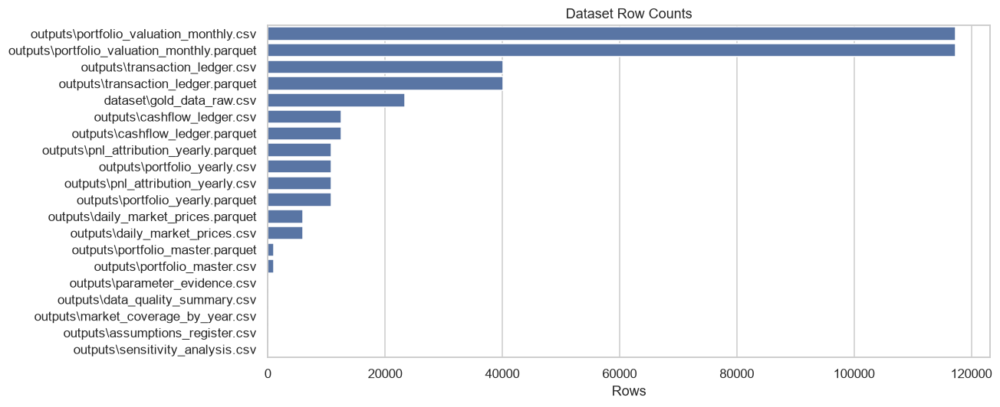

In [5]:
if not profile.empty:
    ax = sns.barplot(
        data=profile,
        x="rows",
        y="dataset"
    )
    ax.set_title("Dataset Row Counts")
    ax.set_xlabel("Rows")
    ax.set_ylabel("")
    plt.tight_layout()
    plt.show()

,dataset,column,missing_count,missing_pct
260,outputs\transaction_ledger.csv,rejection_reason,18337,45.74
78,outputs\parameter_evidence.csv,unit,5,23.81
83,outputs\parameter_evidence.csv,confidence,5,23.81
52,outputs\daily_market_prices.parquet,usd_thb,639,10.77
40,outputs\daily_market_prices.csv,usd_thb,639,10.77
39,outputs\daily_market_prices.csv,gold_spot_usd,496,8.36
51,outputs\daily_market_prices.parquet,gold_spot_usd,496,8.36
273,outputs\transaction_ledger.parquet,requested_quantity_bw,2441,6.09
275,outputs\transaction_ledger.parquet,price_quote_timestamp,2441,6.09
251,outputs\transaction_ledger.csv,requested_quantity_bw,2441,6.09


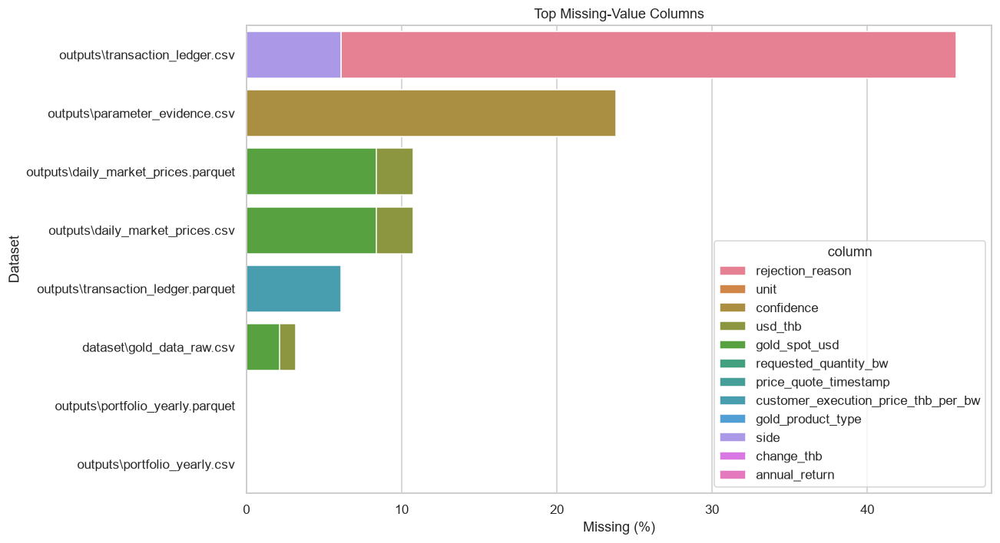

In [7]:
missing_parts = []

for name, df in datasets.items():
    missing = df.isna().sum()

    for col, count in missing.items():
        missing_parts.append({
            "dataset": name,
            "column": col,
            "missing_count": int(count),
            "missing_pct": round(
                count / max(len(df), 1) * 100, 2
            ),
        })

missing_df = pd.DataFrame(missing_parts)

if not missing_df.empty:
    missing_df = missing_df.query("missing_count > 0").sort_values(
        "missing_pct", ascending=False
    )

    display(missing_df.head(50))

    if not missing_df.empty:
        plt.figure(figsize=(12, max(4, min(12, len(missing_df.head(30)) * 0.3))))
        sns.barplot(
            data=missing_df.head(30),
            x="missing_pct",
            y="dataset",
            hue="column",
            dodge=False
        )
        plt.title("Top Missing-Value Columns")
        plt.xlabel("Missing (%)")
        plt.ylabel("Dataset")
        plt.tight_layout()
        plt.show()

In [8]:
keywords = [
    "date", "time", "timestamp", "price", "gold",
    "portfolio", "account", "user", "cohort", "archetype",
    "transaction", "event", "cash", "quantity", "unit",
    "pnl", "profit", "loss", "return", "drawdown",
    "cost", "effect", "state", "regime", "reason"
]

schema_rows = []

for name, df in datasets.items():
    for col in df.columns:
        matches = [
            kw for kw in keywords
            if kw in str(col).lower()
        ]

        schema_rows.append({
            "dataset": name,
            "column": col,
            "dtype": str(df[col].dtype),
            "n_unique": int(df[col].nunique(dropna=True)),
            "matched_keywords": ", ".join(matches),
        })

schema = pd.DataFrame(schema_rows)
display(schema)

,dataset,column,dtype,n_unique,matched_keywords
0,dataset\gold_data_raw.csv,timestamp,str,23359,"time, timestamp"
1,dataset\gold_data_raw.csv,announce_seq,int64,106,
2,dataset\gold_data_raw.csv,bar_buy_thb,float64,1320,
3,dataset\gold_data_raw.csv,bar_sell_thb,float64,1321,
4,dataset\gold_data_raw.csv,ornament_tax_base_thb,float64,1502,
...,...,...,...,...,...
283,outputs\transaction_ledger.parquet,behavior_scenario,str,8,
284,outputs\transaction_ledger.parquet,parameter_set_id,str,1,
285,outputs\transaction_ledger.parquet,simulation_run_id,str,1,
286,outputs\transaction_ledger.parquet,is_synthetic,bool,1,


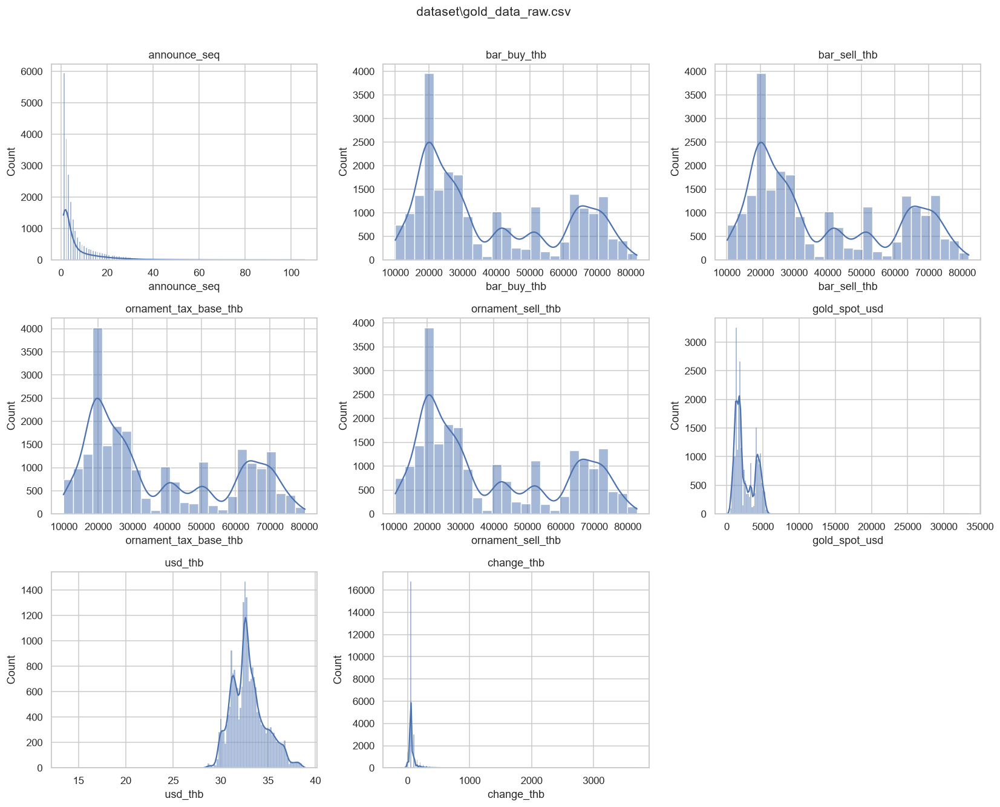

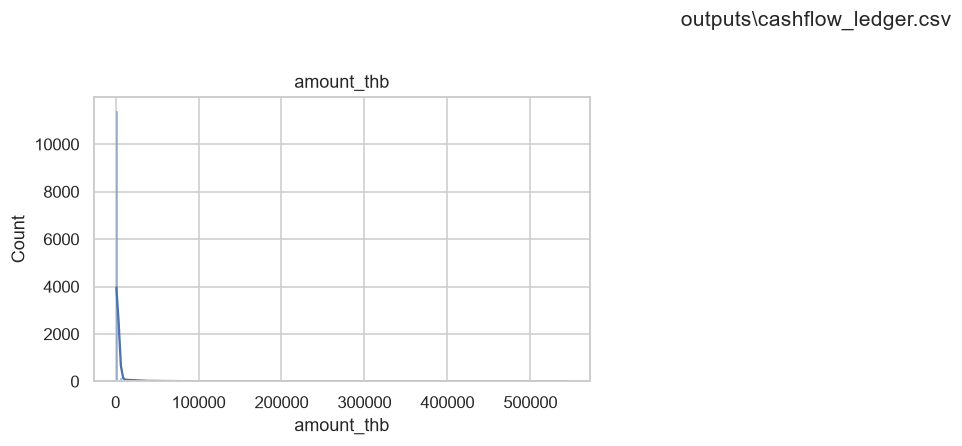

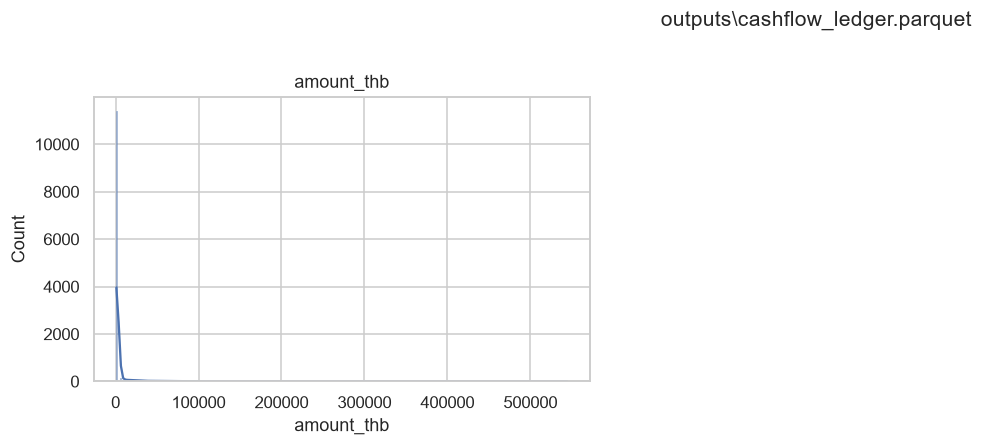

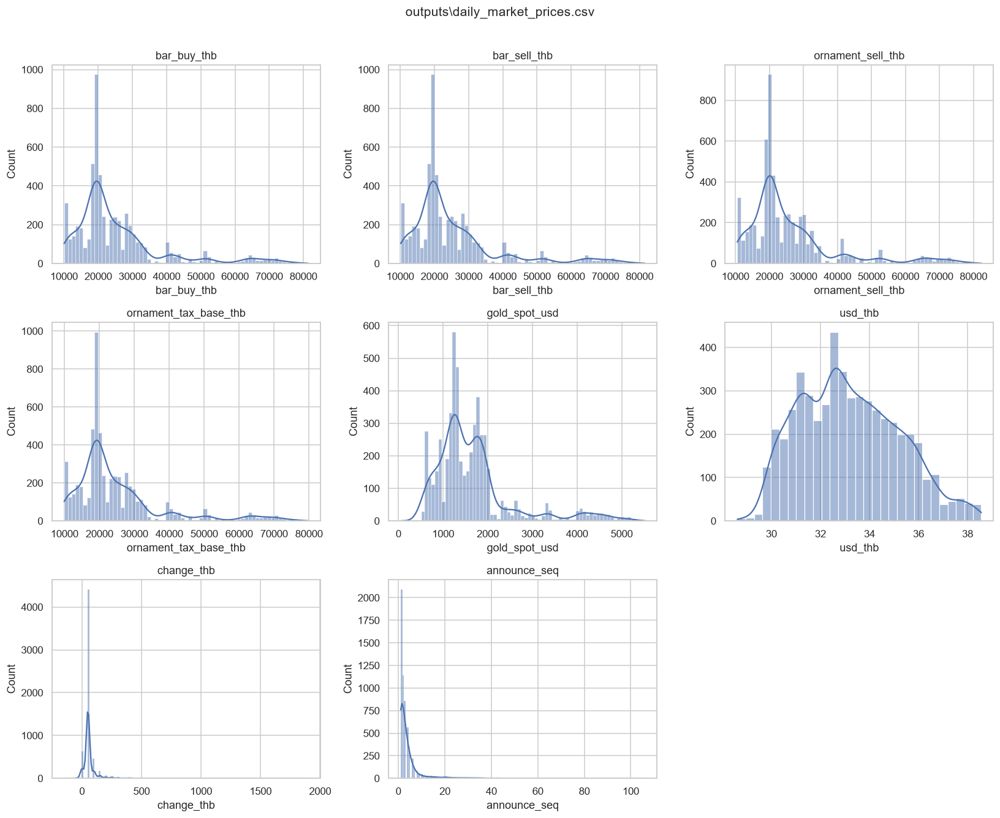

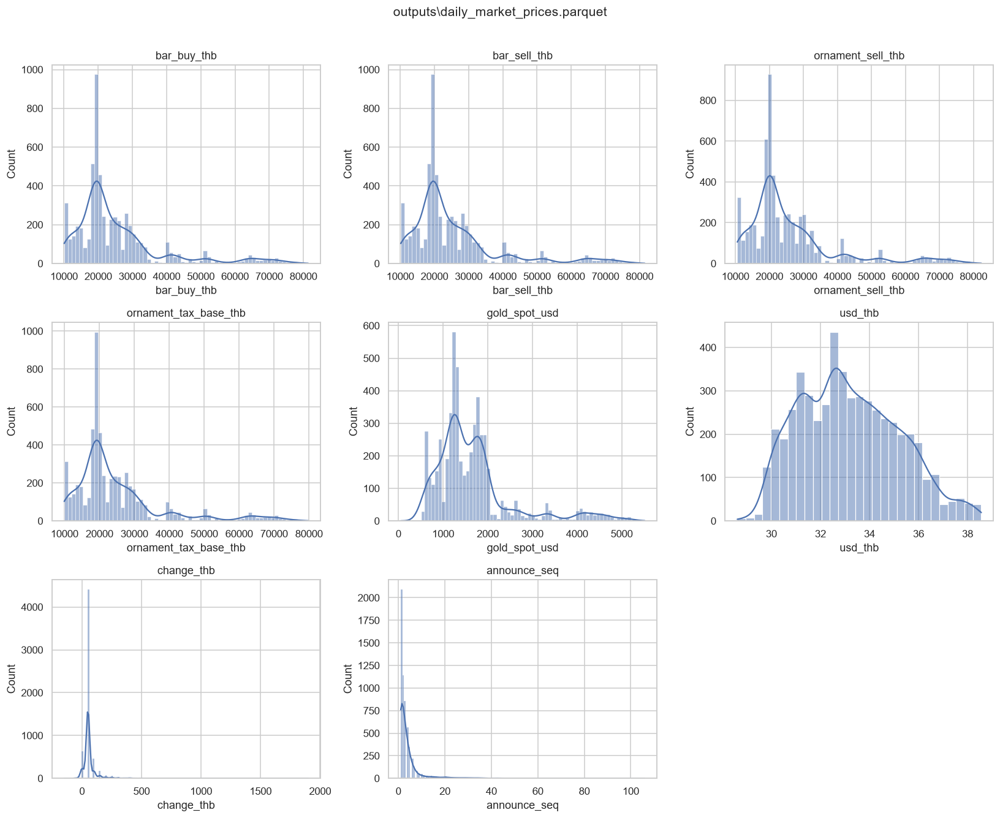

...

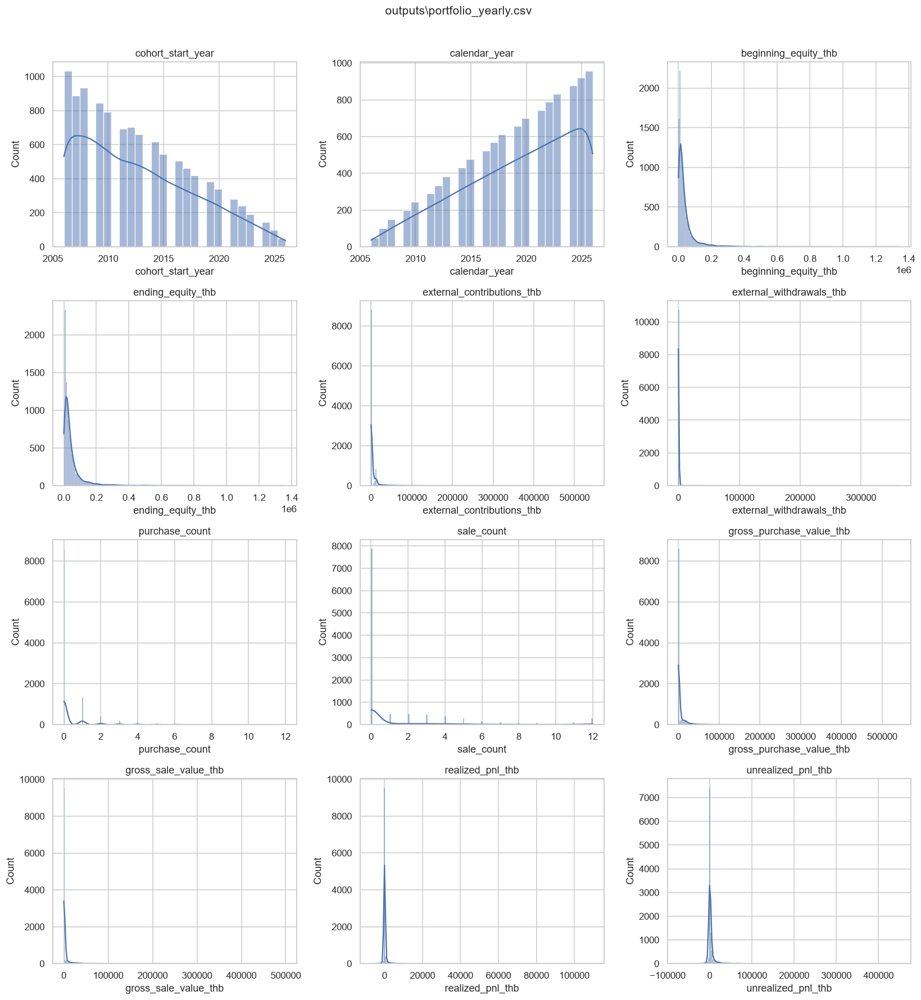

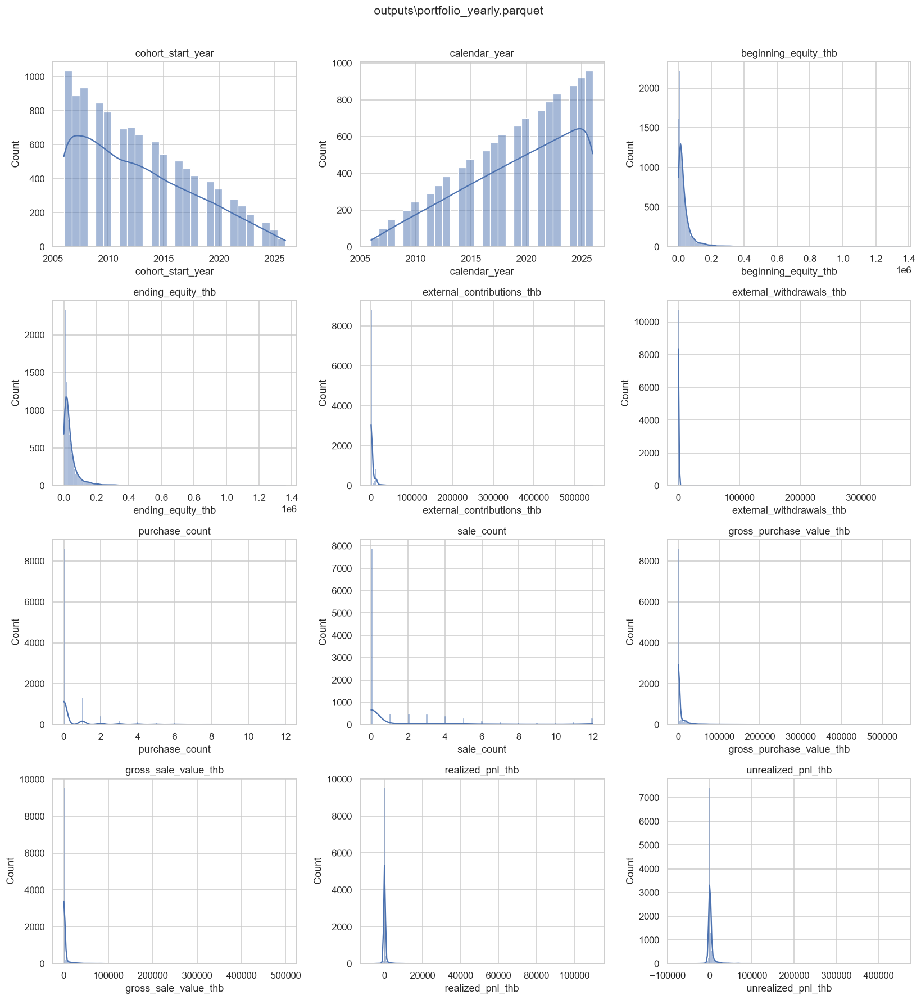

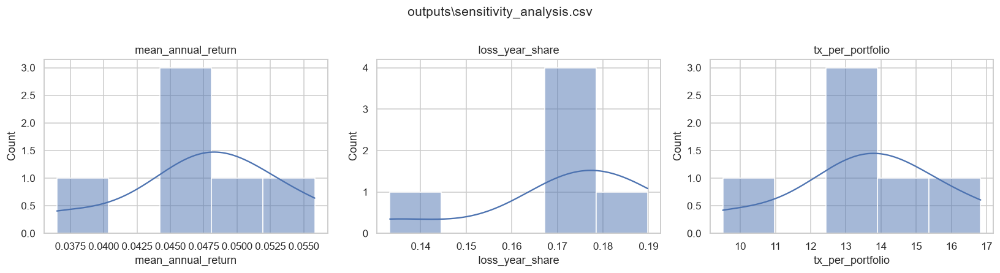

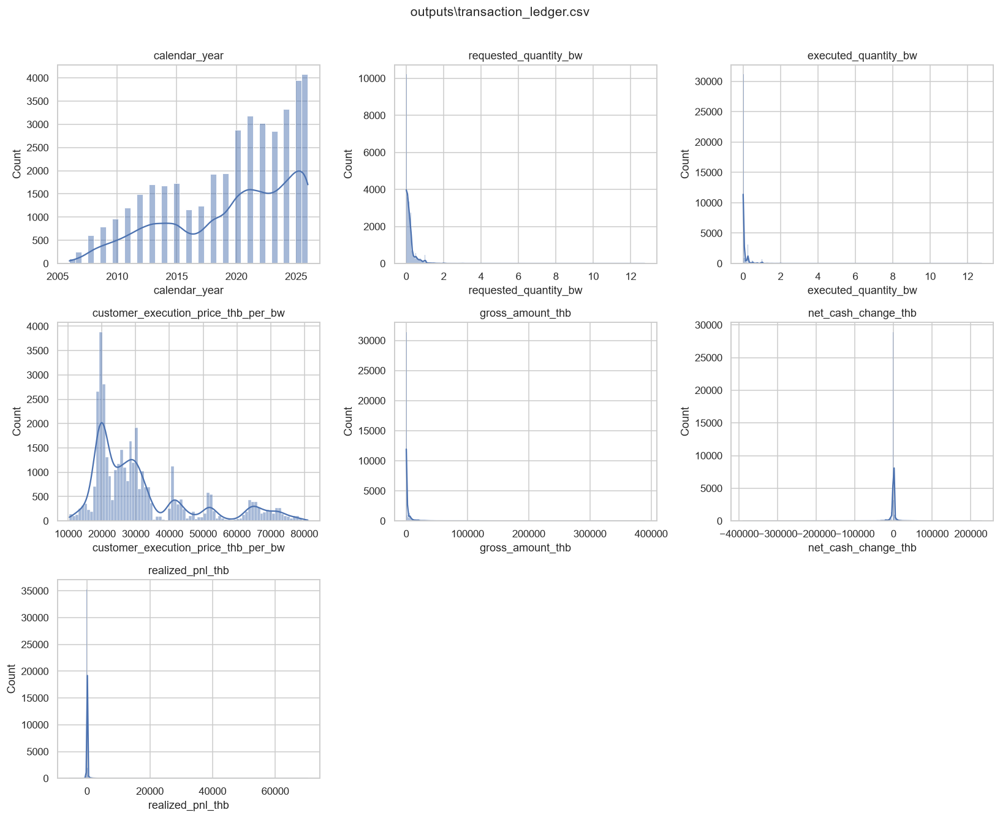

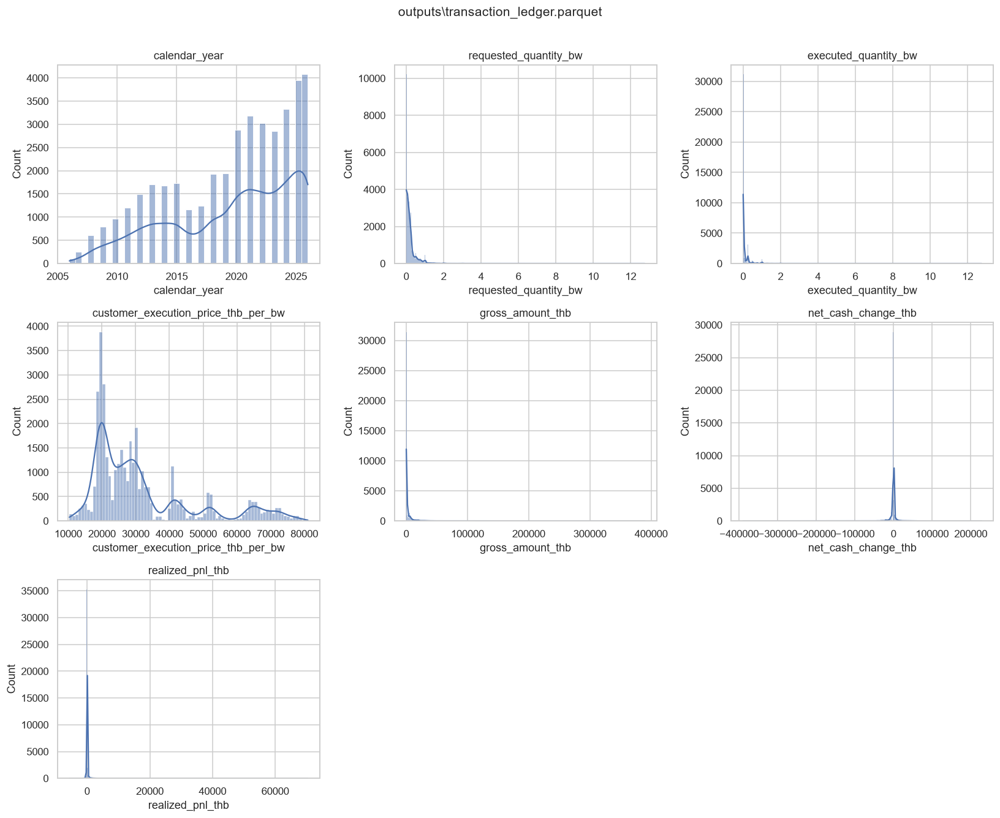

In [9]:
def plot_numeric_distributions(name, df, max_cols=12):
    numeric_cols = df.select_dtypes(include=np.number).columns.tolist()

    numeric_cols = [
        c for c in numeric_cols
        if df[c].nunique(dropna=True) > 5
    ][:max_cols]

    if not numeric_cols:
        return

    ncols = 3
    nrows = int(np.ceil(len(numeric_cols) / ncols))

    fig, axes = plt.subplots(
        nrows, ncols,
        figsize=(15, 4 * nrows)
    )
    axes = np.array(axes).reshape(-1)

    for ax, col in zip(axes, numeric_cols):
        sns.histplot(df[col].dropna(), kde=True, ax=ax)
        ax.set_title(f"{col}")
        ax.set_ylabel("Count")

    for ax in axes[len(numeric_cols):]:
        ax.set_visible(False)

    fig.suptitle(name, y=1.01, fontsize=14)
    plt.tight_layout()
    plt.show()


for name, df in datasets.items():
    plot_numeric_distributions(name, df)

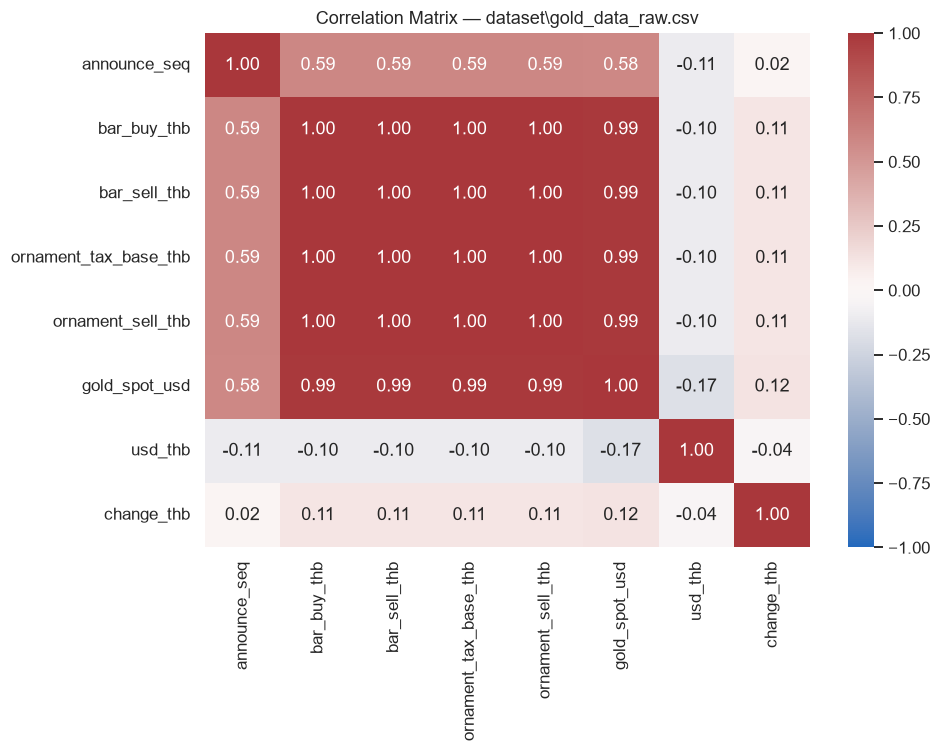

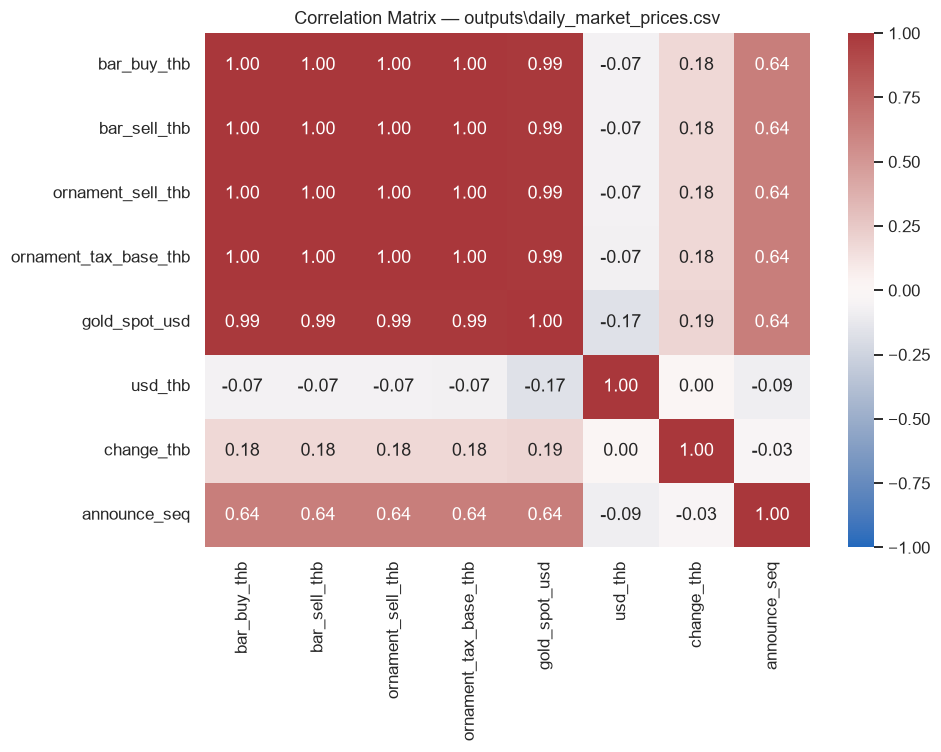

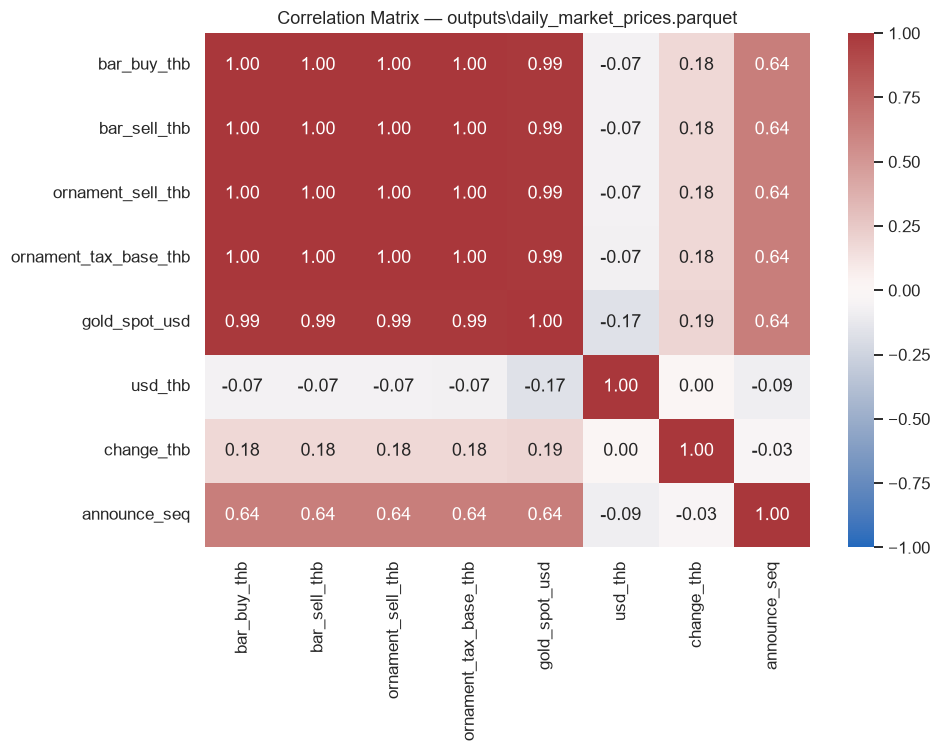

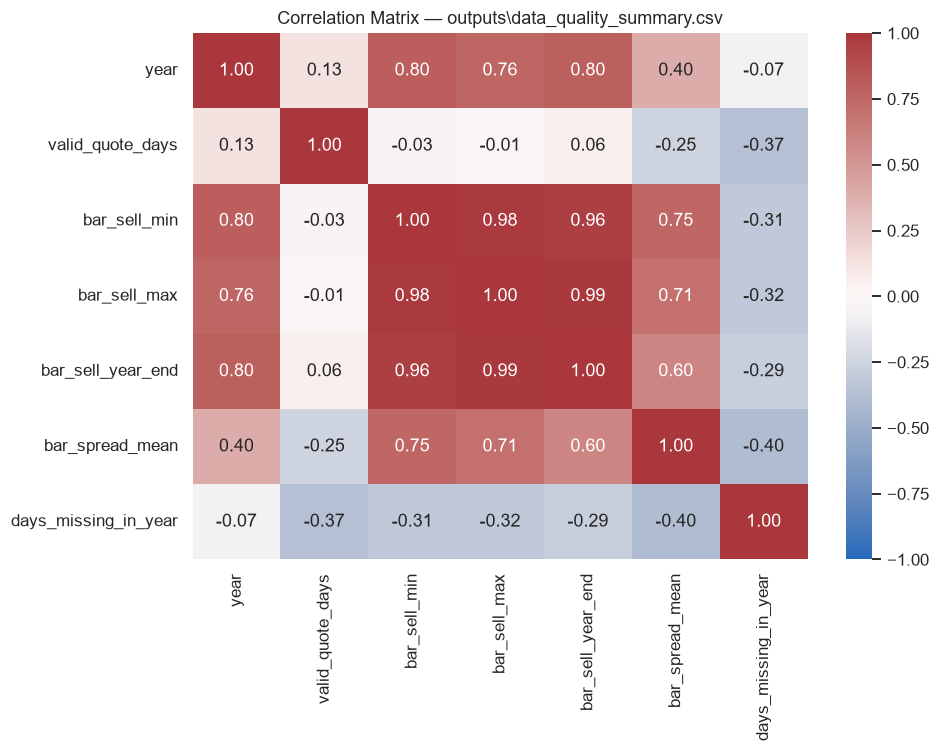

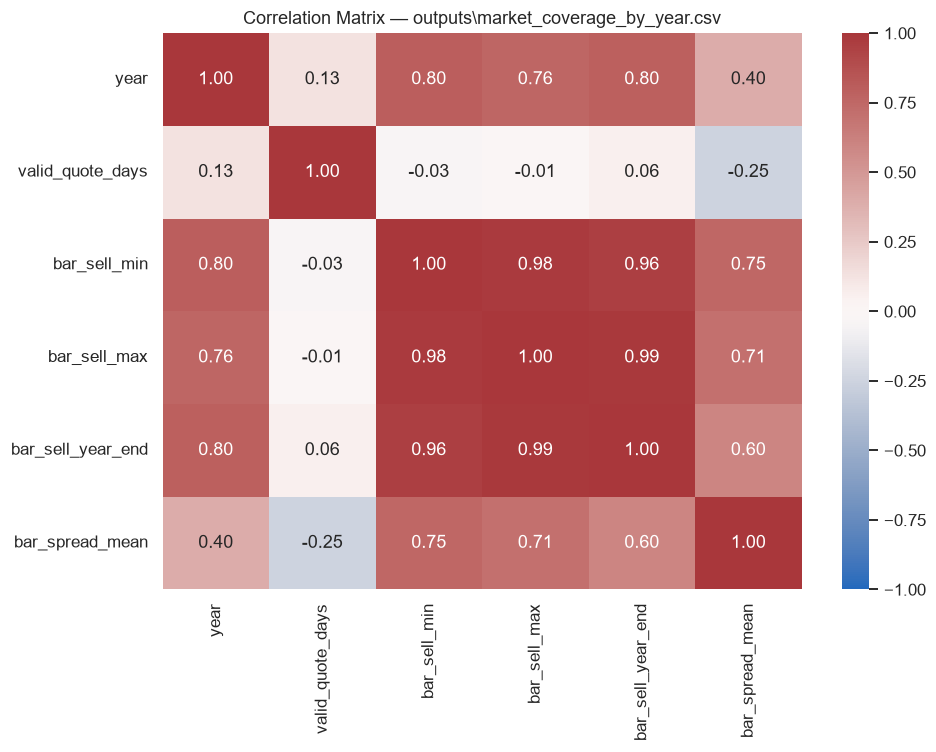

...

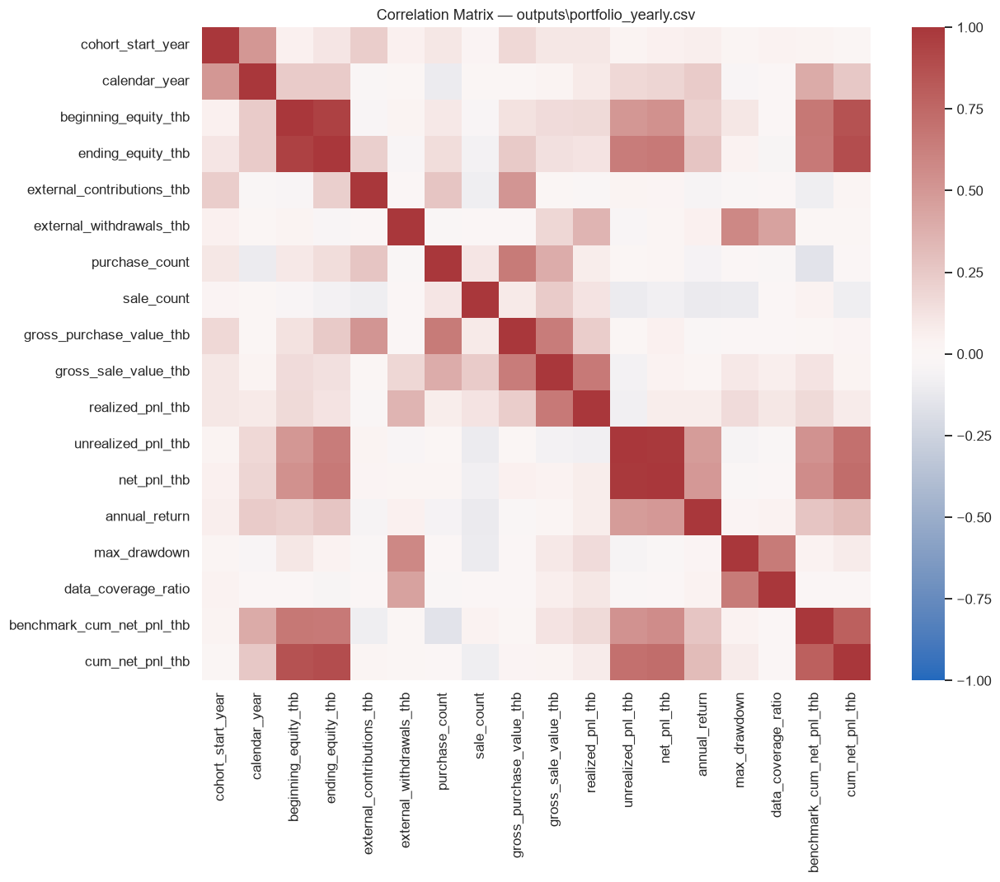

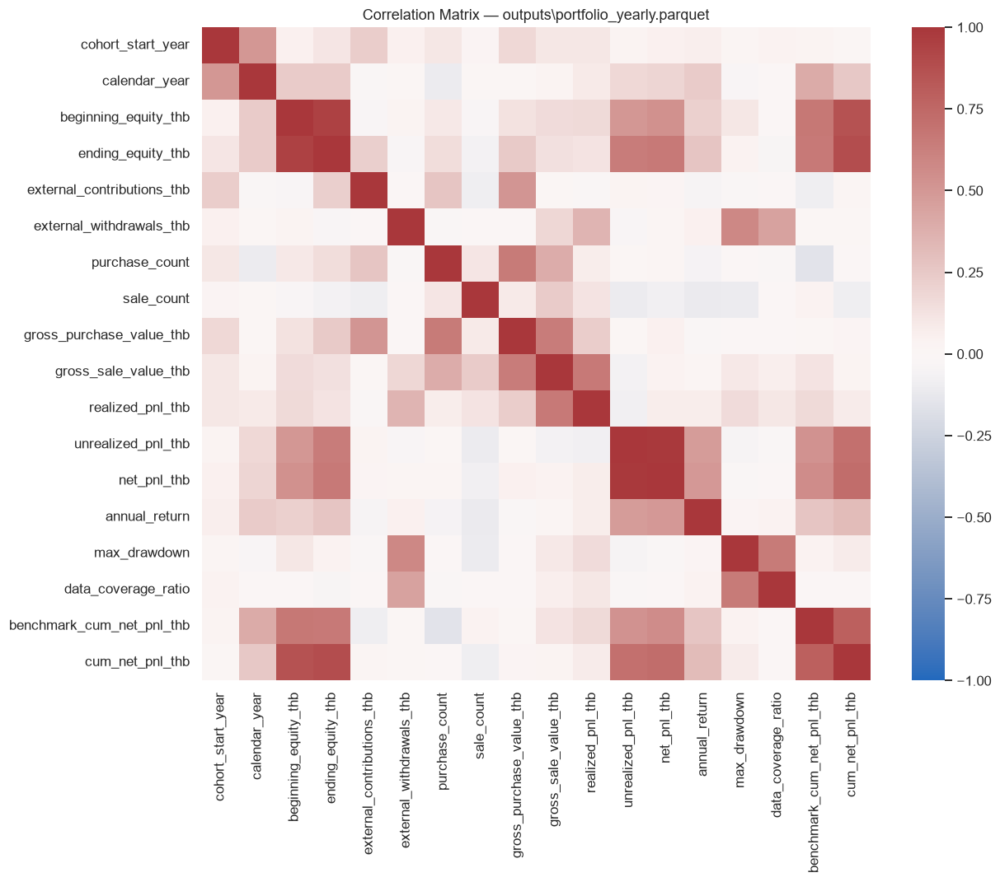

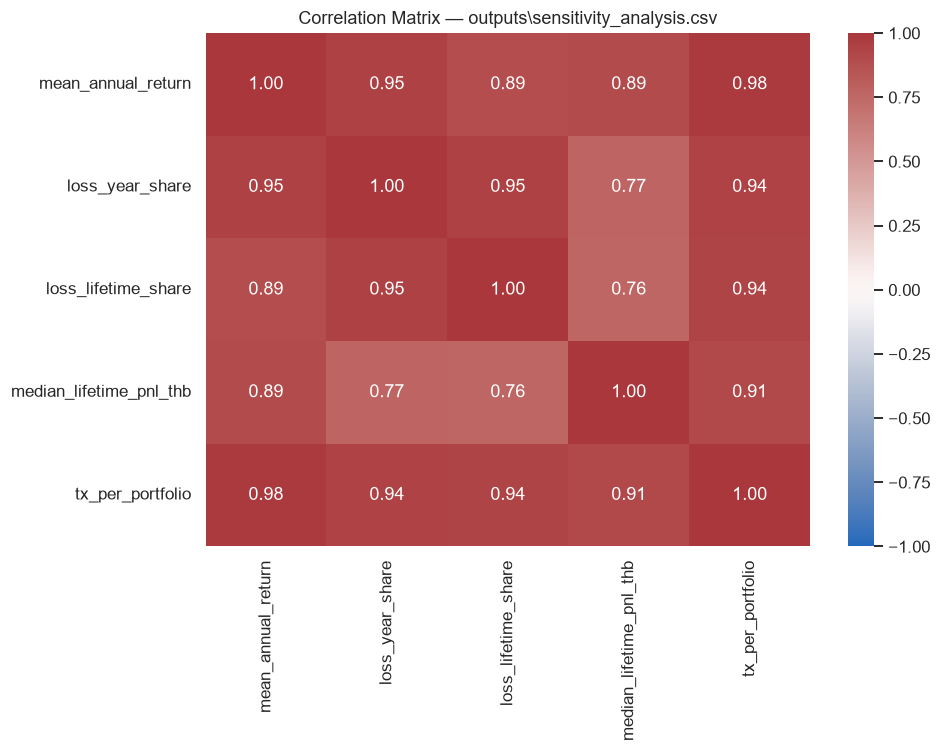

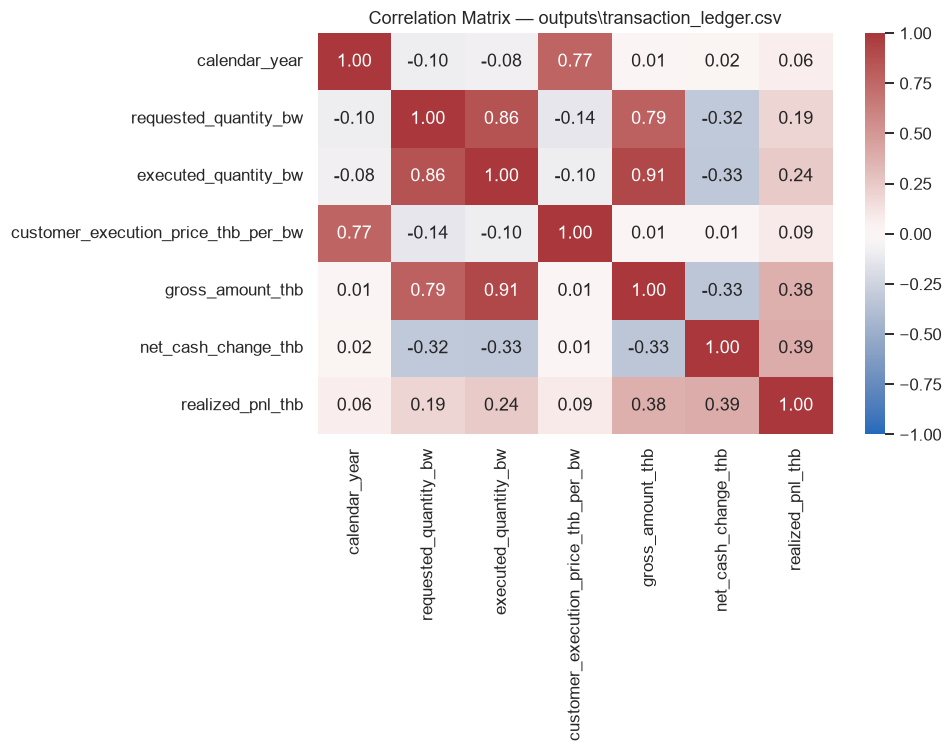

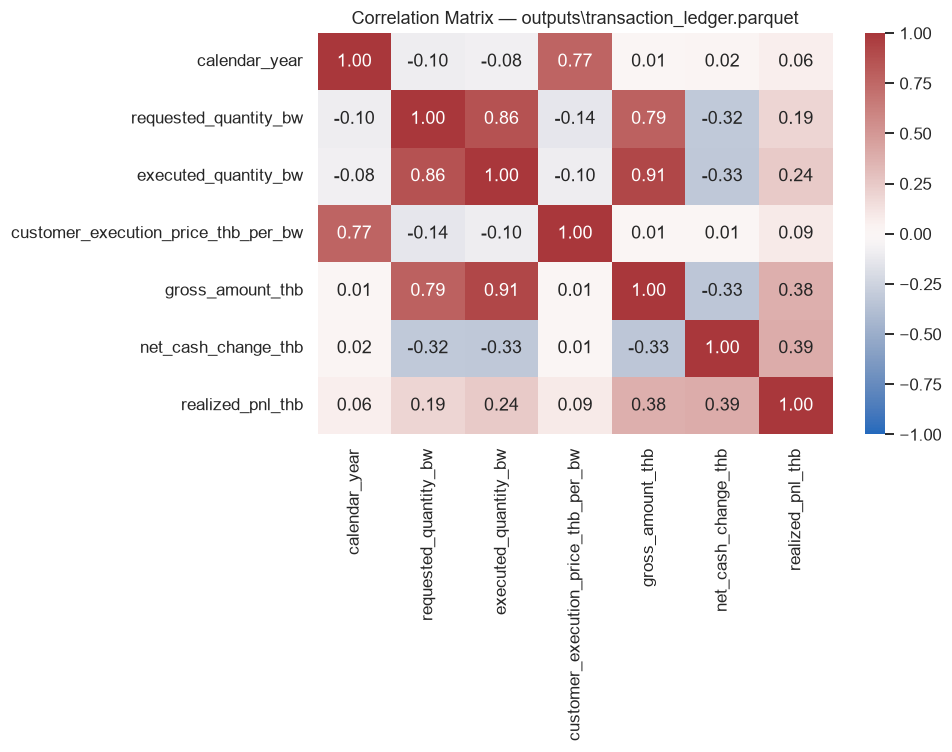

In [10]:
def plot_correlation(name, df, max_cols=20):
    num = df.select_dtypes(include=np.number)

    num = num.loc[:, num.nunique(dropna=True) > 1]

    if num.shape[1] < 2:
        return

    # เลือกคอลัมน์ที่มีความแปรปรวนมากที่สุด หากมีคอลัมน์เยอะ
    if num.shape[1] > max_cols:
        variances = num.var(numeric_only=True).sort_values(
            ascending=False
        )
        num = num[variances.head(max_cols).index]

    corr = num.corr()

    plt.figure(figsize=(
        max(9, len(corr.columns) * 0.65),
        max(7, len(corr.columns) * 0.55)
    ))

    sns.heatmap(
        corr,
        cmap="vlag",
        center=0,
        vmin=-1,
        vmax=1,
        annot=len(corr.columns) <= 12,
        fmt=".2f"
    )

    plt.title(f"Correlation Matrix — {name}")
    plt.tight_layout()
    plt.show()


for name, df in datasets.items():
    plot_correlation(name, df)

In [11]:
price_candidates = []

for name, df in datasets.items():
    cols = {str(c).lower() for c in df.columns}

    has_price = any(
        ("price" in c) or ("gold" in c)
        or (c in {"bar_buy", "bar_sell", "ornament_buy", "ornament_sell"})
        for c in cols
    )

    has_time = any(
        ("date" in c) or ("time" in c)
        or ("timestamp" in c)
        for c in cols
    )

    if has_price and has_time:
        price_candidates.append(name)

print("Possible price datasets:")
for i, name in enumerate(price_candidates):
    print(i, name, datasets[name].shape)

Possible price datasets:
0 dataset\gold_data_raw.csv (23385, 10)
1 outputs\daily_market_prices.csv (5933, 12)
2 outputs\daily_market_prices.parquet (5933, 12)
3 outputs\portfolio_master.csv (1050, 16)
4 outputs\portfolio_master.parquet (1050, 16)
5 outputs\portfolio_valuation_monthly.csv (117356, 18)
6 outputs\portfolio_valuation_monthly.parquet (117356, 18)
7 outputs\transaction_ledger.csv (40089, 22)
8 outputs\transaction_ledger.parquet (40089, 22)


In [12]:
# แก้ index ให้เป็นตารางราคาที่ถูกต้อง
PRICE_DATASET_INDEX = 0

if not price_candidates:
    raise ValueError("ไม่พบ Dataset ที่มีทั้งคอลัมน์เวลาและราคา")

price_name = price_candidates[PRICE_DATASET_INDEX]
price_df = datasets[price_name].copy()

print("Selected:", price_name)
display(price_df.head())

Selected: dataset\gold_data_raw.csv


,timestamp,announce_seq,bar_buy_thb,bar_sell_thb,ornament_tax_base_thb,ornament_sell_thb,gold_spot_usd,usd_thb,change_thb,source_url
0,2006-05-01 09:30:00,1,11450.0,11550.0,11279.04,11950.0,648.64,37.33,0.0,https://xn--42cah7d0cxcvbbb9x.com/%E0%B8%A3%E0...
1,2006-05-02 09:30:00,1,11500.0,11600.0,11339.68,12000.0,656.25,37.61,50.0,https://xn--42cah7d0cxcvbbb9x.com/%E0%B8%A3%E0...
2,2006-05-02 11:50:00,2,11550.0,11650.0,11385.16,12050.0,657.05,NaN,50.0,https://xn--42cah7d0cxcvbbb9x.com/%E0%B8%A3%E0...
3,2006-05-03 09:30:00,1,11750.0,11850.0,11582.24,12250.0,668.90,37.58,200.0,https://xn--42cah7d0cxcvbbb9x.com/%E0%B8%A3%E0...
4,2006-05-03 10:45:00,2,11900.0,12000.0,11733.84,12400.0,675.90,37.61,150.0,https://xn--42cah7d0cxcvbbb9x.com/%E0%B8%A3%E0...


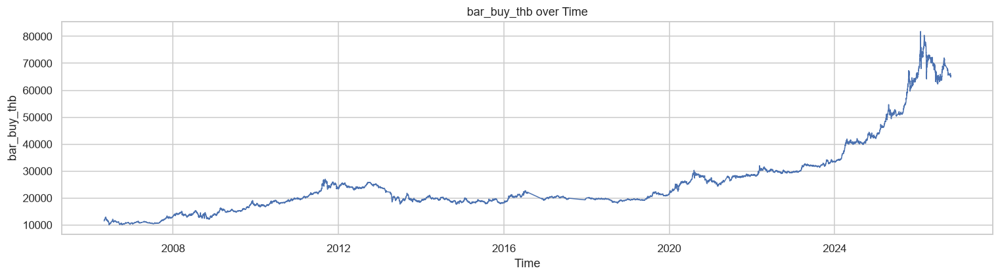

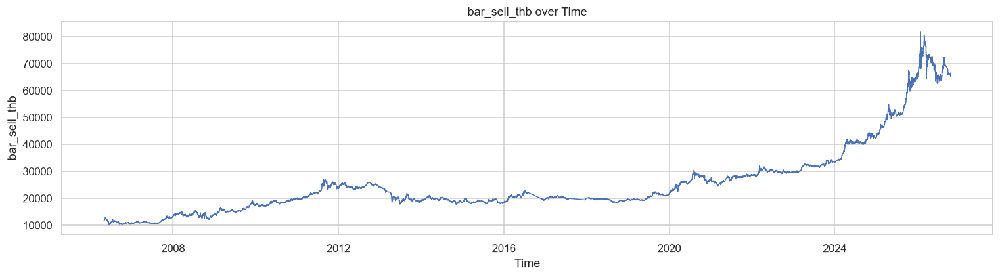

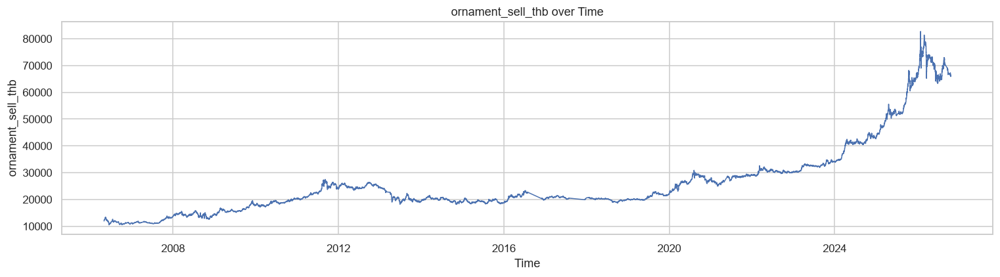

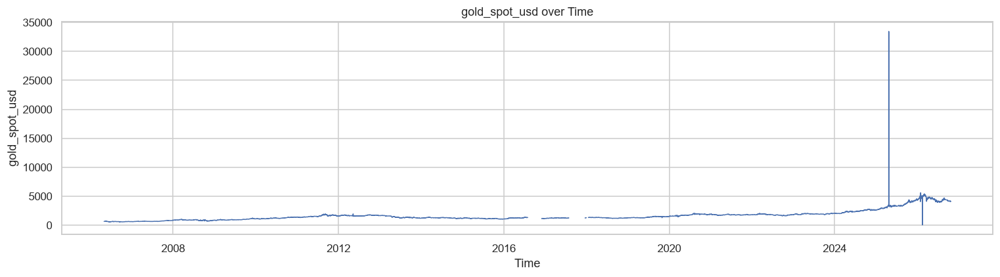

In [13]:
time_cols = [
    c for c in price_df.columns
    if any(k in str(c).lower() for k in ["timestamp", "datetime"])
]

if not time_cols:
    date_col = next(
        (c for c in price_df.columns if "date" in str(c).lower()),
        None
    )
    time_col = next(
        (c for c in price_df.columns if str(c).lower() == "time"),
        None
    )

    if date_col:
        if time_col:
            price_df["_datetime"] = pd.to_datetime(
                price_df[date_col].astype(str) + " " +
                price_df[time_col].astype(str),
                errors="coerce"
            )
        else:
            price_df["_datetime"] = pd.to_datetime(
                price_df[date_col], errors="coerce"
            )
    else:
        price_df["_datetime"] = pd.NaT
else:
    price_df["_datetime"] = pd.to_datetime(
        price_df[time_cols[0]], errors="coerce"
    )

price_cols = [
    c for c in price_df.select_dtypes(include=np.number).columns
    if any(k in str(c).lower() for k in ["price", "gold", "buy", "sell", "spot"])
]

price_cols = [
    c for c in price_cols
    if price_df[c].nunique(dropna=True) > 5
]

if price_df["_datetime"].notna().any() and price_cols:
    plot_df = price_df.sort_values("_datetime")

    for col in price_cols[:8]:
        plt.figure(figsize=(14, 4))
        plt.plot(
            plot_df["_datetime"],
            plot_df[col],
            linewidth=1
        )
        plt.title(f"{col} over Time")
        plt.xlabel("Time")
        plt.ylabel(col)
        plt.tight_layout()
        plt.show()

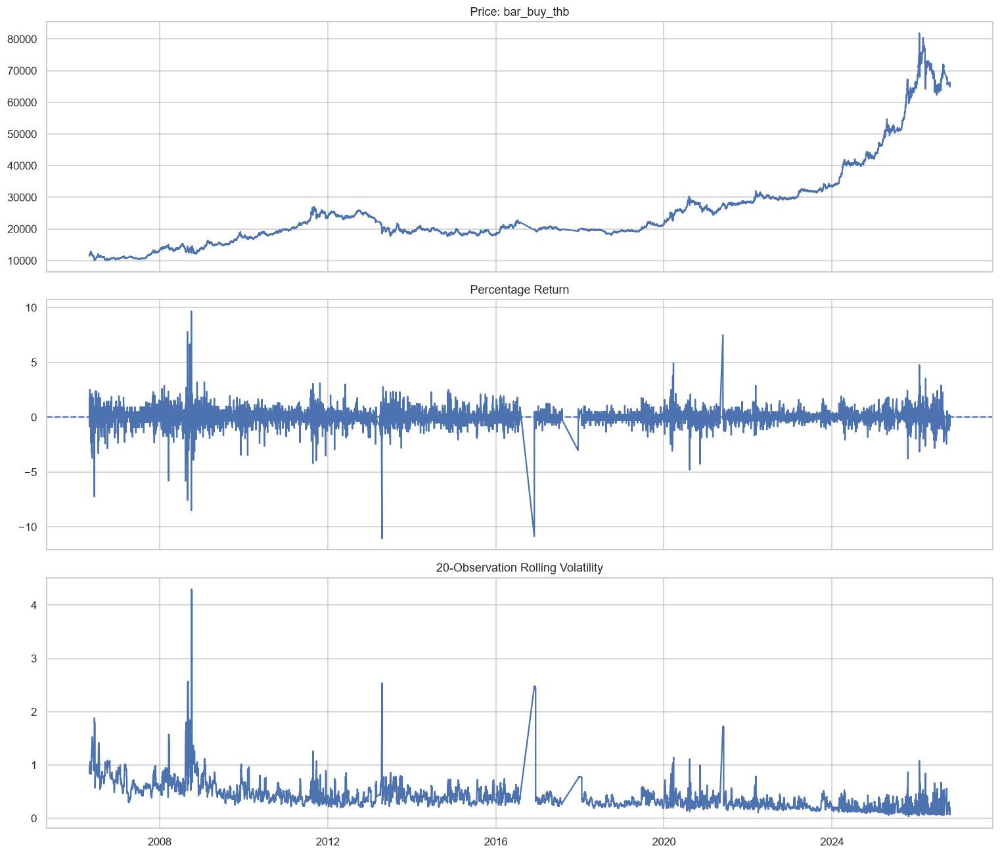

In [14]:
if "_datetime" in price_df.columns and price_df["_datetime"].notna().any():
    plot_df = price_df.sort_values("_datetime").copy()

    candidate_price = next(
        (
            c for c in price_cols
            if str(c).lower() in {"bar_buy", "gold_spot", "gold_price"}
        ),
        price_cols[0] if price_cols else None
    )

    if candidate_price:
        plot_df[candidate_price] = pd.to_numeric(
            plot_df[candidate_price], errors="coerce"
        )

        plot_df["return_pct"] = (
            plot_df[candidate_price].pct_change() * 100
        )

        plot_df["rolling_volatility"] = (
            plot_df["return_pct"]
            .rolling(20, min_periods=5)
            .std()
        )

        fig, axes = plt.subplots(3, 1, figsize=(14, 12), sharex=True)

        axes[0].plot(plot_df["_datetime"], plot_df[candidate_price])
        axes[0].set_title(f"Price: {candidate_price}")

        axes[1].plot(plot_df["_datetime"], plot_df["return_pct"])
        axes[1].axhline(0, linestyle="--")
        axes[1].set_title("Percentage Return")

        axes[2].plot(
            plot_df["_datetime"],
            plot_df["rolling_volatility"]
        )
        axes[2].set_title("20-Observation Rolling Volatility")

        plt.tight_layout()
        plt.show()

In [15]:
def find_datasets_by_keywords(keywords):
    found = []

    for name, df in datasets.items():
        cols = [str(c).lower() for c in df.columns]

        if any(
            keyword in name.lower()
            or any(keyword in col for col in cols)
            for keyword in keywords
        ):
            found.append(name)

    return found


transaction_candidates = find_datasets_by_keywords(
    ["transaction", "event", "trade", "order"]
)

portfolio_candidates = find_datasets_by_keywords(
    ["portfolio", "account", "snapshot", "valuation"]
)

pnl_candidates = find_datasets_by_keywords(
    ["pnl", "profit", "loss", "attribution"]
)

print("Transaction candidates:", transaction_candidates)
print("Portfolio candidates:", portfolio_candidates)
print("P&L candidates:", pnl_candidates)

Transaction candidates: ['outputs\\cashflow_ledger.csv', 'outputs\\cashflow_ledger.parquet', 'outputs\\pnl_attribution_yearly.csv', 'outputs\\pnl_attribution_yearly.parquet', 'outputs\\portfolio_valuation_monthly.csv', 'outputs\\portfolio_valuation_monthly.parquet', 'outputs\\portfolio_yearly.csv', 'outputs\\portfolio_yearly.parquet', 'outputs\\transaction_ledger.csv', 'outputs\\transaction_ledger.parquet']
Portfolio candidates: ['outputs\\cashflow_ledger.csv', 'outputs\\cashflow_ledger.parquet', 'outputs\\pnl_attribution_yearly.csv', 'outputs\\pnl_attribution_yearly.parquet', 'outputs\\portfolio_master.csv', 'outputs\\portfolio_master.parquet', 'outputs\\portfolio_valuation_monthly.csv', 'outputs\\portfolio_valuation_monthly.parquet', 'outputs\\portfolio_yearly.csv', 'outputs\\portfolio_yearly.parquet', 'outputs\\sensitivity_analysis.csv', 'outputs\\transaction_ledger.csv', 'outputs\\transaction_ledger.parquet']
P&L candidates: ['outputs\\pnl_attribution_yearly.csv', 'outputs\\pnl_att


### Transactions

outputs\cashflow_ledger.csv: (12566, 8)


,cashflow_id,portfolio_id,event_timestamp,cashflow_type,amount_thb,reason_or_scenario,simulation_run_id,is_synthetic
0,P20060001-C00001,P20060001,2006-06-08,initial_contribution,6000.00,initial funding (synthetic),R001,True
1,P20060002-C00002,P20060002,2006-11-18,initial_contribution,6000.00,initial funding (synthetic),R001,True
2,P20060003-C00003,P20060003,2006-05-29,initial_contribution,8506.68,initial funding (synthetic),R001,True
3,P20060004-C00004,P20060004,2006-11-08,initial_contribution,8272.88,initial funding (synthetic),R001,True
4,P20060005-C00005,P20060005,2006-10-06,initial_contribution,13494.22,initial funding (synthetic),R001,True


,count,mean,std,min,25%,50%,75%,max
amount_thb,12566.0,4456.715013,18399.593241,1000.0,1000.0,1000.0,1000.0,544523.64


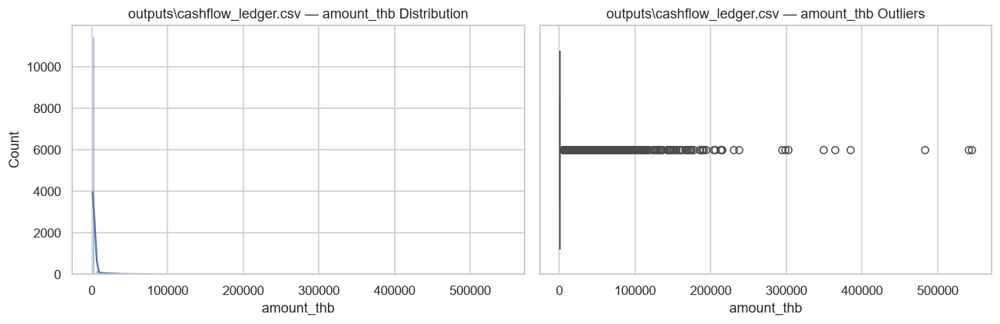


outputs\cashflow_ledger.parquet: (12566, 8)


,cashflow_id,portfolio_id,event_timestamp,cashflow_type,amount_thb,reason_or_scenario,simulation_run_id,is_synthetic
0,P20060001-C00001,P20060001,2006-06-08,initial_contribution,6000.00,initial funding (synthetic),R001,True
1,P20060002-C00002,P20060002,2006-11-18,initial_contribution,6000.00,initial funding (synthetic),R001,True
2,P20060003-C00003,P20060003,2006-05-29,initial_contribution,8506.68,initial funding (synthetic),R001,True
3,P20060004-C00004,P20060004,2006-11-08,initial_contribution,8272.88,initial funding (synthetic),R001,True
4,P20060005-C00005,P20060005,2006-10-06,initial_contribution,13494.22,initial funding (synthetic),R001,True


,count,mean,std,min,25%,50%,75%,max
amount_thb,12566.0,4456.715013,18399.593241,1000.0,1000.0,1000.0,1000.0,544523.64


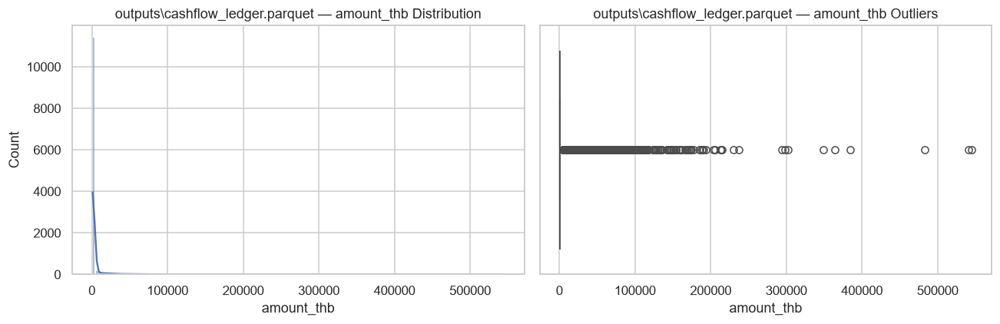


outputs\pnl_attribution_yearly.csv: (10845, 14)


,portfolio_id,calendar_year,pnl_total_thb,price_effect_thb,trading_timing_effect_thb,transaction_cost_effect_thb,product_cost_effect_thb,other_modeled_effect_thb,unattributed_residual_thb,benchmark_id,attribution_method,attribution_quality_flag,simulation_run_id,is_synthetic
0,P20060001,2006,0.0,0.0,0.0,-0.0,0.0,0.0,0.0,BH_BAR_SAME_FLOWS,unit_lifecycle_vs_liquidation_quotes_v1,RECONCILED,R001,True
1,P20060001,2007,0.0,0.0,0.0,-0.0,0.0,0.0,0.0,BH_BAR_SAME_FLOWS,unit_lifecycle_vs_liquidation_quotes_v1,RECONCILED,R001,True
2,P20060001,2008,0.0,0.0,0.0,-0.0,0.0,0.0,0.0,BH_BAR_SAME_FLOWS,unit_lifecycle_vs_liquidation_quotes_v1,RECONCILED,R001,True
3,P20060001,2009,0.0,0.0,0.0,-0.0,0.0,0.0,0.0,BH_BAR_SAME_FLOWS,unit_lifecycle_vs_liquidation_quotes_v1,RECONCILED,R001,True
4,P20060001,2010,0.0,0.0,0.0,-0.0,0.0,0.0,0.0,BH_BAR_SAME_FLOWS,unit_lifecycle_vs_liquidation_quotes_v1,RECONCILED,R001,True


,count,mean,std,min,25%,50%,75%,max
calendar_year,10845.0,2.019230e+03,5.089687,2.006000e+03,2016.0,2020.0,2024.0,2026.000000
pnl_total_thb,10845.0,3.593407e+03,16212.375614,-6.198750e+04,0.0,150.0,1800.0,451000.000000
price_effect_thb,10845.0,3.665277e+03,16217.127869,-5.771250e+04,0.0,200.0,1800.0,451000.000000
trading_timing_effect_thb,10845.0,-2.135085e+01,71.915684,-2.000000e+03,0.0,0.0,0.0,0.000000
transaction_cost_effect_thb,10845.0,0.000000e+00,0.000000,-0.000000e+00,0.0,0.0,0.0,-0.000000
product_cost_effect_thb,10845.0,-5.051867e+01,187.328603,-5.100000e+03,0.0,0.0,0.0,0.000000
other_modeled_effect_thb,10845.0,0.000000e+00,0.000000,0.000000e+00,0.0,0.0,0.0,0.000000
unattributed_residual_thb,10845.0,1.440575e-07,0.000002,-2.910383e-11,0.0,0.0,0.0,0.000023


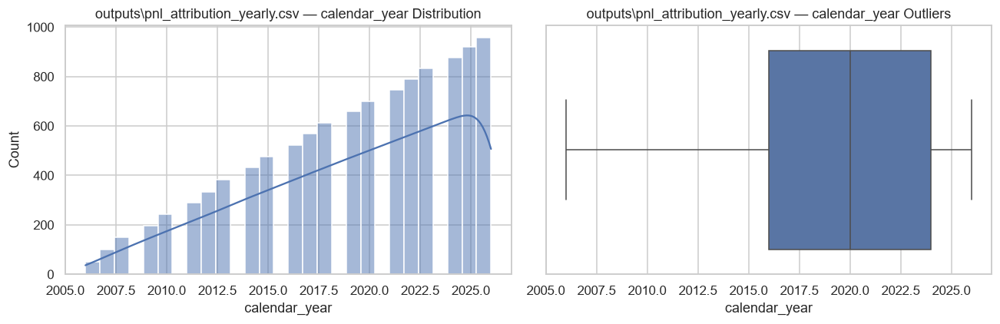

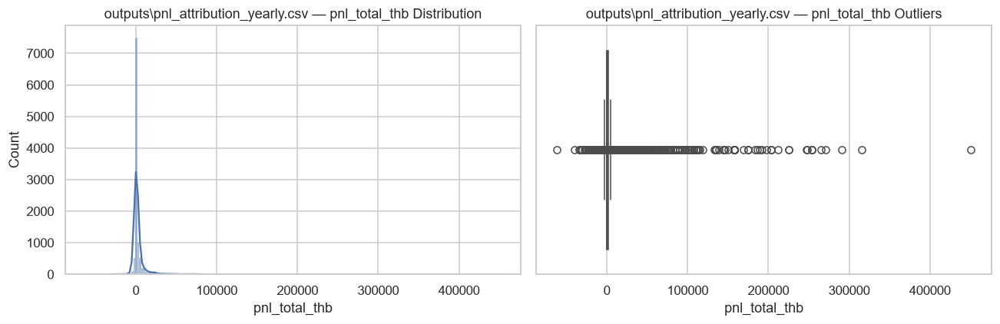

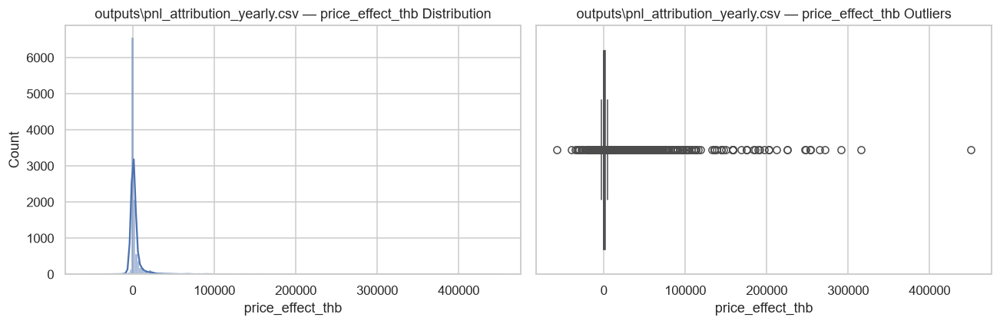

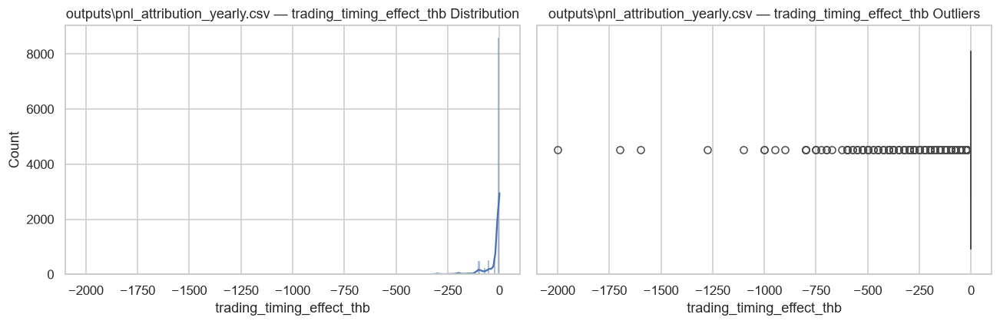

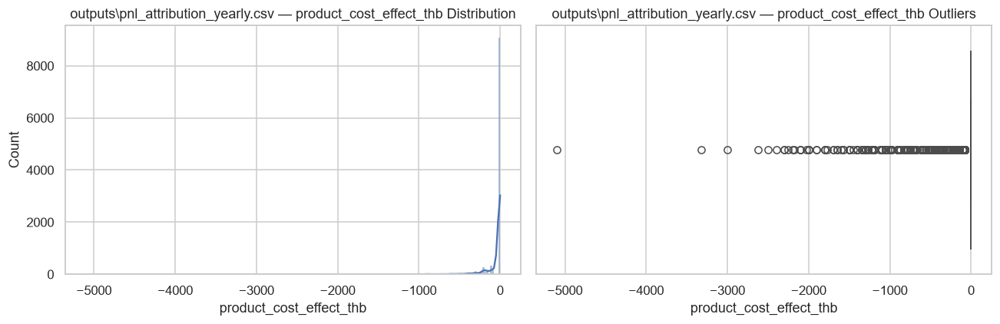


outputs\pnl_attribution_yearly.parquet: (10845, 14)


,portfolio_id,calendar_year,pnl_total_thb,price_effect_thb,trading_timing_effect_thb,transaction_cost_effect_thb,product_cost_effect_thb,other_modeled_effect_thb,unattributed_residual_thb,benchmark_id,attribution_method,attribution_quality_flag,simulation_run_id,is_synthetic
0,P20060001,2006,0.0,0.0,0.0,-0.0,0.0,0.0,0.0,BH_BAR_SAME_FLOWS,unit_lifecycle_vs_liquidation_quotes_v1,RECONCILED,R001,True
1,P20060001,2007,0.0,0.0,0.0,-0.0,0.0,0.0,0.0,BH_BAR_SAME_FLOWS,unit_lifecycle_vs_liquidation_quotes_v1,RECONCILED,R001,True
2,P20060001,2008,0.0,0.0,0.0,-0.0,0.0,0.0,0.0,BH_BAR_SAME_FLOWS,unit_lifecycle_vs_liquidation_quotes_v1,RECONCILED,R001,True
3,P20060001,2009,0.0,0.0,0.0,-0.0,0.0,0.0,0.0,BH_BAR_SAME_FLOWS,unit_lifecycle_vs_liquidation_quotes_v1,RECONCILED,R001,True
4,P20060001,2010,0.0,0.0,0.0,-0.0,0.0,0.0,0.0,BH_BAR_SAME_FLOWS,unit_lifecycle_vs_liquidation_quotes_v1,RECONCILED,R001,True


,count,mean,std,min,25%,50%,75%,max
calendar_year,10845.0,2.019230e+03,5.089687,2.006000e+03,2016.0,2020.0,2024.0,2026.000000
pnl_total_thb,10845.0,3.593407e+03,16212.375614,-6.198750e+04,0.0,150.0,1800.0,451000.000000
price_effect_thb,10845.0,3.665277e+03,16217.127869,-5.771250e+04,0.0,200.0,1800.0,451000.000000
trading_timing_effect_thb,10845.0,-2.135085e+01,71.915684,-2.000000e+03,0.0,0.0,0.0,0.000000
transaction_cost_effect_thb,10845.0,0.000000e+00,0.000000,-0.000000e+00,0.0,0.0,0.0,-0.000000
product_cost_effect_thb,10845.0,-5.051867e+01,187.328603,-5.100000e+03,0.0,0.0,0.0,0.000000
other_modeled_effect_thb,10845.0,0.000000e+00,0.000000,0.000000e+00,0.0,0.0,0.0,0.000000
unattributed_residual_thb,10845.0,1.440575e-07,0.000002,-2.910383e-11,0.0,0.0,0.0,0.000023


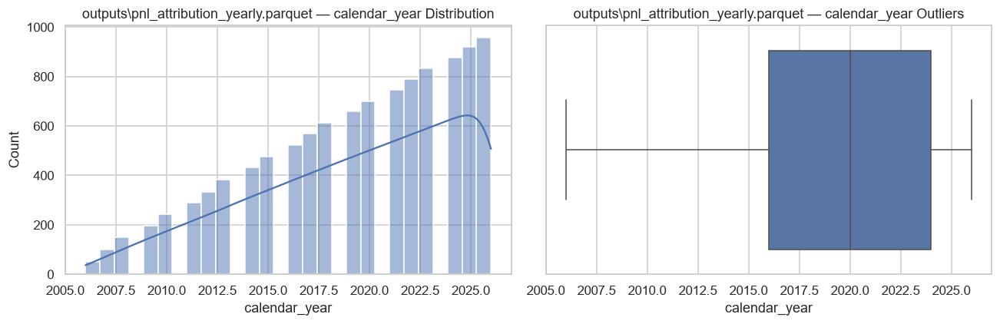

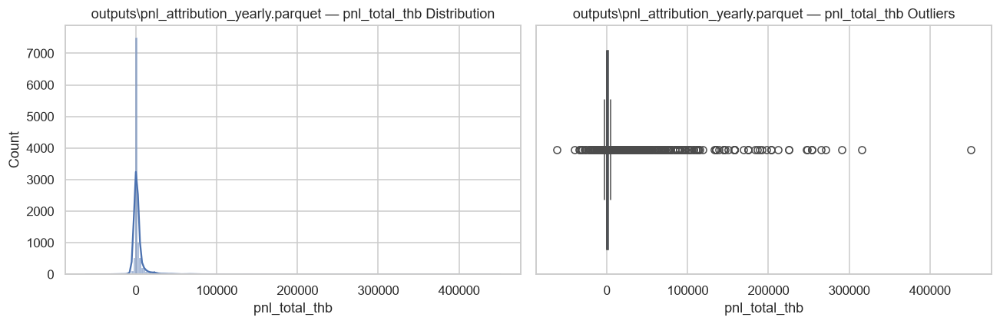

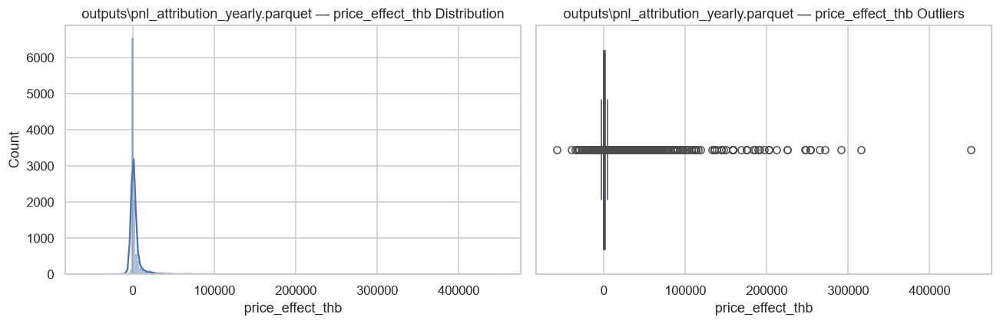

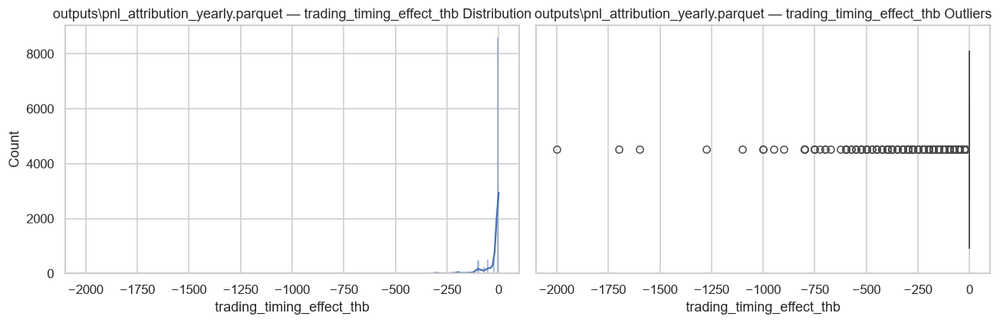

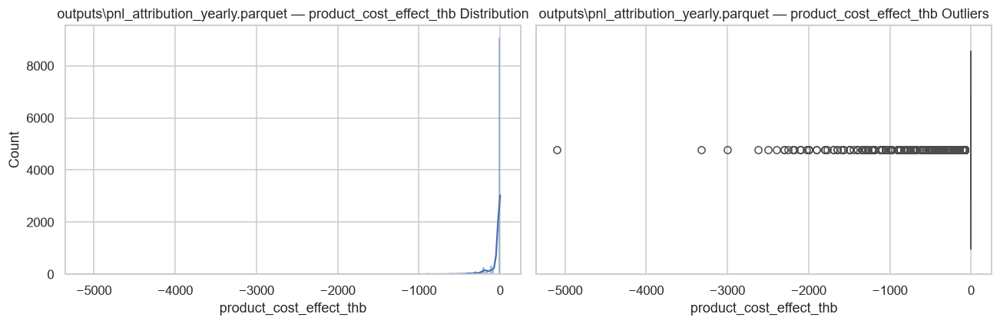


outputs\portfolio_valuation_monthly.csv: (117356, 18)


,portfolio_id,valuation_date,calendar_year,cash_balance_thb,gold_qty_bar_bw,gold_qty_ornament_bw,gold_cost_basis_thb,gold_liquidation_value_thb,portfolio_equity_thb,net_contributed_capital_thb,cumulative_realized_pnl_thb,unrealized_pnl_thb,cumulative_transaction_cost_thb,cumulative_net_pnl_thb,valuation_price_timestamp,valuation_quality_flag,simulation_run_id,is_synthetic
0,P20060001,2006-06-30,2006,6000.0,0.0,0.0,0.0,0.0,6000.0,6000.0,0.0,0.0,0.0,0.0,2006-06-30,OK,R001,True
1,P20060001,2006-07-31,2006,6000.0,0.0,0.0,0.0,0.0,6000.0,6000.0,0.0,0.0,0.0,0.0,2006-07-31,OK,R001,True
2,P20060001,2006-08-31,2006,6000.0,0.0,0.0,0.0,0.0,6000.0,6000.0,0.0,0.0,0.0,0.0,2006-08-31,OK,R001,True
3,P20060001,2006-09-30,2006,6000.0,0.0,0.0,0.0,0.0,6000.0,6000.0,0.0,0.0,0.0,0.0,2006-09-30,OK,R001,True
4,P20060001,2006-10-31,2006,6000.0,0.0,0.0,0.0,0.0,6000.0,6000.0,0.0,0.0,0.0,0.0,2006-10-31,OK,R001,True


,count,mean,std,min,25%,50%,75%,max
calendar_year,117356.0,2019.411619,4.997799,2006.000000,2016.000000,2020.000,2024.000000,2.026000e+03
cash_balance_thb,117356.0,17448.567239,22656.034021,0.000000,6037.470000,10650.650,21812.210800,6.674039e+05
gold_qty_bar_bw,117356.0,0.385846,1.342831,0.000000,0.000000,0.000,0.000000,2.000000e+01
gold_qty_ornament_bw,117356.0,0.564478,1.348093,0.000000,0.000000,0.160,0.500000,1.300000e+01
gold_cost_basis_thb,117356.0,19998.820540,38652.708597,0.000000,72.958314,5650.000,19375.000000,5.141500e+05
gold_liquidation_value_thb,117356.0,30745.979501,71051.151712,0.000000,101.912181,8500.000,27200.801784,1.548000e+06
portfolio_equity_thb,117356.0,48194.546740,75848.799609,0.000000,11823.100000,24749.215,50772.754538,1.600085e+06
net_contributed_capital_thb,117356.0,36639.599551,45116.729406,-70400.000000,10399.640000,21829.150,42253.407500,5.758720e+05
cumulative_realized_pnl_thb,117356.0,807.788228,4774.072169,-25980.515221,0.000000,0.000,10.156250,2.370520e+05
unrealized_pnl_thb,117356.0,10747.158961,39313.921959,-71725.000000,0.000000,525.000,6137.522192,1.137950e+06


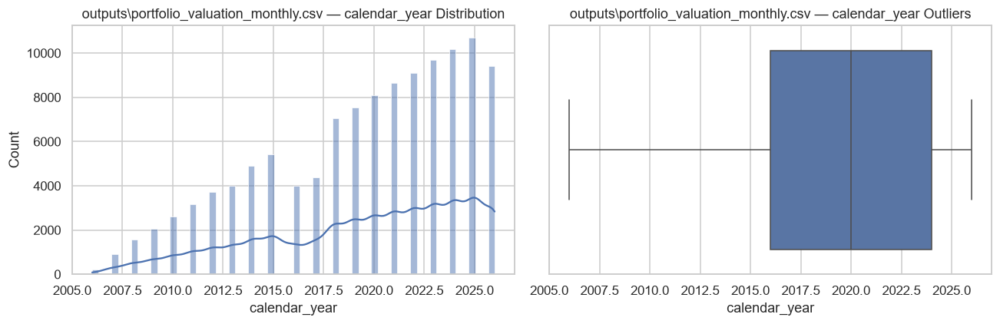

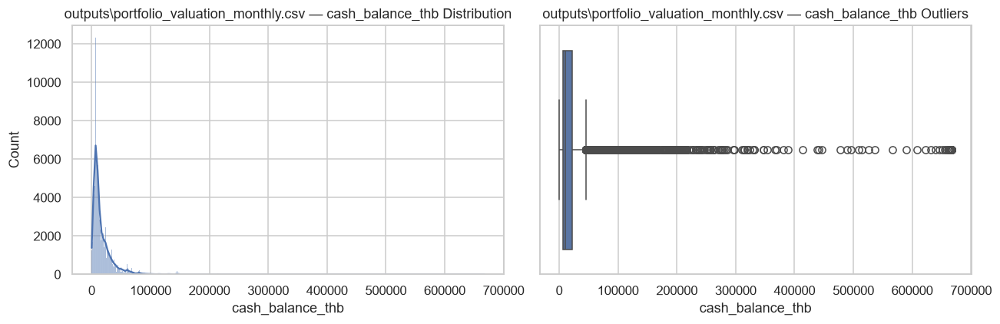

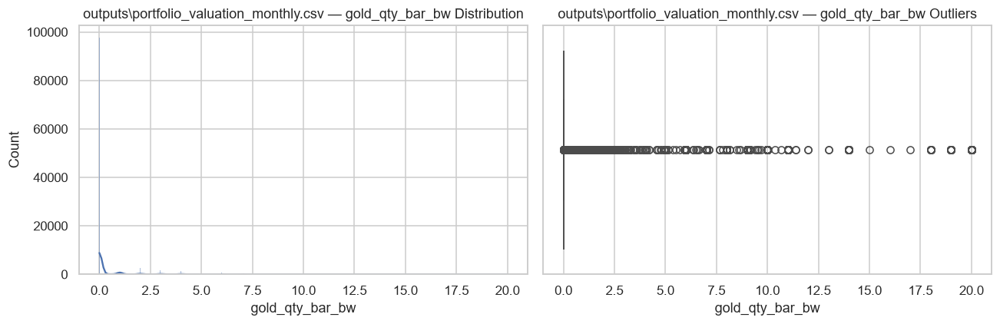

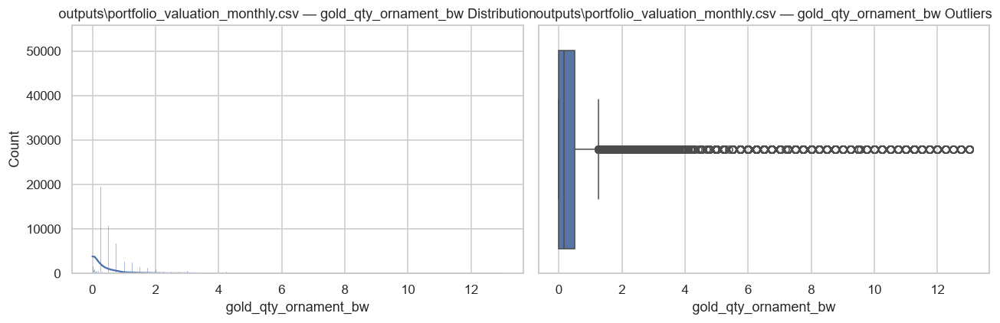

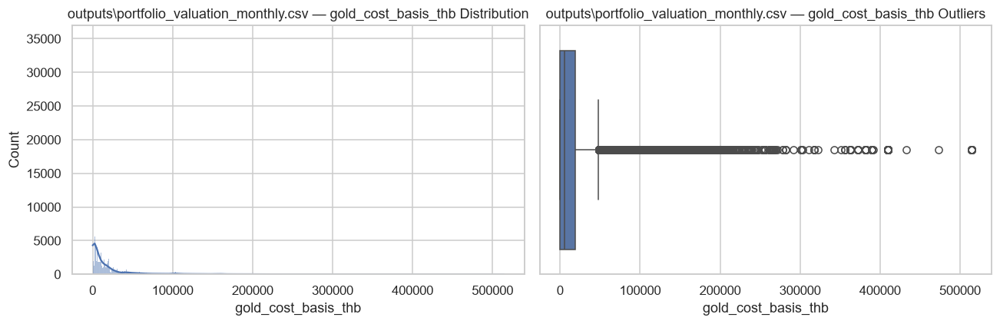

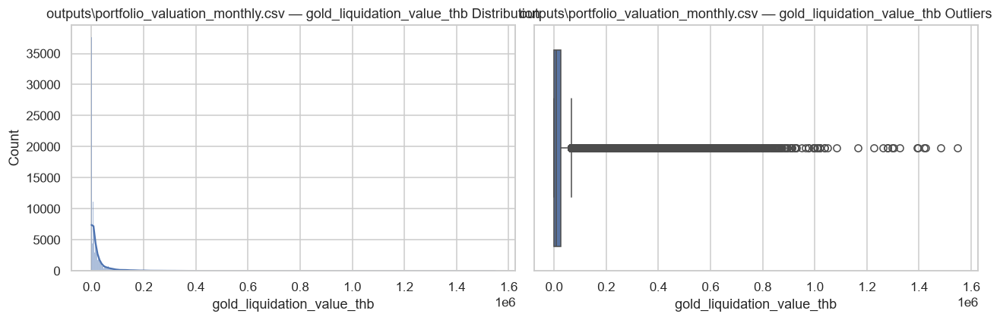


outputs\portfolio_valuation_monthly.parquet: (117356, 18)


,portfolio_id,valuation_date,calendar_year,cash_balance_thb,gold_qty_bar_bw,gold_qty_ornament_bw,gold_cost_basis_thb,gold_liquidation_value_thb,portfolio_equity_thb,net_contributed_capital_thb,cumulative_realized_pnl_thb,unrealized_pnl_thb,cumulative_transaction_cost_thb,cumulative_net_pnl_thb,valuation_price_timestamp,valuation_quality_flag,simulation_run_id,is_synthetic
0,P20060001,2006-06-30,2006,6000.0,0.0,0.0,0.0,0.0,6000.0,6000.0,0.0,0.0,0.0,0.0,2006-06-30,OK,R001,True
1,P20060001,2006-07-31,2006,6000.0,0.0,0.0,0.0,0.0,6000.0,6000.0,0.0,0.0,0.0,0.0,2006-07-31,OK,R001,True
2,P20060001,2006-08-31,2006,6000.0,0.0,0.0,0.0,0.0,6000.0,6000.0,0.0,0.0,0.0,0.0,2006-08-31,OK,R001,True
3,P20060001,2006-09-30,2006,6000.0,0.0,0.0,0.0,0.0,6000.0,6000.0,0.0,0.0,0.0,0.0,2006-09-30,OK,R001,True
4,P20060001,2006-10-31,2006,6000.0,0.0,0.0,0.0,0.0,6000.0,6000.0,0.0,0.0,0.0,0.0,2006-10-31,OK,R001,True


,count,mean,std,min,25%,50%,75%,max
calendar_year,117356.0,2019.411619,4.997799,2006.000000,2016.000000,2020.000,2024.000000,2.026000e+03
cash_balance_thb,117356.0,17448.567239,22656.034021,0.000000,6037.470000,10650.650,21812.210800,6.674039e+05
gold_qty_bar_bw,117356.0,0.385846,1.342831,0.000000,0.000000,0.000,0.000000,2.000000e+01
gold_qty_ornament_bw,117356.0,0.564478,1.348093,0.000000,0.000000,0.160,0.500000,1.300000e+01
gold_cost_basis_thb,117356.0,19998.820540,38652.708597,0.000000,72.958314,5650.000,19375.000000,5.141500e+05
gold_liquidation_value_thb,117356.0,30745.979501,71051.151712,0.000000,101.912181,8500.000,27200.801784,1.548000e+06
portfolio_equity_thb,117356.0,48194.546740,75848.799609,0.000000,11823.100000,24749.215,50772.754538,1.600085e+06
net_contributed_capital_thb,117356.0,36639.599551,45116.729406,-70400.000000,10399.640000,21829.150,42253.407500,5.758720e+05
cumulative_realized_pnl_thb,117356.0,807.788228,4774.072169,-25980.515221,0.000000,0.000,10.156250,2.370520e+05
unrealized_pnl_thb,117356.0,10747.158961,39313.921959,-71725.000000,0.000000,525.000,6137.522192,1.137950e+06


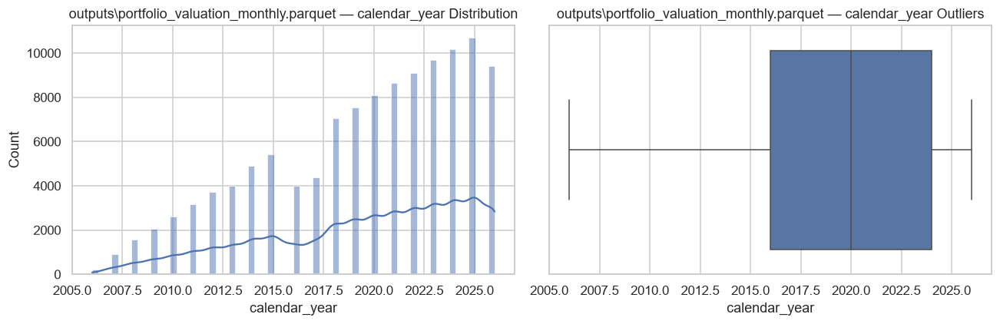

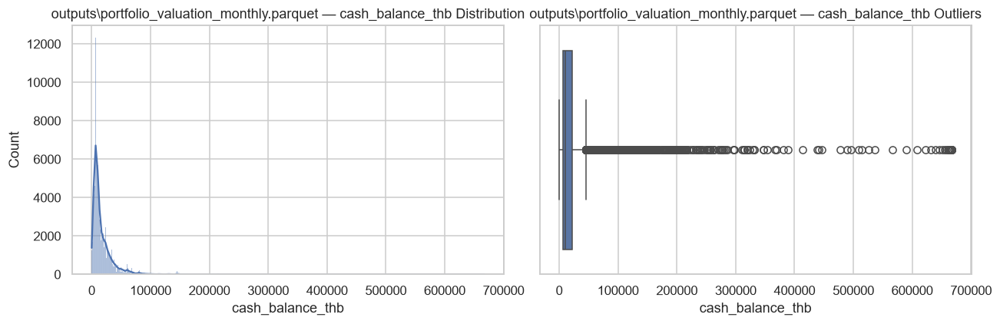

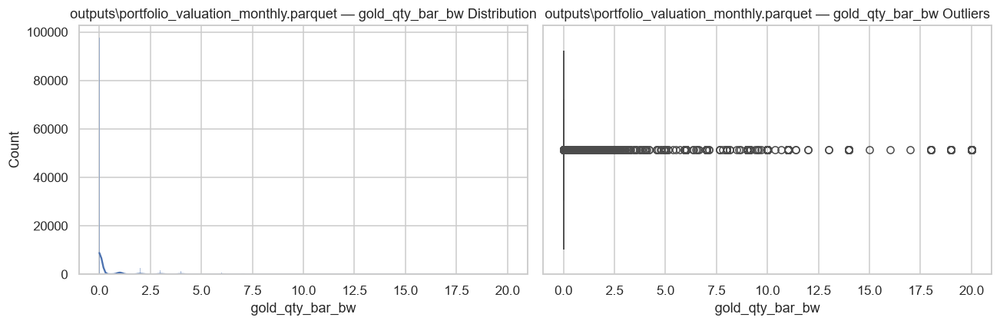

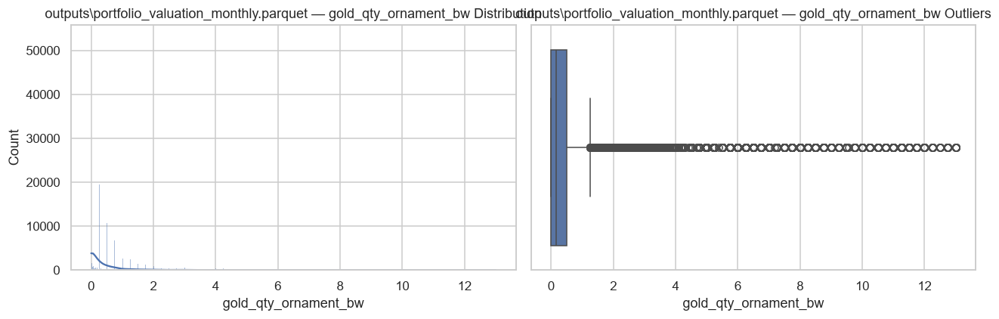

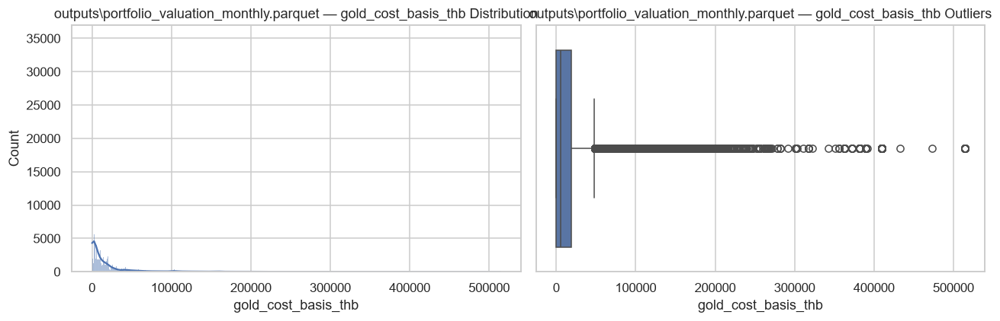

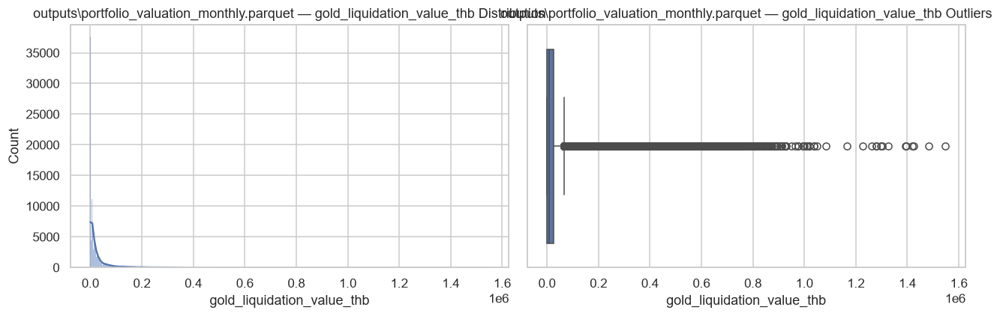


outputs\portfolio_yearly.csv: (10845, 27)


,portfolio_id,cohort_start_year,calendar_year,is_partial_year,year_start_date,year_end_date,beginning_equity_thb,ending_equity_thb,external_contributions_thb,external_withdrawals_thb,purchase_count,sale_count,gross_purchase_value_thb,gross_sale_value_thb,transaction_cost_thb,realized_pnl_thb,unrealized_pnl_thb,net_pnl_thb,annual_return,max_drawdown,data_coverage_ratio,calculation_quality_flag,benchmark_id,simulation_run_id,is_synthetic,benchmark_cum_net_pnl_thb,cum_net_pnl_thb
0,P20060001,2006,2006,True,2006-06-08,2006-12-30,0.0,6000.0,6000.0,0.0,0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,OK,BH_BAR_SAME_FLOWS,R001,True,-342.105263,0.0
1,P20060001,2006,2007,False,2007-01-01,2007-12-29,6000.0,6000.0,0.0,0.0,0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,OK,BH_BAR_SAME_FLOWS,R001,True,947.368421,0.0
2,P20060001,2006,2008,False,2008-01-01,2008-12-30,6000.0,6000.0,0.0,0.0,0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,OK,BH_BAR_SAME_FLOWS,R001,True,1315.789474,0.0
3,P20060001,2006,2009,False,2009-01-01,2009-12-30,6000.0,6000.0,0.0,0.0,0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,OK,BH_BAR_SAME_FLOWS,R001,True,3078.947368,0.0
4,P20060001,2006,2010,False,2010-01-01,2010-12-30,6000.0,6000.0,0.0,0.0,0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,OK,BH_BAR_SAME_FLOWS,R001,True,4552.631579,0.0


,count,mean,std,min,25%,50%,75%,max
cohort_start_year,10845.0,2012.680037,5.097968,2006.000000,2008.000000,2012.000000,2016.000000,2.026000e+03
calendar_year,10845.0,2019.229691,5.089687,2006.000000,2016.000000,2020.000000,2024.000000,2.026000e+03
beginning_equity_thb,10845.0,40989.729253,67067.017678,0.000000,9302.060000,21056.802500,44614.730000,1.347085e+06
ending_equity_thb,10845.0,49062.572535,78916.569548,0.000000,11665.772650,24686.510055,51702.100000,1.362085e+06
external_contributions_thb,10845.0,4821.695076,19366.157151,0.000000,0.000000,0.000000,0.000000,5.448720e+05
external_withdrawals_thb,10845.0,342.258898,5735.723517,0.000000,0.000000,0.000000,0.000000,3.641069e+05
purchase_count,10845.0,0.410143,1.114344,0.000000,0.000000,0.000000,0.000000,1.200000e+01
sale_count,10845.0,1.280682,2.767946,0.000000,0.000000,0.000000,1.000000,1.200000e+01
gross_purchase_value_thb,10845.0,5423.299908,19876.097810,0.000000,0.000000,0.000000,0.000000,5.439500e+05
gross_sale_value_thb,10845.0,3304.773088,17325.513495,0.000000,0.000000,0.000000,0.057152,4.993516e+05


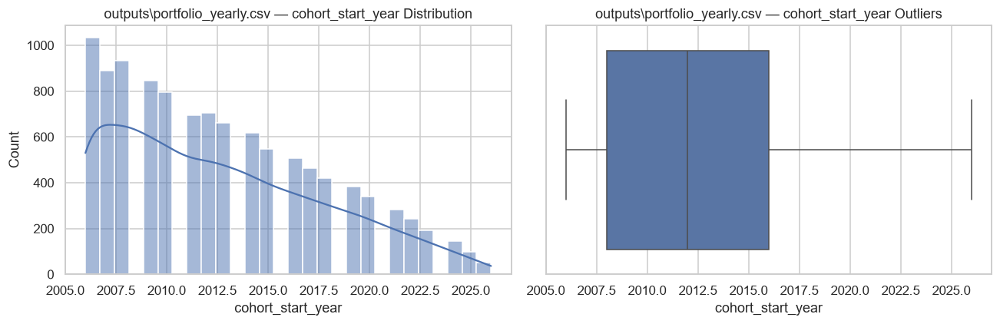

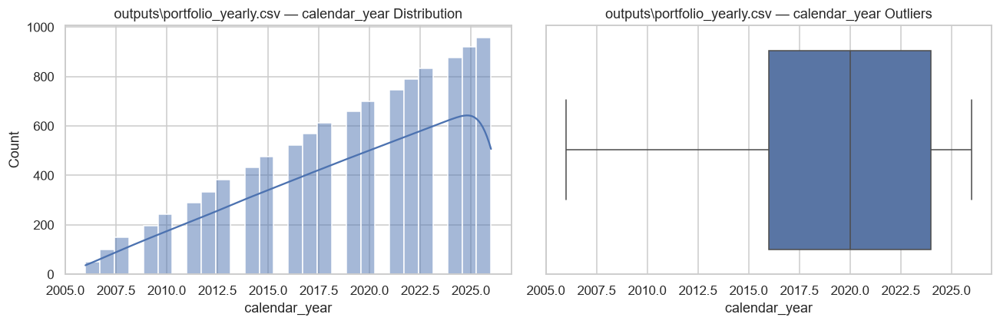

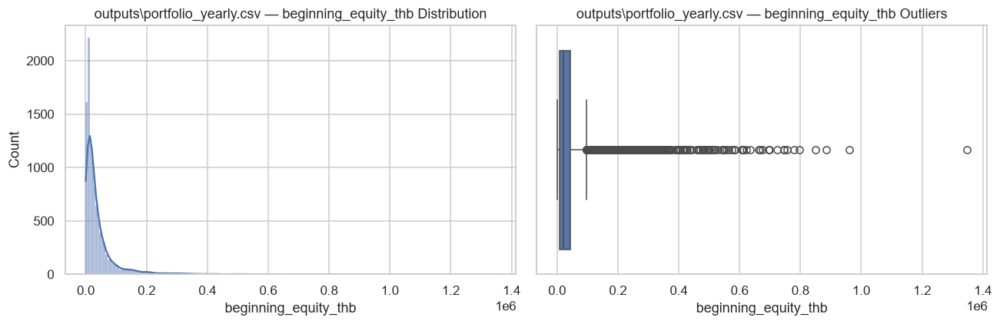

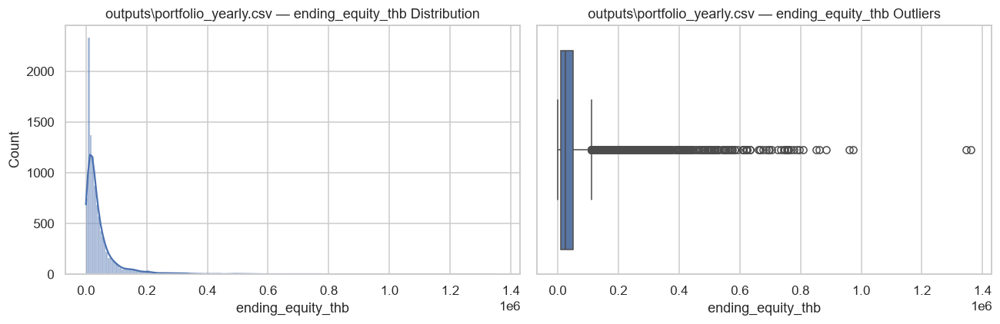

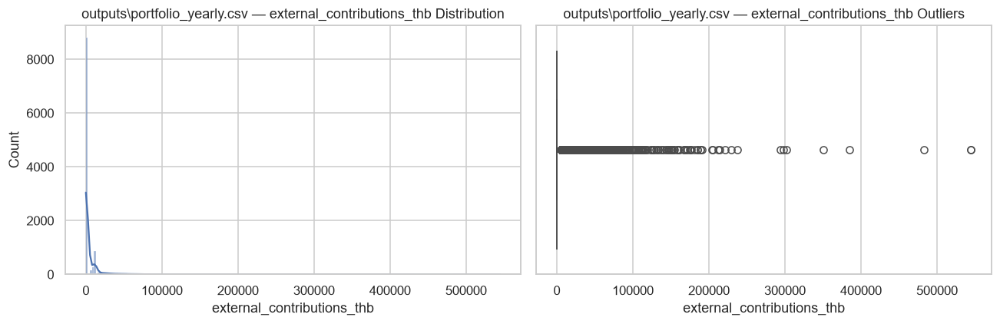

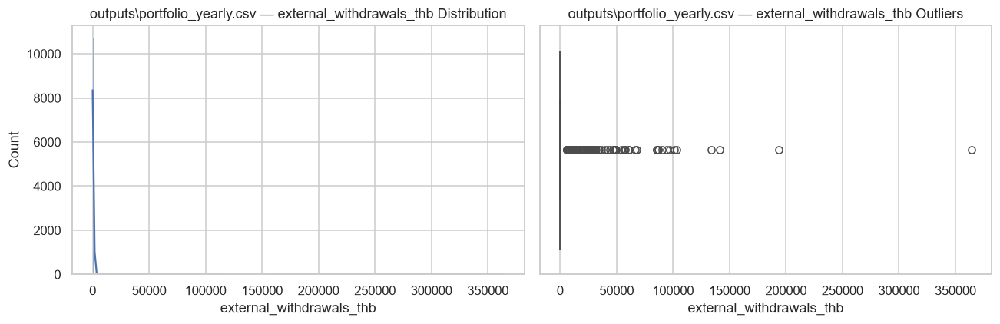


outputs\portfolio_yearly.parquet: (10845, 27)


,portfolio_id,cohort_start_year,calendar_year,is_partial_year,year_start_date,year_end_date,beginning_equity_thb,ending_equity_thb,external_contributions_thb,external_withdrawals_thb,purchase_count,sale_count,gross_purchase_value_thb,gross_sale_value_thb,transaction_cost_thb,realized_pnl_thb,unrealized_pnl_thb,net_pnl_thb,annual_return,max_drawdown,data_coverage_ratio,calculation_quality_flag,benchmark_id,simulation_run_id,is_synthetic,benchmark_cum_net_pnl_thb,cum_net_pnl_thb
0,P20060001,2006,2006,True,2006-06-08,2006-12-30,0.0,6000.0,6000.0,0.0,0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,OK,BH_BAR_SAME_FLOWS,R001,True,-342.105263,0.0
1,P20060001,2006,2007,False,2007-01-01,2007-12-29,6000.0,6000.0,0.0,0.0,0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,OK,BH_BAR_SAME_FLOWS,R001,True,947.368421,0.0
2,P20060001,2006,2008,False,2008-01-01,2008-12-30,6000.0,6000.0,0.0,0.0,0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,OK,BH_BAR_SAME_FLOWS,R001,True,1315.789474,0.0
3,P20060001,2006,2009,False,2009-01-01,2009-12-30,6000.0,6000.0,0.0,0.0,0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,OK,BH_BAR_SAME_FLOWS,R001,True,3078.947368,0.0
4,P20060001,2006,2010,False,2010-01-01,2010-12-30,6000.0,6000.0,0.0,0.0,0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,OK,BH_BAR_SAME_FLOWS,R001,True,4552.631579,0.0


,count,mean,std,min,25%,50%,75%,max
cohort_start_year,10845.0,2012.680037,5.097968,2006.000000,2008.000000,2012.000000,2016.000000,2.026000e+03
calendar_year,10845.0,2019.229691,5.089687,2006.000000,2016.000000,2020.000000,2024.000000,2.026000e+03
beginning_equity_thb,10845.0,40989.729253,67067.017678,0.000000,9302.060000,21056.802500,44614.730000,1.347085e+06
ending_equity_thb,10845.0,49062.572535,78916.569548,0.000000,11665.772650,24686.510055,51702.100000,1.362085e+06
external_contributions_thb,10845.0,4821.695076,19366.157151,0.000000,0.000000,0.000000,0.000000,5.448720e+05
external_withdrawals_thb,10845.0,342.258898,5735.723517,0.000000,0.000000,0.000000,0.000000,3.641069e+05
purchase_count,10845.0,0.410143,1.114344,0.000000,0.000000,0.000000,0.000000,1.200000e+01
sale_count,10845.0,1.280682,2.767946,0.000000,0.000000,0.000000,1.000000,1.200000e+01
gross_purchase_value_thb,10845.0,5423.299908,19876.097810,0.000000,0.000000,0.000000,0.000000,5.439500e+05
gross_sale_value_thb,10845.0,3304.773088,17325.513495,0.000000,0.000000,0.000000,0.057152,4.993516e+05


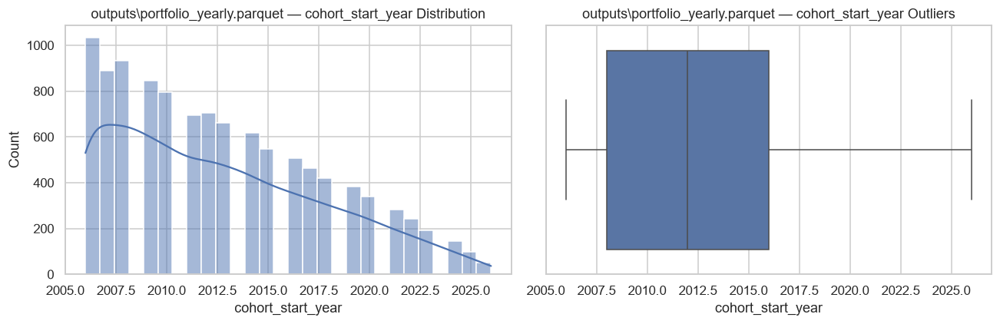

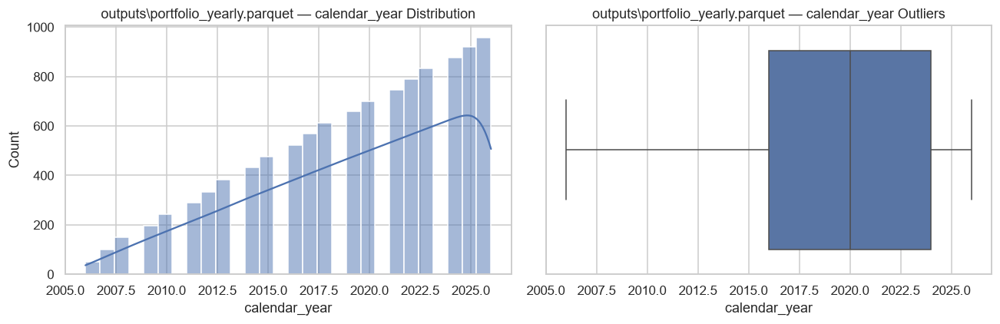

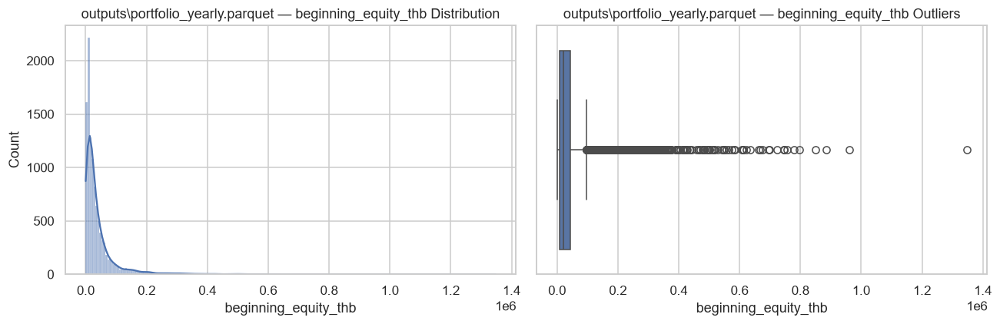

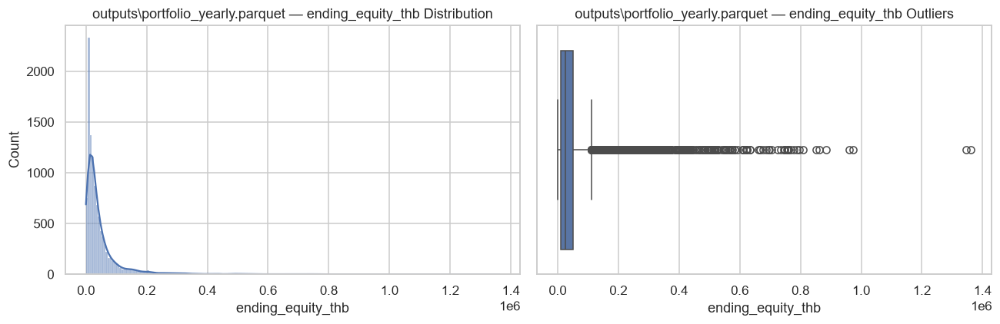

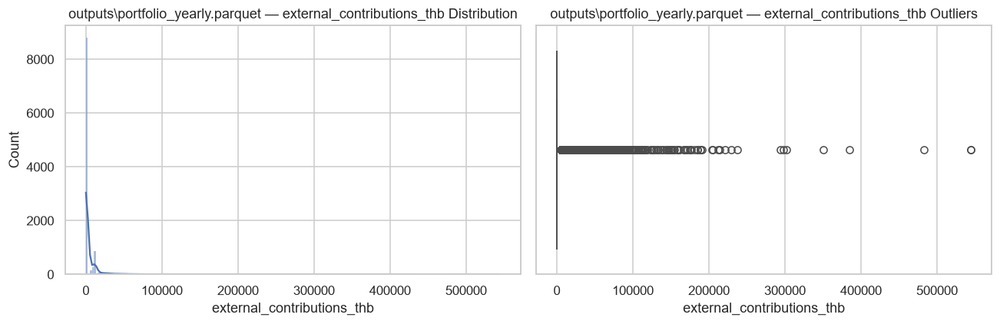

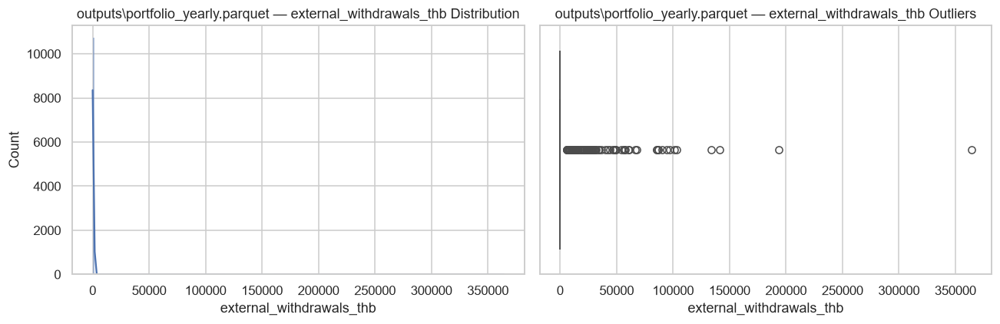


outputs\transaction_ledger.csv: (40089, 22)


,transaction_id,portfolio_id,event_timestamp,calendar_year,event_type,gold_product_type,side,requested_quantity_bw,executed_quantity_bw,price_quote_timestamp,customer_execution_price_thb_per_bw,gross_amount_thb,transaction_cost_thb,net_cash_change_thb,realized_pnl_thb,execution_status,rejection_reason,behavior_scenario,parameter_set_id,simulation_run_id,is_synthetic,source_quote_id
0,P20060001-T00000,P20060001,2006-07-28,2006,GOLD_PURCHASE,bar,BUY,0.251101,0.0,2006-07-28,11350.0,0.0,0.0,0.0,0.0,REJECTED,BELOW_MIN_TRADE_UNIT,buy_momentum,PS_R001,R001,True,GTA:2006-07-28
1,P20060001-T00000,P20060001,2006-08-14,2006,GOLD_PURCHASE,bar,BUY,0.252212,0.0,2006-08-14,11300.0,0.0,0.0,0.0,0.0,REJECTED,BELOW_MIN_TRADE_UNIT,buy_momentum,PS_R001,R001,True,GTA:2006-08-14
2,P20060001-T00000,P20060001,2006-11-27,2006,GOLD_PURCHASE,bar,BUY,0.257919,0.0,2006-11-27,11050.0,0.0,0.0,0.0,0.0,REJECTED,BELOW_MIN_TRADE_UNIT,buy_momentum,PS_R001,R001,True,GTA:2006-11-27
3,P20060001-T00000,P20060001,2007-02-24,2007,GOLD_PURCHASE,bar,BUY,0.248908,0.0,2007-02-24,11450.0,0.0,0.0,0.0,0.0,REJECTED,BELOW_MIN_TRADE_UNIT,buy_momentum,PS_R001,R001,True,GTA:2007-02-24
4,P20060001-T00000,P20060001,2007-03-07,2007,GOLD_PURCHASE,bar,BUY,0.262673,0.0,2007-03-07,10850.0,0.0,0.0,0.0,0.0,REJECTED,BELOW_MIN_TRADE_UNIT,buy_momentum,PS_R001,R001,True,GTA:2007-03-07


,count,mean,std,min,25%,50%,75%,max
calendar_year,40089.0,2019.436604,5.209905,2.006000e+03,2015.000000,2021.000000,2024.000000,2026.00
requested_quantity_bw,37648.0,0.200980,0.325771,2.525521e-10,0.021942,0.119683,0.247454,12.75
executed_quantity_bw,40089.0,0.088093,0.291618,0.000000e+00,0.000000,0.000000,0.011124,12.75
customer_execution_price_thb_per_bw,37648.0,31807.714885,15688.651732,1.035000e+04,20200.000000,26800.000000,35100.000000,81050.00
gross_amount_thb,40089.0,2361.145243,8555.750332,0.000000e+00,0.000000,0.000000,300.338745,389512.50
transaction_cost_thb,40089.0,0.000000,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.00
net_cash_change_thb,40089.0,-573.110413,8857.061924,-3.895125e+05,0.000000,0.000000,0.620077,228000.00
realized_pnl_thb,40089.0,78.226990,945.284786,-5.650000e+03,0.000000,0.000000,0.000754,70400.00


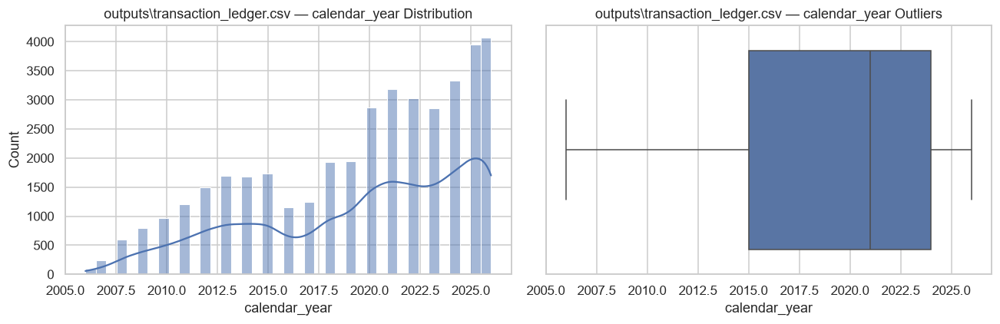

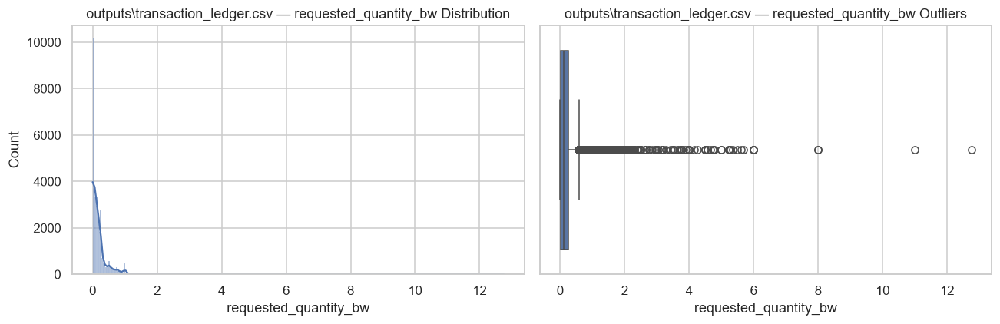

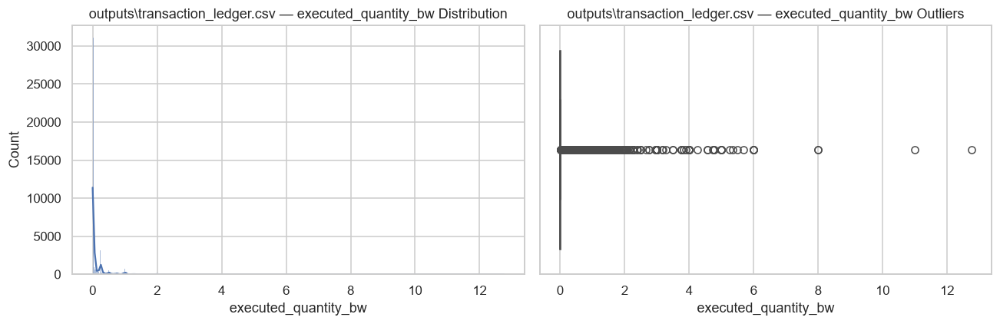

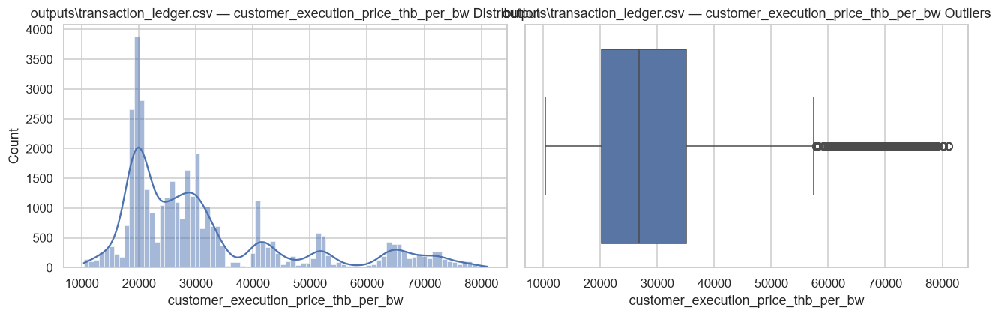

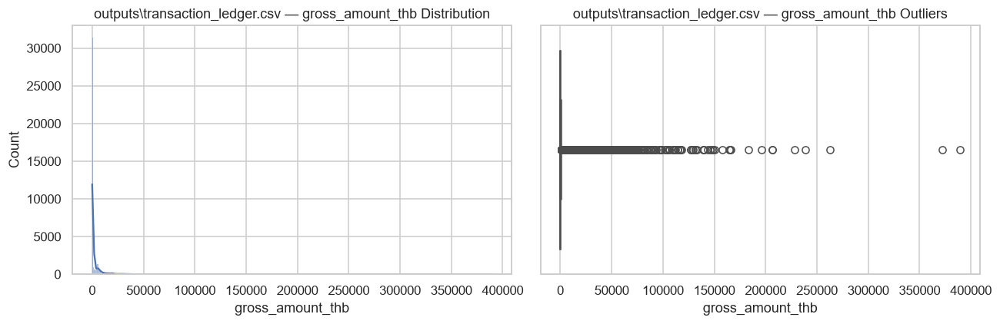


outputs\transaction_ledger.parquet: (40089, 22)


,transaction_id,portfolio_id,event_timestamp,calendar_year,event_type,gold_product_type,side,requested_quantity_bw,executed_quantity_bw,price_quote_timestamp,customer_execution_price_thb_per_bw,gross_amount_thb,transaction_cost_thb,net_cash_change_thb,realized_pnl_thb,execution_status,rejection_reason,behavior_scenario,parameter_set_id,simulation_run_id,is_synthetic,source_quote_id
0,P20060001-T00000,P20060001,2006-07-28,2006,GOLD_PURCHASE,bar,BUY,0.251101,0.0,2006-07-28,11350.0,0.0,0.0,0.0,0.0,REJECTED,BELOW_MIN_TRADE_UNIT,buy_momentum,PS_R001,R001,True,GTA:2006-07-28
1,P20060001-T00000,P20060001,2006-08-14,2006,GOLD_PURCHASE,bar,BUY,0.252212,0.0,2006-08-14,11300.0,0.0,0.0,0.0,0.0,REJECTED,BELOW_MIN_TRADE_UNIT,buy_momentum,PS_R001,R001,True,GTA:2006-08-14
2,P20060001-T00000,P20060001,2006-11-27,2006,GOLD_PURCHASE,bar,BUY,0.257919,0.0,2006-11-27,11050.0,0.0,0.0,0.0,0.0,REJECTED,BELOW_MIN_TRADE_UNIT,buy_momentum,PS_R001,R001,True,GTA:2006-11-27
3,P20060001-T00000,P20060001,2007-02-24,2007,GOLD_PURCHASE,bar,BUY,0.248908,0.0,2007-02-24,11450.0,0.0,0.0,0.0,0.0,REJECTED,BELOW_MIN_TRADE_UNIT,buy_momentum,PS_R001,R001,True,GTA:2007-02-24
4,P20060001-T00000,P20060001,2007-03-07,2007,GOLD_PURCHASE,bar,BUY,0.262673,0.0,2007-03-07,10850.0,0.0,0.0,0.0,0.0,REJECTED,BELOW_MIN_TRADE_UNIT,buy_momentum,PS_R001,R001,True,GTA:2007-03-07


,count,mean,std,min,25%,50%,75%,max
calendar_year,40089.0,2019.436604,5.209905,2.006000e+03,2015.000000,2021.000000,2024.000000,2026.00
requested_quantity_bw,37648.0,0.200980,0.325771,2.525521e-10,0.021942,0.119683,0.247454,12.75
executed_quantity_bw,40089.0,0.088093,0.291618,0.000000e+00,0.000000,0.000000,0.011124,12.75
customer_execution_price_thb_per_bw,37648.0,31807.714885,15688.651732,1.035000e+04,20200.000000,26800.000000,35100.000000,81050.00
gross_amount_thb,40089.0,2361.145243,8555.750332,0.000000e+00,0.000000,0.000000,300.338745,389512.50
transaction_cost_thb,40089.0,0.000000,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.00
net_cash_change_thb,40089.0,-573.110413,8857.061924,-3.895125e+05,0.000000,0.000000,0.620077,228000.00
realized_pnl_thb,40089.0,78.226990,945.284786,-5.650000e+03,0.000000,0.000000,0.000754,70400.00


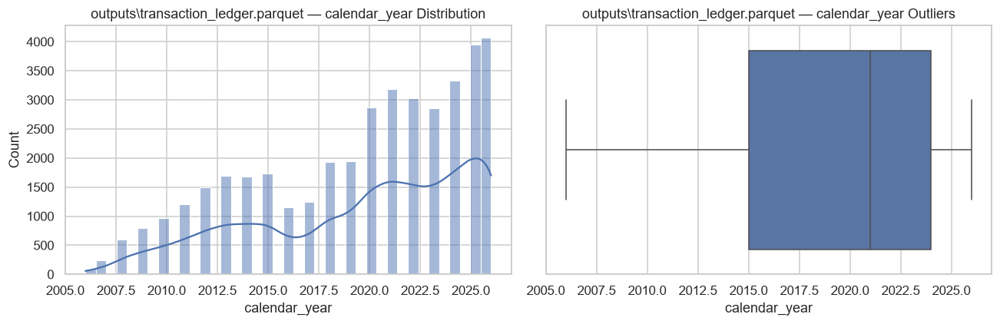

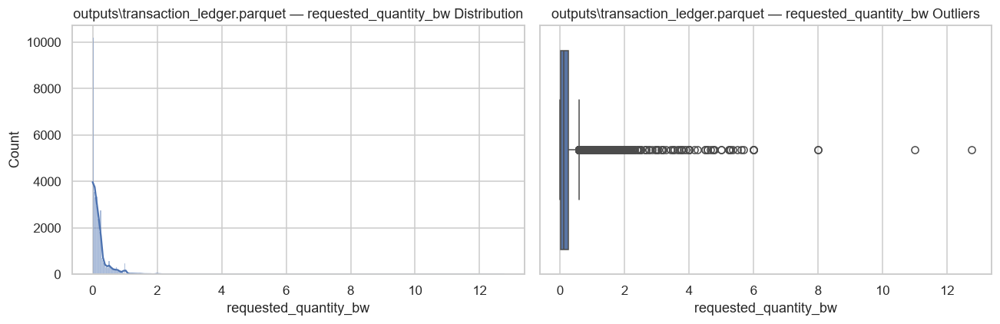

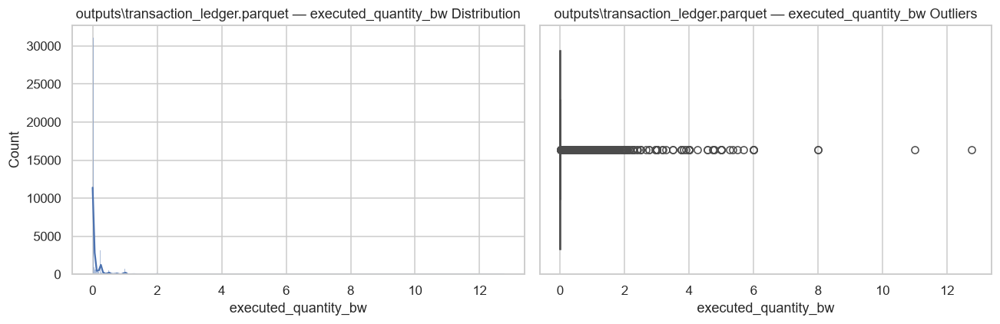

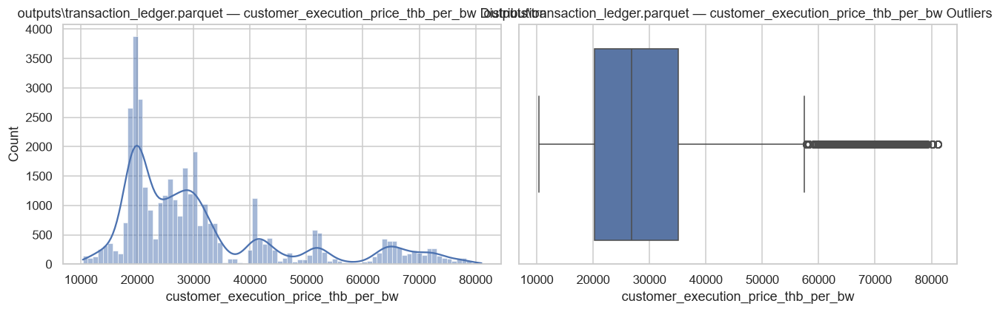

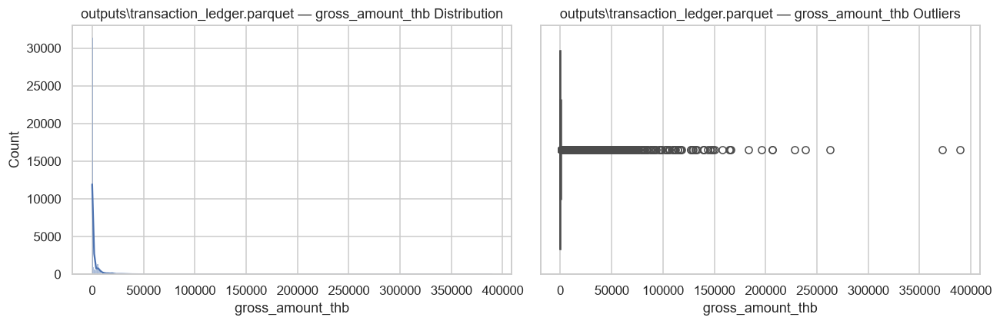


### Portfolio

outputs\cashflow_ledger.csv: (12566, 8)


,cashflow_id,portfolio_id,event_timestamp,cashflow_type,amount_thb,reason_or_scenario,simulation_run_id,is_synthetic
0,P20060001-C00001,P20060001,2006-06-08,initial_contribution,6000.00,initial funding (synthetic),R001,True
1,P20060002-C00002,P20060002,2006-11-18,initial_contribution,6000.00,initial funding (synthetic),R001,True
2,P20060003-C00003,P20060003,2006-05-29,initial_contribution,8506.68,initial funding (synthetic),R001,True
3,P20060004-C00004,P20060004,2006-11-08,initial_contribution,8272.88,initial funding (synthetic),R001,True
4,P20060005-C00005,P20060005,2006-10-06,initial_contribution,13494.22,initial funding (synthetic),R001,True


,count,mean,std,min,25%,50%,75%,max
amount_thb,12566.0,4456.715013,18399.593241,1000.0,1000.0,1000.0,1000.0,544523.64


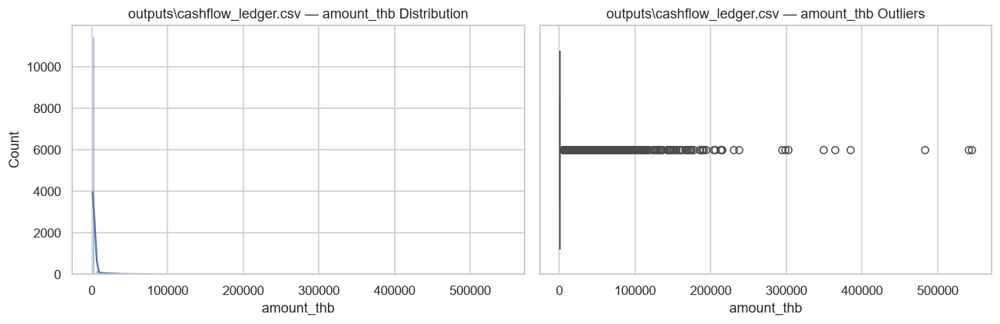


outputs\cashflow_ledger.parquet: (12566, 8)


,cashflow_id,portfolio_id,event_timestamp,cashflow_type,amount_thb,reason_or_scenario,simulation_run_id,is_synthetic
0,P20060001-C00001,P20060001,2006-06-08,initial_contribution,6000.00,initial funding (synthetic),R001,True
1,P20060002-C00002,P20060002,2006-11-18,initial_contribution,6000.00,initial funding (synthetic),R001,True
2,P20060003-C00003,P20060003,2006-05-29,initial_contribution,8506.68,initial funding (synthetic),R001,True
3,P20060004-C00004,P20060004,2006-11-08,initial_contribution,8272.88,initial funding (synthetic),R001,True
4,P20060005-C00005,P20060005,2006-10-06,initial_contribution,13494.22,initial funding (synthetic),R001,True


,count,mean,std,min,25%,50%,75%,max
amount_thb,12566.0,4456.715013,18399.593241,1000.0,1000.0,1000.0,1000.0,544523.64


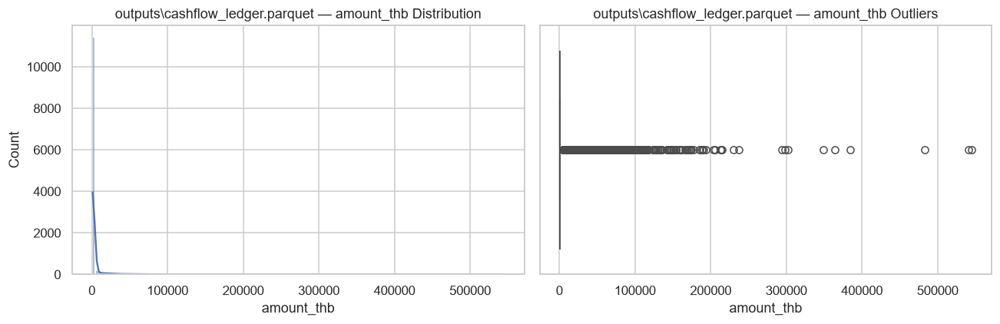


outputs\pnl_attribution_yearly.csv: (10845, 14)


,portfolio_id,calendar_year,pnl_total_thb,price_effect_thb,trading_timing_effect_thb,transaction_cost_effect_thb,product_cost_effect_thb,other_modeled_effect_thb,unattributed_residual_thb,benchmark_id,attribution_method,attribution_quality_flag,simulation_run_id,is_synthetic
0,P20060001,2006,0.0,0.0,0.0,-0.0,0.0,0.0,0.0,BH_BAR_SAME_FLOWS,unit_lifecycle_vs_liquidation_quotes_v1,RECONCILED,R001,True
1,P20060001,2007,0.0,0.0,0.0,-0.0,0.0,0.0,0.0,BH_BAR_SAME_FLOWS,unit_lifecycle_vs_liquidation_quotes_v1,RECONCILED,R001,True
2,P20060001,2008,0.0,0.0,0.0,-0.0,0.0,0.0,0.0,BH_BAR_SAME_FLOWS,unit_lifecycle_vs_liquidation_quotes_v1,RECONCILED,R001,True
3,P20060001,2009,0.0,0.0,0.0,-0.0,0.0,0.0,0.0,BH_BAR_SAME_FLOWS,unit_lifecycle_vs_liquidation_quotes_v1,RECONCILED,R001,True
4,P20060001,2010,0.0,0.0,0.0,-0.0,0.0,0.0,0.0,BH_BAR_SAME_FLOWS,unit_lifecycle_vs_liquidation_quotes_v1,RECONCILED,R001,True


,count,mean,std,min,25%,50%,75%,max
calendar_year,10845.0,2.019230e+03,5.089687,2.006000e+03,2016.0,2020.0,2024.0,2026.000000
pnl_total_thb,10845.0,3.593407e+03,16212.375614,-6.198750e+04,0.0,150.0,1800.0,451000.000000
price_effect_thb,10845.0,3.665277e+03,16217.127869,-5.771250e+04,0.0,200.0,1800.0,451000.000000
trading_timing_effect_thb,10845.0,-2.135085e+01,71.915684,-2.000000e+03,0.0,0.0,0.0,0.000000
transaction_cost_effect_thb,10845.0,0.000000e+00,0.000000,-0.000000e+00,0.0,0.0,0.0,-0.000000
product_cost_effect_thb,10845.0,-5.051867e+01,187.328603,-5.100000e+03,0.0,0.0,0.0,0.000000
other_modeled_effect_thb,10845.0,0.000000e+00,0.000000,0.000000e+00,0.0,0.0,0.0,0.000000
unattributed_residual_thb,10845.0,1.440575e-07,0.000002,-2.910383e-11,0.0,0.0,0.0,0.000023


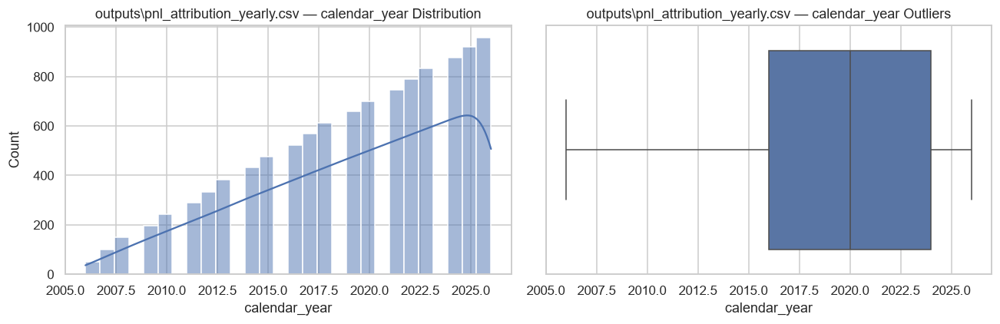

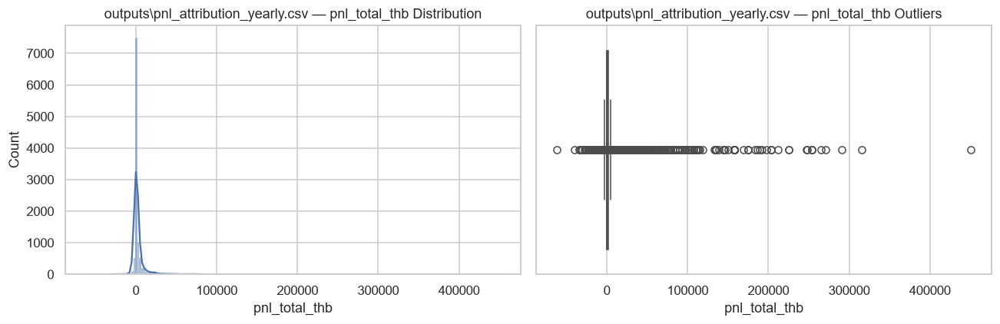

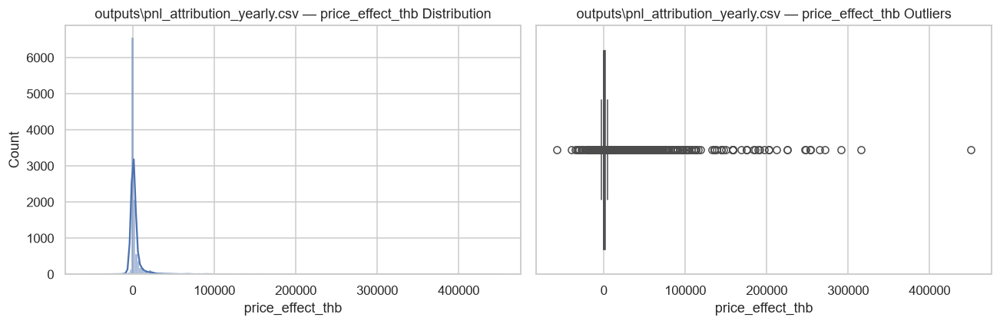

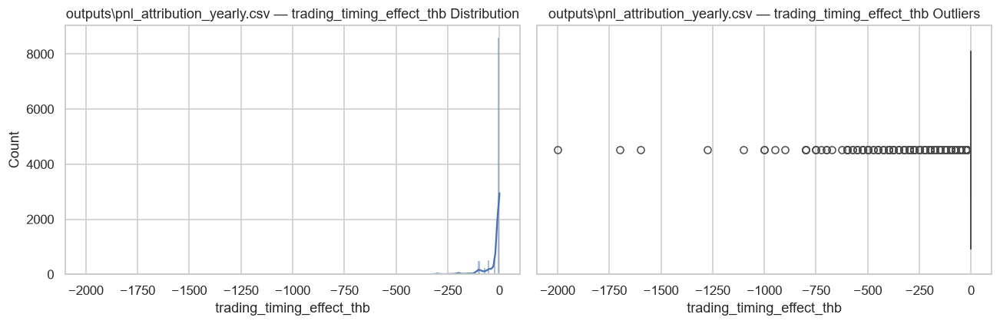

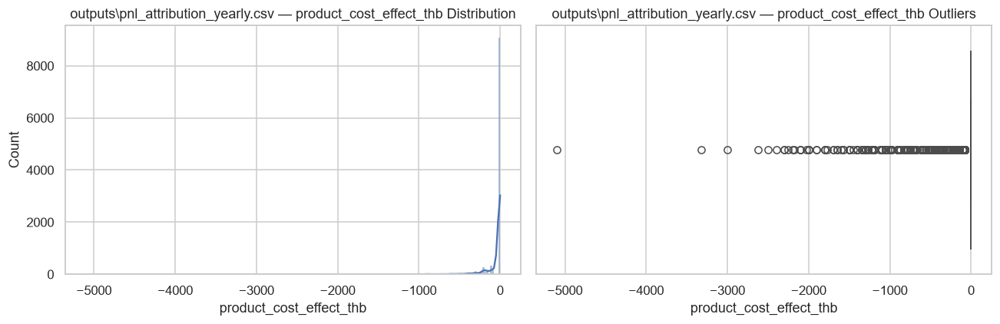


outputs\pnl_attribution_yearly.parquet: (10845, 14)


,portfolio_id,calendar_year,pnl_total_thb,price_effect_thb,trading_timing_effect_thb,transaction_cost_effect_thb,product_cost_effect_thb,other_modeled_effect_thb,unattributed_residual_thb,benchmark_id,attribution_method,attribution_quality_flag,simulation_run_id,is_synthetic
0,P20060001,2006,0.0,0.0,0.0,-0.0,0.0,0.0,0.0,BH_BAR_SAME_FLOWS,unit_lifecycle_vs_liquidation_quotes_v1,RECONCILED,R001,True
1,P20060001,2007,0.0,0.0,0.0,-0.0,0.0,0.0,0.0,BH_BAR_SAME_FLOWS,unit_lifecycle_vs_liquidation_quotes_v1,RECONCILED,R001,True
2,P20060001,2008,0.0,0.0,0.0,-0.0,0.0,0.0,0.0,BH_BAR_SAME_FLOWS,unit_lifecycle_vs_liquidation_quotes_v1,RECONCILED,R001,True
3,P20060001,2009,0.0,0.0,0.0,-0.0,0.0,0.0,0.0,BH_BAR_SAME_FLOWS,unit_lifecycle_vs_liquidation_quotes_v1,RECONCILED,R001,True
4,P20060001,2010,0.0,0.0,0.0,-0.0,0.0,0.0,0.0,BH_BAR_SAME_FLOWS,unit_lifecycle_vs_liquidation_quotes_v1,RECONCILED,R001,True


,count,mean,std,min,25%,50%,75%,max
calendar_year,10845.0,2.019230e+03,5.089687,2.006000e+03,2016.0,2020.0,2024.0,2026.000000
pnl_total_thb,10845.0,3.593407e+03,16212.375614,-6.198750e+04,0.0,150.0,1800.0,451000.000000
price_effect_thb,10845.0,3.665277e+03,16217.127869,-5.771250e+04,0.0,200.0,1800.0,451000.000000
trading_timing_effect_thb,10845.0,-2.135085e+01,71.915684,-2.000000e+03,0.0,0.0,0.0,0.000000
transaction_cost_effect_thb,10845.0,0.000000e+00,0.000000,-0.000000e+00,0.0,0.0,0.0,-0.000000
product_cost_effect_thb,10845.0,-5.051867e+01,187.328603,-5.100000e+03,0.0,0.0,0.0,0.000000
other_modeled_effect_thb,10845.0,0.000000e+00,0.000000,0.000000e+00,0.0,0.0,0.0,0.000000
unattributed_residual_thb,10845.0,1.440575e-07,0.000002,-2.910383e-11,0.0,0.0,0.0,0.000023


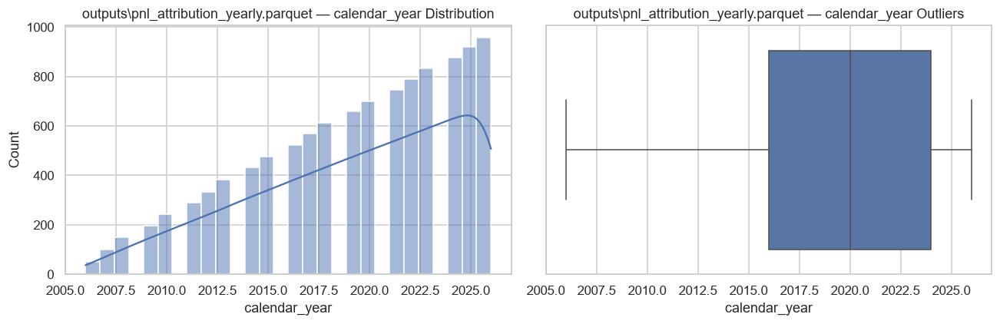

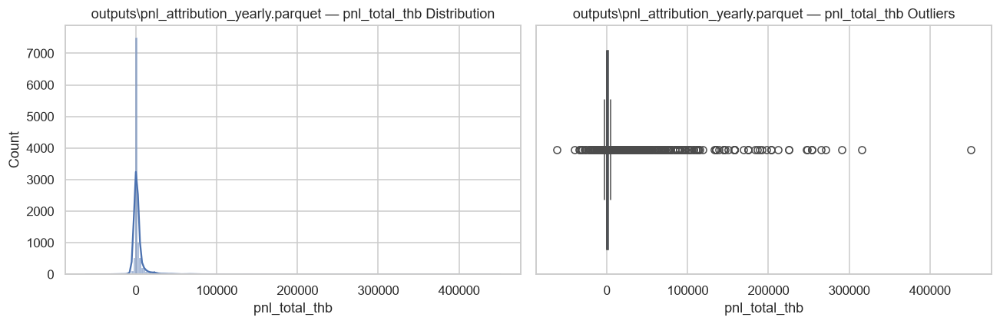

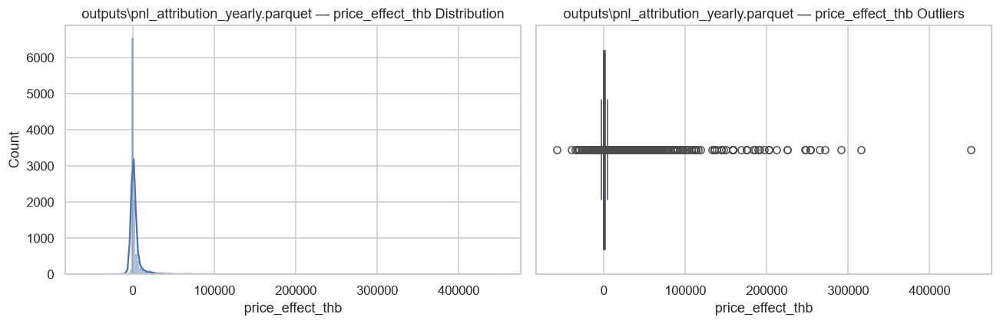

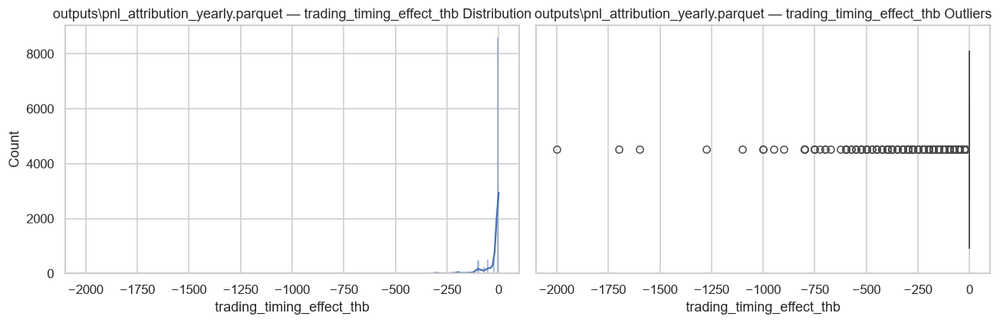

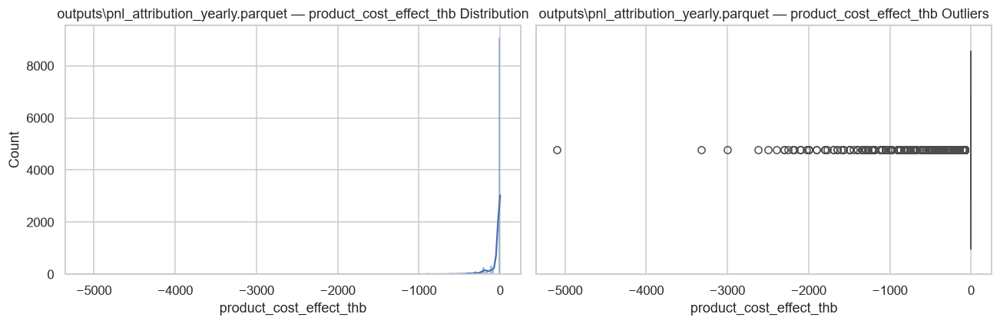


outputs\portfolio_master.csv: (1050, 16)


,portfolio_id,cohort_start_year,start_timestamp,end_timestamp,portfolio_segment,gold_product_type,initial_capital_thb,initial_cash_thb,initial_gold_quantity,initial_gold_value_thb,behavior_scenario,parameter_set_id,random_seed_id,simulation_run_id,is_synthetic,calibration_status
0,P20060001,2006,2006-06-08,2026-10-22,mass_retail,bar,6000.00,6000.00,0.00,0.0,buy_momentum,PS_R001,seed:20261022:2006:P20060001,R001,True,SCENARIO_ASSUMPTION
1,P20060002,2006,2006-11-18,2026-10-22,mass_retail,ornament,6000.00,3212.50,0.25,2787.5,partial_profit_taking,PS_R001,seed:20261022:2006:P20060002,R001,True,SCENARIO_ASSUMPTION
2,P20060003,2006,2006-05-29,2026-10-22,mass_retail,ornament,8506.68,5444.18,0.25,3062.5,partial_profit_taking,PS_R001,seed:20261022:2006:P20060003,R001,True,SCENARIO_ASSUMPTION
3,P20060004,2006,2006-11-08,2026-10-22,mass_retail,ornament,8272.88,5460.38,0.25,2812.5,inactive,PS_R001,seed:20261022:2006:P20060004,R001,True,SCENARIO_ASSUMPTION
4,P20060005,2006,2006-10-06,2026-10-22,mass_retail,ornament,13494.22,10831.72,0.25,2662.5,dca,PS_R001,seed:20261022:2006:P20060005,R001,True,SCENARIO_ASSUMPTION


,count,mean,std,min,25%,50%,75%,max
cohort_start_year,1050.0,2016.000000,6.058186,2006.0,2011.0000,2016.000,2021.0000,2026.00
initial_capital_thb,1050.0,38924.079143,49237.532129,6000.0,11996.6125,23563.665,46196.8525,544523.64
initial_cash_thb,1050.0,21399.829143,30266.683317,450.0,6890.6025,12579.415,23955.8050,508772.04
initial_gold_quantity,1050.0,0.686190,0.931380,0.0,0.2500,0.500,1.0000,12.75
initial_gold_value_thb,1050.0,17524.250000,27859.405254,0.0,4950.0000,10131.250,20237.5000,389512.50


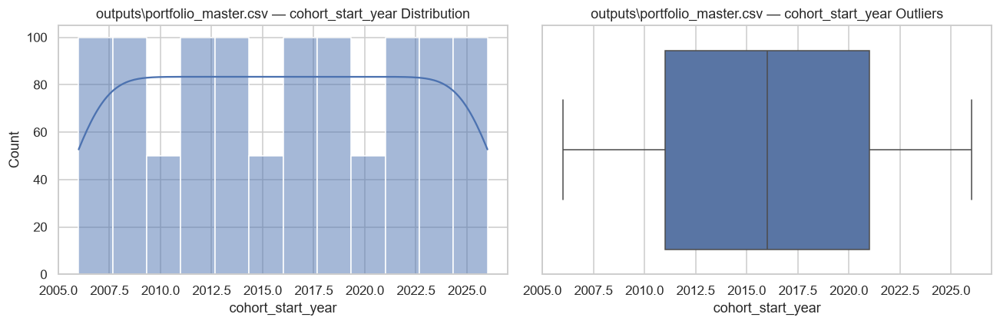

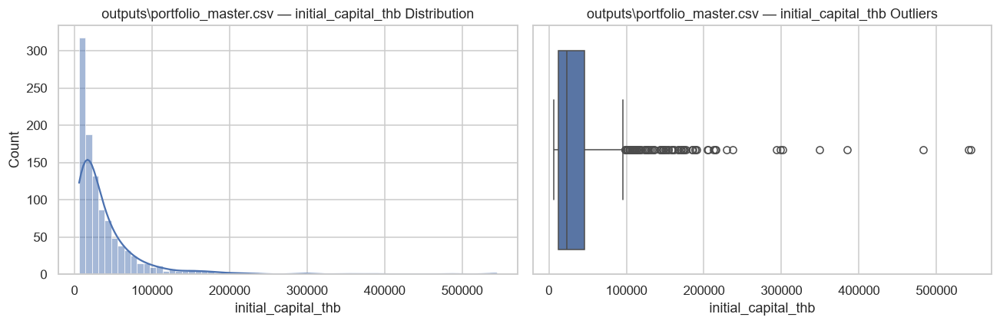

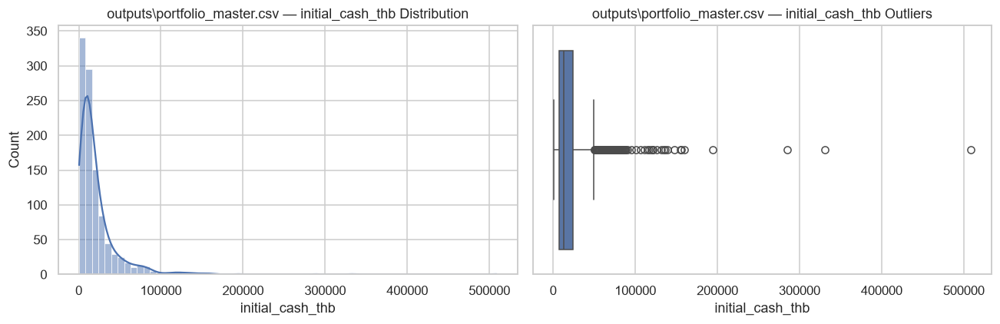

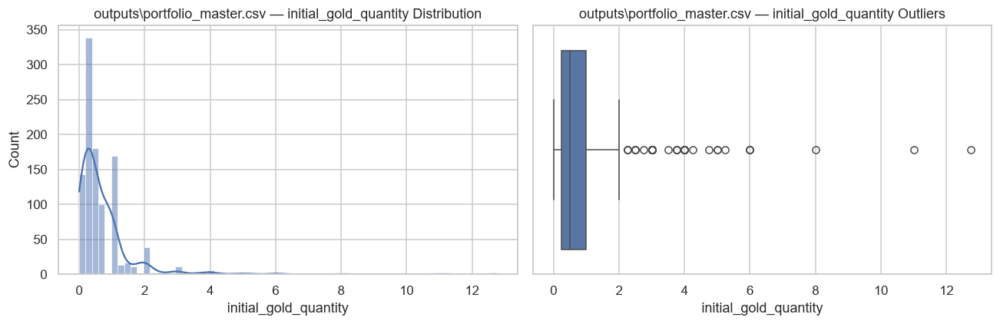

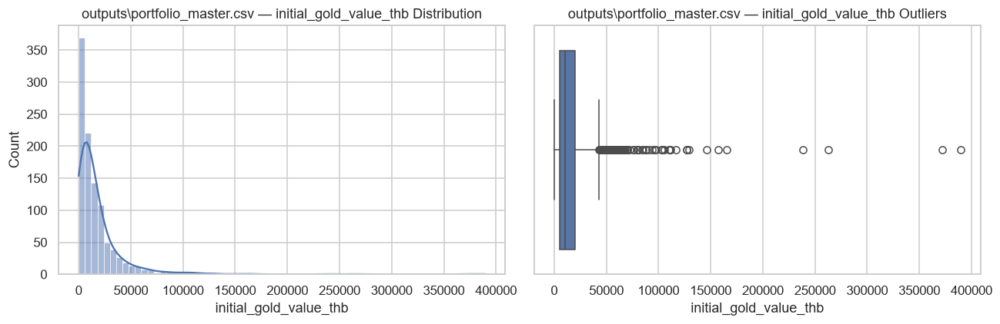


outputs\portfolio_master.parquet: (1050, 16)


,portfolio_id,cohort_start_year,start_timestamp,end_timestamp,portfolio_segment,gold_product_type,initial_capital_thb,initial_cash_thb,initial_gold_quantity,initial_gold_value_thb,behavior_scenario,parameter_set_id,random_seed_id,simulation_run_id,is_synthetic,calibration_status
0,P20060001,2006,2006-06-08,2026-10-22,mass_retail,bar,6000.00,6000.00,0.00,0.0,buy_momentum,PS_R001,seed:20261022:2006:P20060001,R001,True,SCENARIO_ASSUMPTION
1,P20060002,2006,2006-11-18,2026-10-22,mass_retail,ornament,6000.00,3212.50,0.25,2787.5,partial_profit_taking,PS_R001,seed:20261022:2006:P20060002,R001,True,SCENARIO_ASSUMPTION
2,P20060003,2006,2006-05-29,2026-10-22,mass_retail,ornament,8506.68,5444.18,0.25,3062.5,partial_profit_taking,PS_R001,seed:20261022:2006:P20060003,R001,True,SCENARIO_ASSUMPTION
3,P20060004,2006,2006-11-08,2026-10-22,mass_retail,ornament,8272.88,5460.38,0.25,2812.5,inactive,PS_R001,seed:20261022:2006:P20060004,R001,True,SCENARIO_ASSUMPTION
4,P20060005,2006,2006-10-06,2026-10-22,mass_retail,ornament,13494.22,10831.72,0.25,2662.5,dca,PS_R001,seed:20261022:2006:P20060005,R001,True,SCENARIO_ASSUMPTION


,count,mean,std,min,25%,50%,75%,max
cohort_start_year,1050.0,2016.000000,6.058186,2006.0,2011.0000,2016.000,2021.0000,2026.00
initial_capital_thb,1050.0,38924.079143,49237.532129,6000.0,11996.6125,23563.665,46196.8525,544523.64
initial_cash_thb,1050.0,21399.829143,30266.683317,450.0,6890.6025,12579.415,23955.8050,508772.04
initial_gold_quantity,1050.0,0.686190,0.931380,0.0,0.2500,0.500,1.0000,12.75
initial_gold_value_thb,1050.0,17524.250000,27859.405254,0.0,4950.0000,10131.250,20237.5000,389512.50


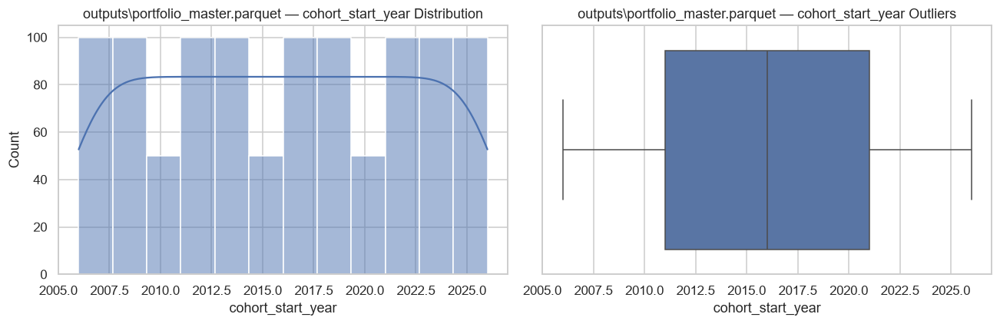

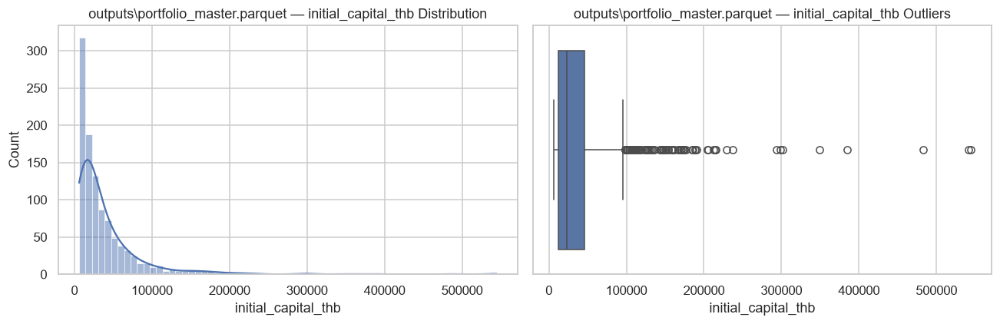

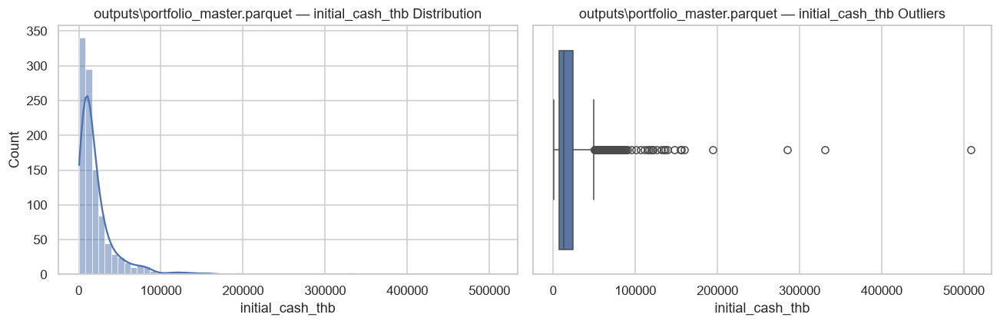

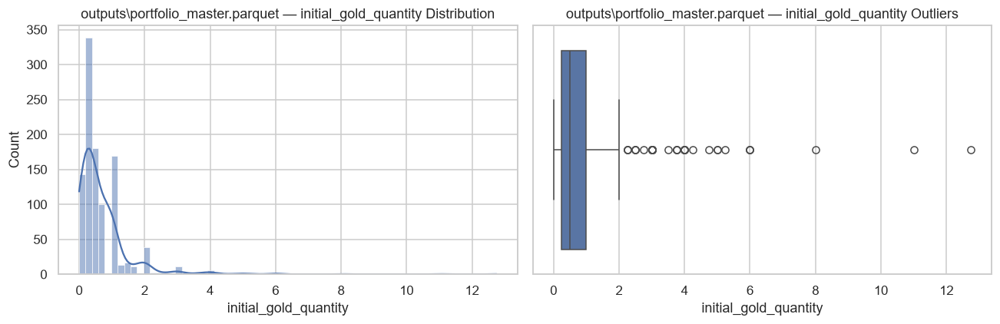

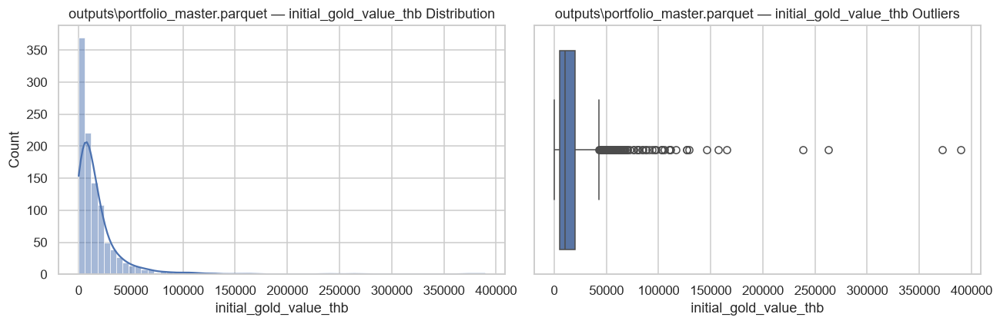


outputs\portfolio_valuation_monthly.csv: (117356, 18)


,portfolio_id,valuation_date,calendar_year,cash_balance_thb,gold_qty_bar_bw,gold_qty_ornament_bw,gold_cost_basis_thb,gold_liquidation_value_thb,portfolio_equity_thb,net_contributed_capital_thb,cumulative_realized_pnl_thb,unrealized_pnl_thb,cumulative_transaction_cost_thb,cumulative_net_pnl_thb,valuation_price_timestamp,valuation_quality_flag,simulation_run_id,is_synthetic
0,P20060001,2006-06-30,2006,6000.0,0.0,0.0,0.0,0.0,6000.0,6000.0,0.0,0.0,0.0,0.0,2006-06-30,OK,R001,True
1,P20060001,2006-07-31,2006,6000.0,0.0,0.0,0.0,0.0,6000.0,6000.0,0.0,0.0,0.0,0.0,2006-07-31,OK,R001,True
2,P20060001,2006-08-31,2006,6000.0,0.0,0.0,0.0,0.0,6000.0,6000.0,0.0,0.0,0.0,0.0,2006-08-31,OK,R001,True
3,P20060001,2006-09-30,2006,6000.0,0.0,0.0,0.0,0.0,6000.0,6000.0,0.0,0.0,0.0,0.0,2006-09-30,OK,R001,True
4,P20060001,2006-10-31,2006,6000.0,0.0,0.0,0.0,0.0,6000.0,6000.0,0.0,0.0,0.0,0.0,2006-10-31,OK,R001,True


,count,mean,std,min,25%,50%,75%,max
calendar_year,117356.0,2019.411619,4.997799,2006.000000,2016.000000,2020.000,2024.000000,2.026000e+03
cash_balance_thb,117356.0,17448.567239,22656.034021,0.000000,6037.470000,10650.650,21812.210800,6.674039e+05
gold_qty_bar_bw,117356.0,0.385846,1.342831,0.000000,0.000000,0.000,0.000000,2.000000e+01
gold_qty_ornament_bw,117356.0,0.564478,1.348093,0.000000,0.000000,0.160,0.500000,1.300000e+01
gold_cost_basis_thb,117356.0,19998.820540,38652.708597,0.000000,72.958314,5650.000,19375.000000,5.141500e+05
gold_liquidation_value_thb,117356.0,30745.979501,71051.151712,0.000000,101.912181,8500.000,27200.801784,1.548000e+06
portfolio_equity_thb,117356.0,48194.546740,75848.799609,0.000000,11823.100000,24749.215,50772.754538,1.600085e+06
net_contributed_capital_thb,117356.0,36639.599551,45116.729406,-70400.000000,10399.640000,21829.150,42253.407500,5.758720e+05
cumulative_realized_pnl_thb,117356.0,807.788228,4774.072169,-25980.515221,0.000000,0.000,10.156250,2.370520e+05
unrealized_pnl_thb,117356.0,10747.158961,39313.921959,-71725.000000,0.000000,525.000,6137.522192,1.137950e+06


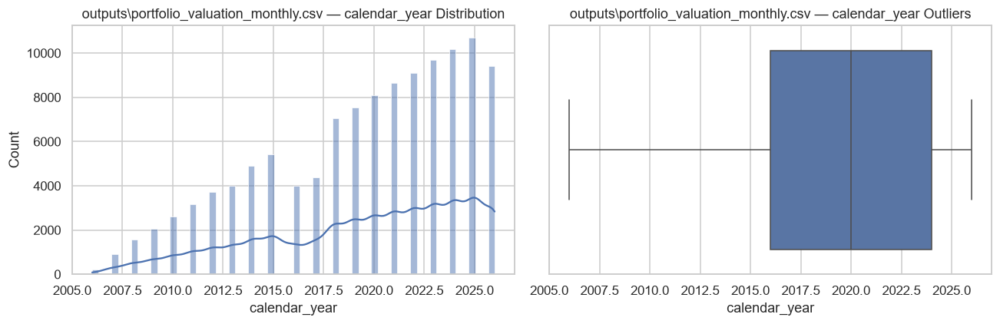

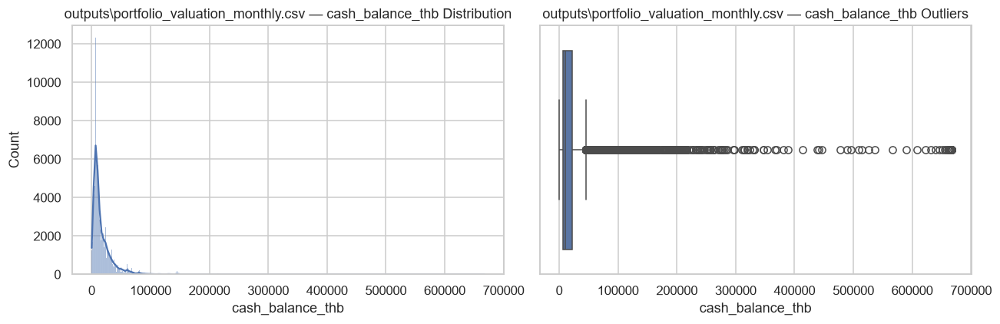

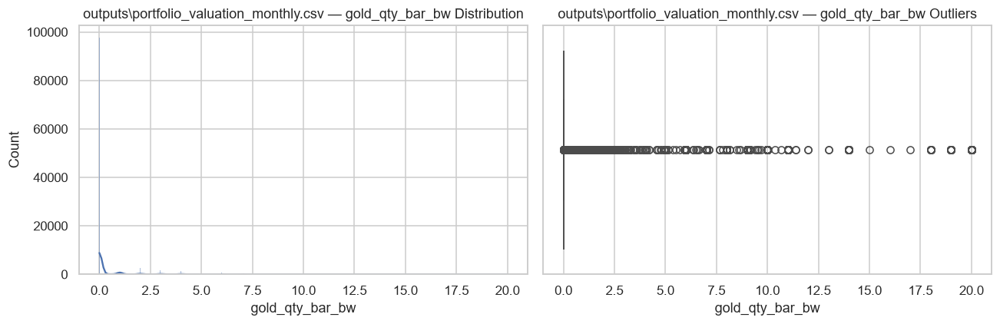

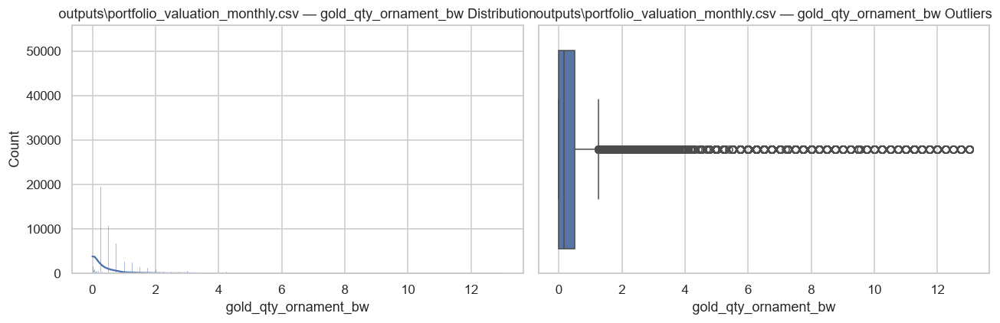

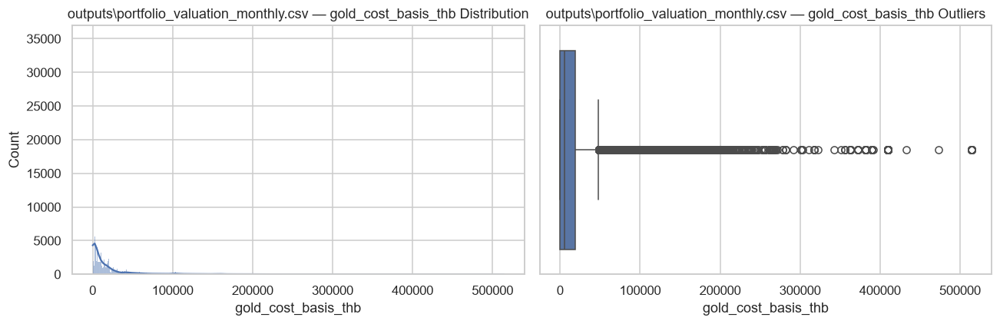

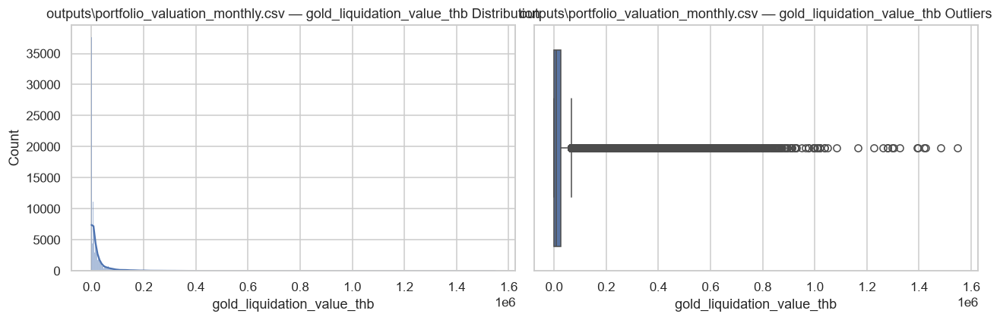


outputs\portfolio_valuation_monthly.parquet: (117356, 18)


,portfolio_id,valuation_date,calendar_year,cash_balance_thb,gold_qty_bar_bw,gold_qty_ornament_bw,gold_cost_basis_thb,gold_liquidation_value_thb,portfolio_equity_thb,net_contributed_capital_thb,cumulative_realized_pnl_thb,unrealized_pnl_thb,cumulative_transaction_cost_thb,cumulative_net_pnl_thb,valuation_price_timestamp,valuation_quality_flag,simulation_run_id,is_synthetic
0,P20060001,2006-06-30,2006,6000.0,0.0,0.0,0.0,0.0,6000.0,6000.0,0.0,0.0,0.0,0.0,2006-06-30,OK,R001,True
1,P20060001,2006-07-31,2006,6000.0,0.0,0.0,0.0,0.0,6000.0,6000.0,0.0,0.0,0.0,0.0,2006-07-31,OK,R001,True
2,P20060001,2006-08-31,2006,6000.0,0.0,0.0,0.0,0.0,6000.0,6000.0,0.0,0.0,0.0,0.0,2006-08-31,OK,R001,True
3,P20060001,2006-09-30,2006,6000.0,0.0,0.0,0.0,0.0,6000.0,6000.0,0.0,0.0,0.0,0.0,2006-09-30,OK,R001,True
4,P20060001,2006-10-31,2006,6000.0,0.0,0.0,0.0,0.0,6000.0,6000.0,0.0,0.0,0.0,0.0,2006-10-31,OK,R001,True


,count,mean,std,min,25%,50%,75%,max
calendar_year,117356.0,2019.411619,4.997799,2006.000000,2016.000000,2020.000,2024.000000,2.026000e+03
cash_balance_thb,117356.0,17448.567239,22656.034021,0.000000,6037.470000,10650.650,21812.210800,6.674039e+05
gold_qty_bar_bw,117356.0,0.385846,1.342831,0.000000,0.000000,0.000,0.000000,2.000000e+01
gold_qty_ornament_bw,117356.0,0.564478,1.348093,0.000000,0.000000,0.160,0.500000,1.300000e+01
gold_cost_basis_thb,117356.0,19998.820540,38652.708597,0.000000,72.958314,5650.000,19375.000000,5.141500e+05
gold_liquidation_value_thb,117356.0,30745.979501,71051.151712,0.000000,101.912181,8500.000,27200.801784,1.548000e+06
portfolio_equity_thb,117356.0,48194.546740,75848.799609,0.000000,11823.100000,24749.215,50772.754538,1.600085e+06
net_contributed_capital_thb,117356.0,36639.599551,45116.729406,-70400.000000,10399.640000,21829.150,42253.407500,5.758720e+05
cumulative_realized_pnl_thb,117356.0,807.788228,4774.072169,-25980.515221,0.000000,0.000,10.156250,2.370520e+05
unrealized_pnl_thb,117356.0,10747.158961,39313.921959,-71725.000000,0.000000,525.000,6137.522192,1.137950e+06


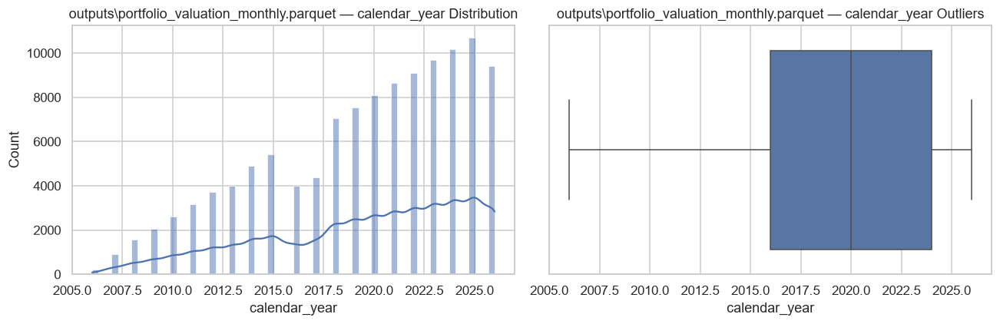

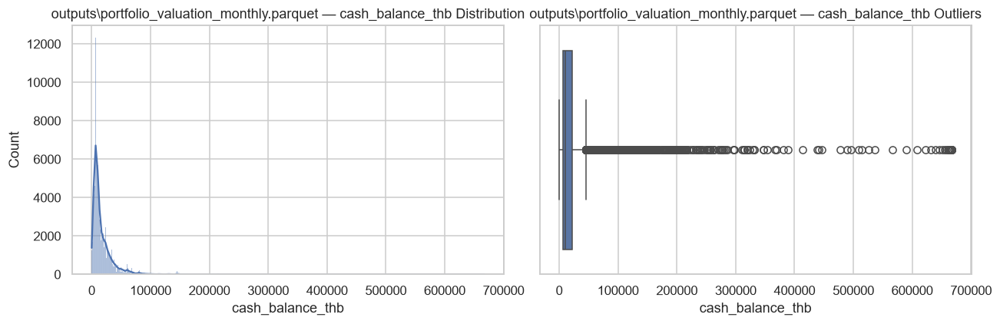

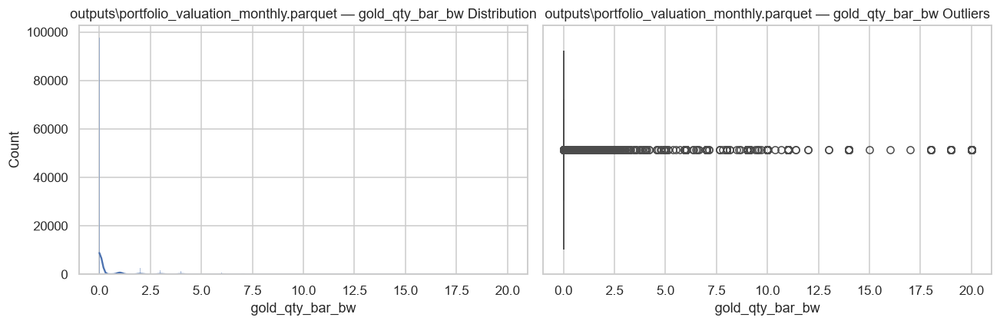

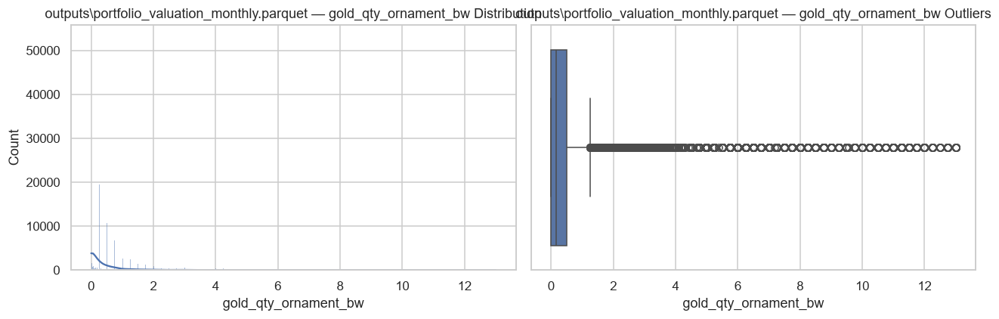

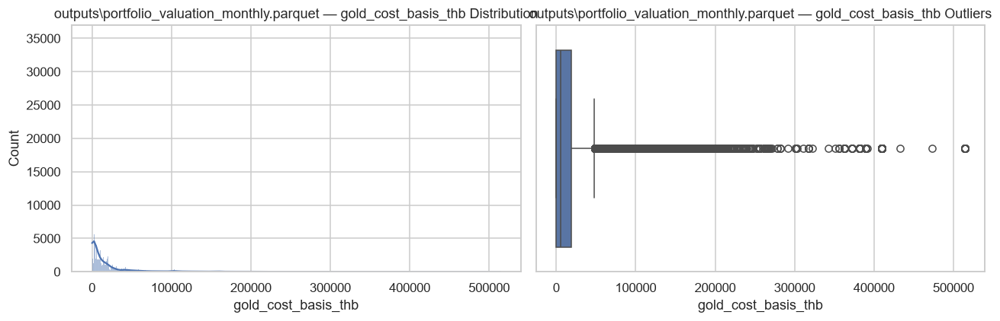

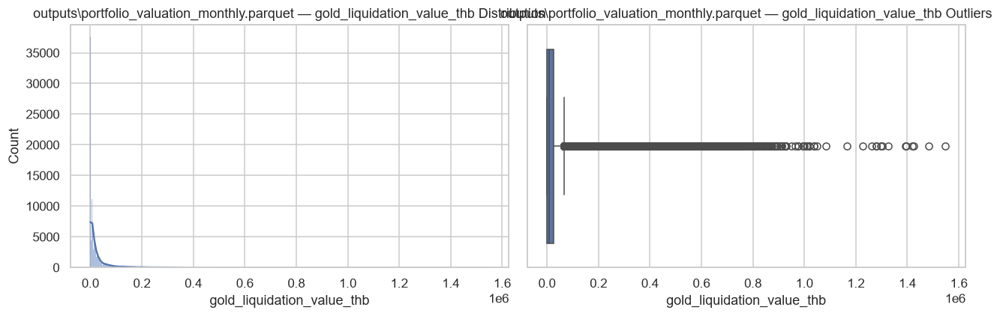


outputs\portfolio_yearly.csv: (10845, 27)


,portfolio_id,cohort_start_year,calendar_year,is_partial_year,year_start_date,year_end_date,beginning_equity_thb,ending_equity_thb,external_contributions_thb,external_withdrawals_thb,purchase_count,sale_count,gross_purchase_value_thb,gross_sale_value_thb,transaction_cost_thb,realized_pnl_thb,unrealized_pnl_thb,net_pnl_thb,annual_return,max_drawdown,data_coverage_ratio,calculation_quality_flag,benchmark_id,simulation_run_id,is_synthetic,benchmark_cum_net_pnl_thb,cum_net_pnl_thb
0,P20060001,2006,2006,True,2006-06-08,2006-12-30,0.0,6000.0,6000.0,0.0,0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,OK,BH_BAR_SAME_FLOWS,R001,True,-342.105263,0.0
1,P20060001,2006,2007,False,2007-01-01,2007-12-29,6000.0,6000.0,0.0,0.0,0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,OK,BH_BAR_SAME_FLOWS,R001,True,947.368421,0.0
2,P20060001,2006,2008,False,2008-01-01,2008-12-30,6000.0,6000.0,0.0,0.0,0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,OK,BH_BAR_SAME_FLOWS,R001,True,1315.789474,0.0
3,P20060001,2006,2009,False,2009-01-01,2009-12-30,6000.0,6000.0,0.0,0.0,0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,OK,BH_BAR_SAME_FLOWS,R001,True,3078.947368,0.0
4,P20060001,2006,2010,False,2010-01-01,2010-12-30,6000.0,6000.0,0.0,0.0,0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,OK,BH_BAR_SAME_FLOWS,R001,True,4552.631579,0.0


,count,mean,std,min,25%,50%,75%,max
cohort_start_year,10845.0,2012.680037,5.097968,2006.000000,2008.000000,2012.000000,2016.000000,2.026000e+03
calendar_year,10845.0,2019.229691,5.089687,2006.000000,2016.000000,2020.000000,2024.000000,2.026000e+03
beginning_equity_thb,10845.0,40989.729253,67067.017678,0.000000,9302.060000,21056.802500,44614.730000,1.347085e+06
ending_equity_thb,10845.0,49062.572535,78916.569548,0.000000,11665.772650,24686.510055,51702.100000,1.362085e+06
external_contributions_thb,10845.0,4821.695076,19366.157151,0.000000,0.000000,0.000000,0.000000,5.448720e+05
external_withdrawals_thb,10845.0,342.258898,5735.723517,0.000000,0.000000,0.000000,0.000000,3.641069e+05
purchase_count,10845.0,0.410143,1.114344,0.000000,0.000000,0.000000,0.000000,1.200000e+01
sale_count,10845.0,1.280682,2.767946,0.000000,0.000000,0.000000,1.000000,1.200000e+01
gross_purchase_value_thb,10845.0,5423.299908,19876.097810,0.000000,0.000000,0.000000,0.000000,5.439500e+05
gross_sale_value_thb,10845.0,3304.773088,17325.513495,0.000000,0.000000,0.000000,0.057152,4.993516e+05


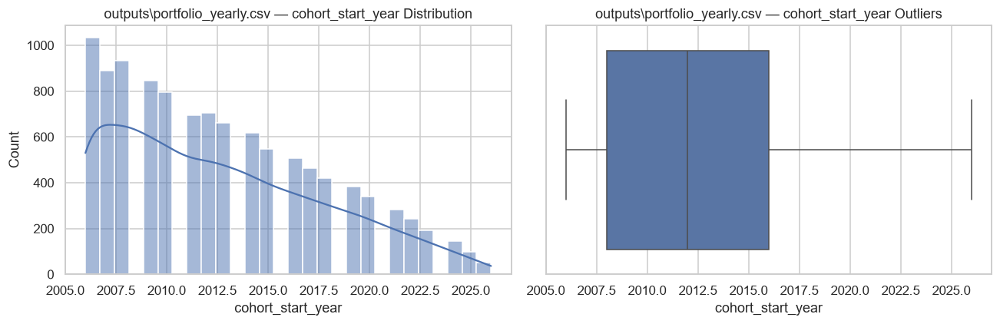

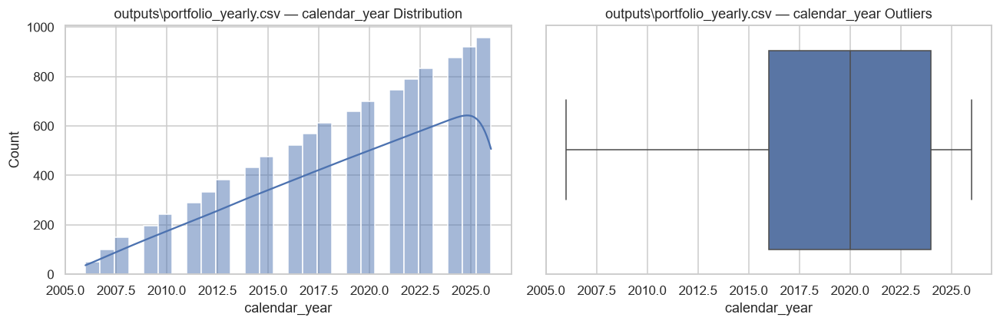

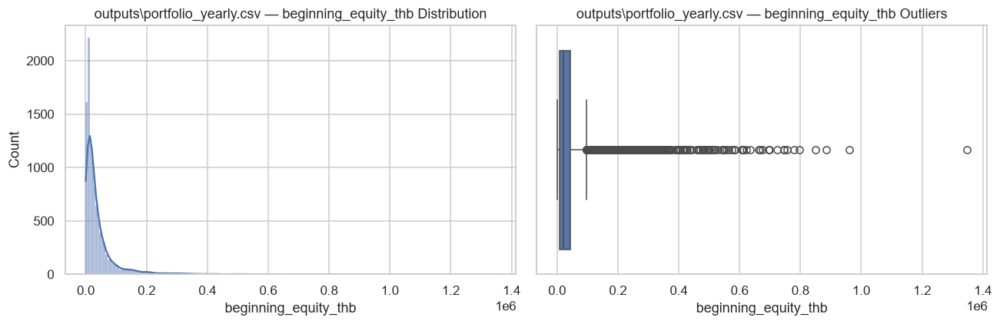

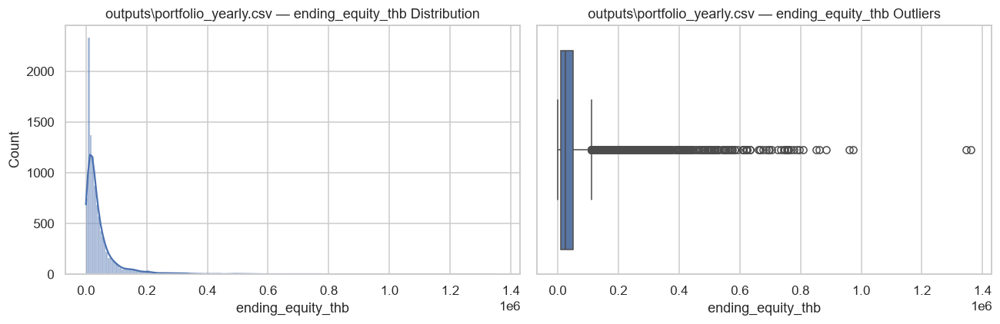

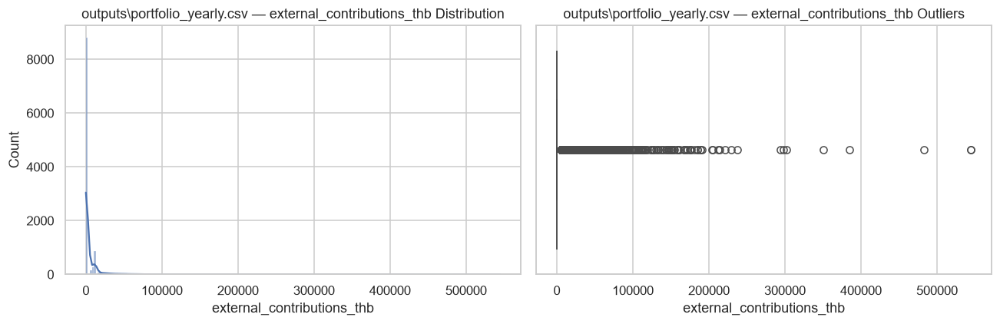

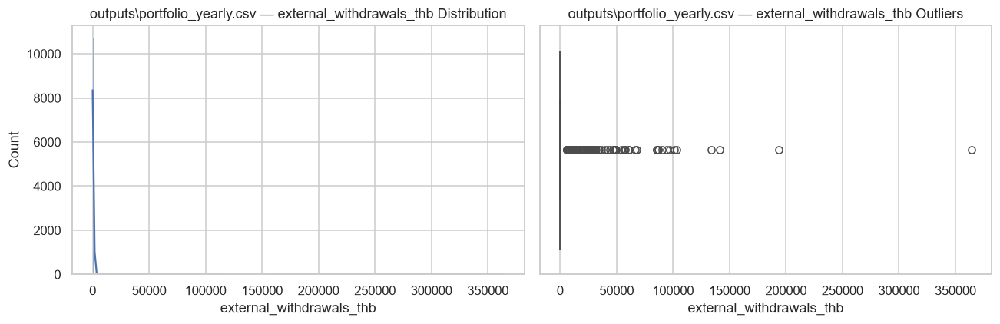


outputs\portfolio_yearly.parquet: (10845, 27)


,portfolio_id,cohort_start_year,calendar_year,is_partial_year,year_start_date,year_end_date,beginning_equity_thb,ending_equity_thb,external_contributions_thb,external_withdrawals_thb,purchase_count,sale_count,gross_purchase_value_thb,gross_sale_value_thb,transaction_cost_thb,realized_pnl_thb,unrealized_pnl_thb,net_pnl_thb,annual_return,max_drawdown,data_coverage_ratio,calculation_quality_flag,benchmark_id,simulation_run_id,is_synthetic,benchmark_cum_net_pnl_thb,cum_net_pnl_thb
0,P20060001,2006,2006,True,2006-06-08,2006-12-30,0.0,6000.0,6000.0,0.0,0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,OK,BH_BAR_SAME_FLOWS,R001,True,-342.105263,0.0
1,P20060001,2006,2007,False,2007-01-01,2007-12-29,6000.0,6000.0,0.0,0.0,0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,OK,BH_BAR_SAME_FLOWS,R001,True,947.368421,0.0
2,P20060001,2006,2008,False,2008-01-01,2008-12-30,6000.0,6000.0,0.0,0.0,0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,OK,BH_BAR_SAME_FLOWS,R001,True,1315.789474,0.0
3,P20060001,2006,2009,False,2009-01-01,2009-12-30,6000.0,6000.0,0.0,0.0,0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,OK,BH_BAR_SAME_FLOWS,R001,True,3078.947368,0.0
4,P20060001,2006,2010,False,2010-01-01,2010-12-30,6000.0,6000.0,0.0,0.0,0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,OK,BH_BAR_SAME_FLOWS,R001,True,4552.631579,0.0


,count,mean,std,min,25%,50%,75%,max
cohort_start_year,10845.0,2012.680037,5.097968,2006.000000,2008.000000,2012.000000,2016.000000,2.026000e+03
calendar_year,10845.0,2019.229691,5.089687,2006.000000,2016.000000,2020.000000,2024.000000,2.026000e+03
beginning_equity_thb,10845.0,40989.729253,67067.017678,0.000000,9302.060000,21056.802500,44614.730000,1.347085e+06
ending_equity_thb,10845.0,49062.572535,78916.569548,0.000000,11665.772650,24686.510055,51702.100000,1.362085e+06
external_contributions_thb,10845.0,4821.695076,19366.157151,0.000000,0.000000,0.000000,0.000000,5.448720e+05
external_withdrawals_thb,10845.0,342.258898,5735.723517,0.000000,0.000000,0.000000,0.000000,3.641069e+05
purchase_count,10845.0,0.410143,1.114344,0.000000,0.000000,0.000000,0.000000,1.200000e+01
sale_count,10845.0,1.280682,2.767946,0.000000,0.000000,0.000000,1.000000,1.200000e+01
gross_purchase_value_thb,10845.0,5423.299908,19876.097810,0.000000,0.000000,0.000000,0.000000,5.439500e+05
gross_sale_value_thb,10845.0,3304.773088,17325.513495,0.000000,0.000000,0.000000,0.057152,4.993516e+05


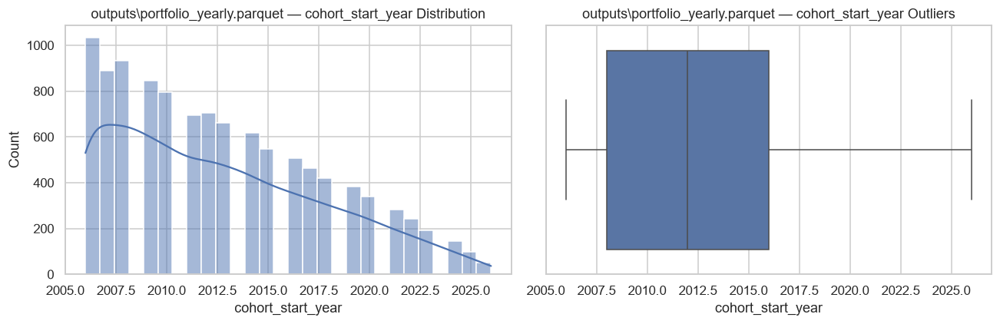

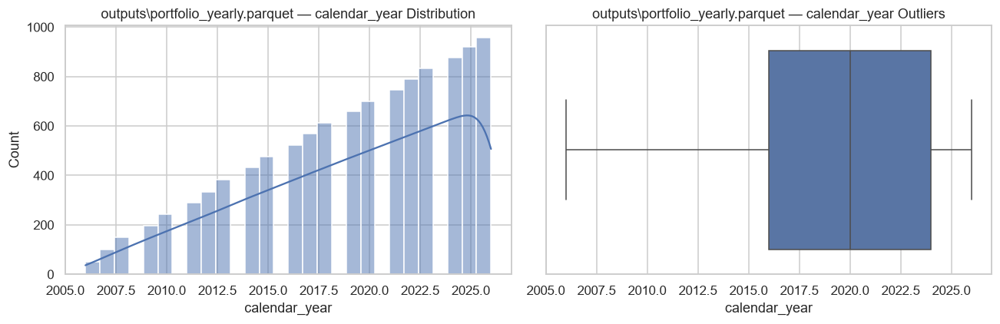

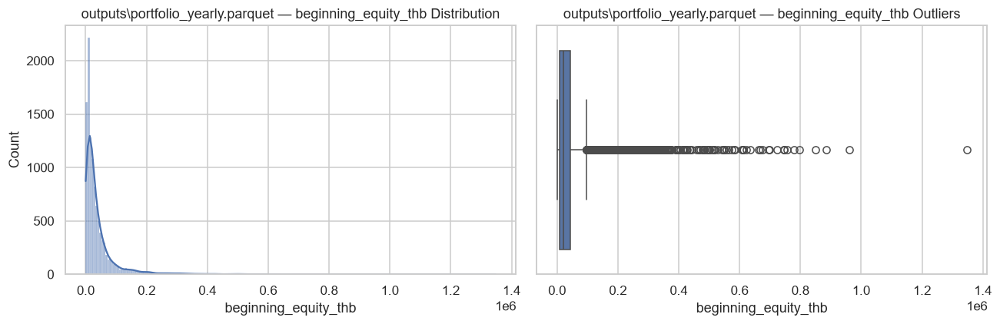

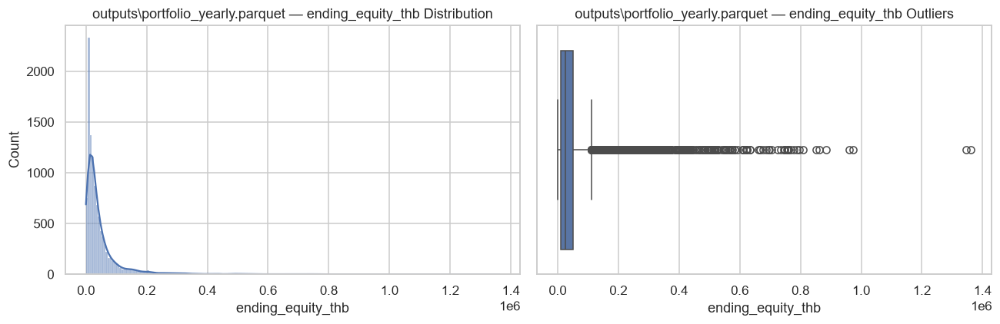

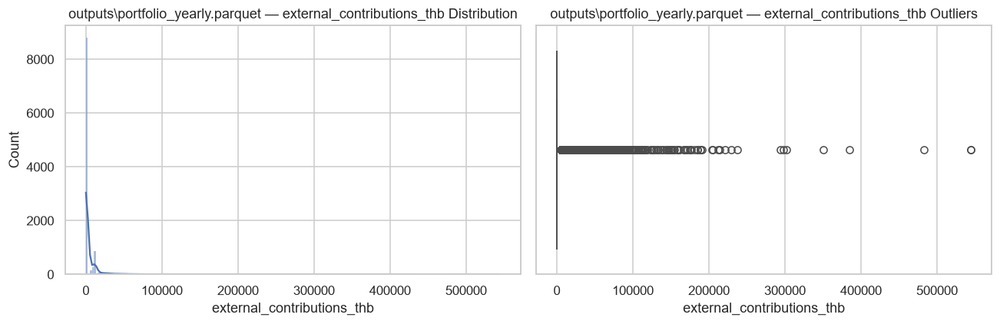

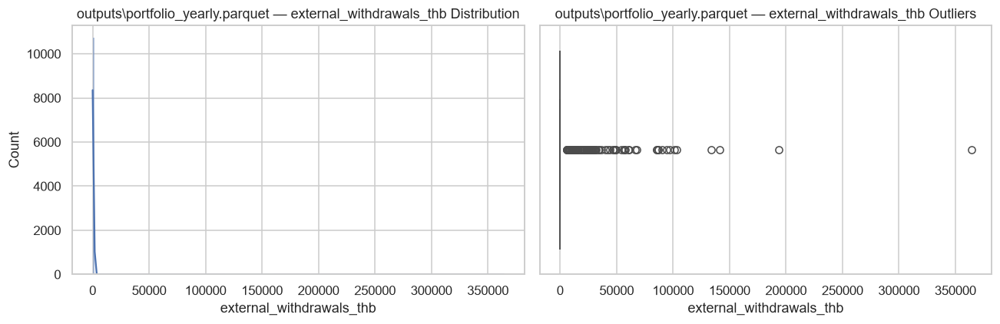


outputs\sensitivity_analysis.csv: (6, 8)


,variant,n_portfolios,mean_annual_return,loss_year_share,loss_lifetime_share,median_lifetime_pnl_thb,mean_costs_frac_gross,tx_per_portfolio
0,base,200,0.047912,0.175990,0.055,75.000000,0.0,13.465
1,capital_low,200,0.036497,0.133250,0.025,10.717987,0.0,9.505
2,capital_high,200,0.055824,0.189818,0.065,225.000000,0.0,16.830
3,behavior_dip_heavy,200,0.047979,0.174247,0.060,83.038330,0.0,14.400
4,ornament_wage_high,200,0.046634,0.178504,0.055,75.000000,0.0,13.400


,count,mean,std,min,25%,50%,75%,max
n_portfolios,6.0,200.000000,0.000000,200.000000,200.000000,200.000000,200.000000,200.000000
mean_annual_return,6.0,0.047330,0.006229,0.036497,0.046953,0.047945,0.048845,0.055824
loss_year_share,6.0,0.170671,0.019348,0.133250,0.172726,0.175119,0.177876,0.189818
loss_lifetime_share,6.0,0.050833,0.014289,0.025000,0.047500,0.055000,0.058750,0.065000
median_lifetime_pnl_thb,6.0,90.626053,71.037667,10.717987,75.000000,75.000000,81.028748,225.000000
mean_costs_frac_gross,6.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
tx_per_portfolio,6.0,13.515000,2.360885,9.505000,13.416250,13.477500,14.172500,16.830000


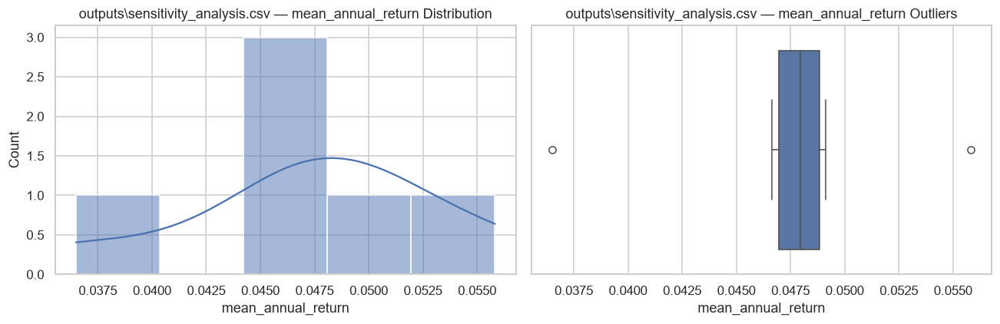

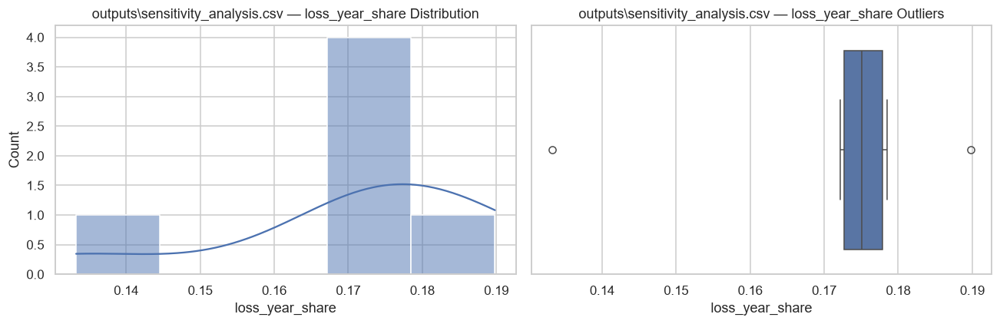

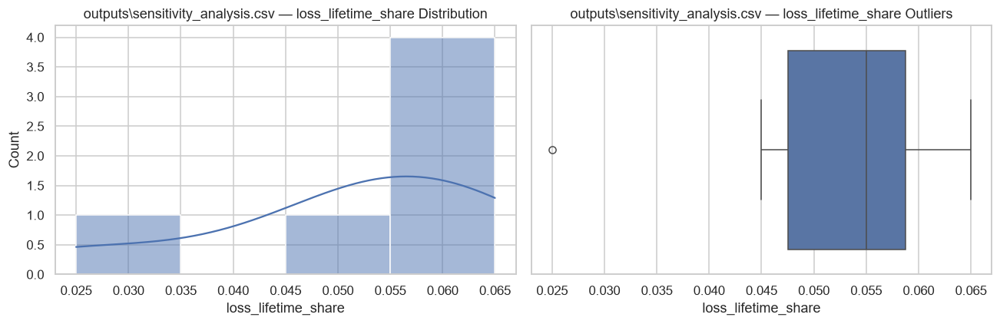

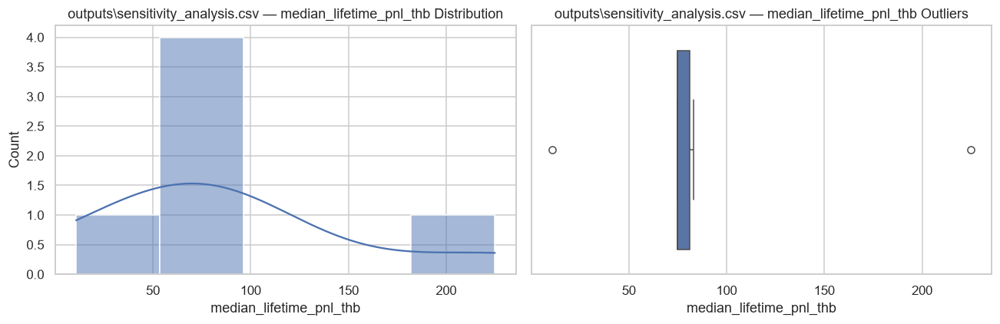


outputs\transaction_ledger.csv: (40089, 22)


,transaction_id,portfolio_id,event_timestamp,calendar_year,event_type,gold_product_type,side,requested_quantity_bw,executed_quantity_bw,price_quote_timestamp,customer_execution_price_thb_per_bw,gross_amount_thb,transaction_cost_thb,net_cash_change_thb,realized_pnl_thb,execution_status,rejection_reason,behavior_scenario,parameter_set_id,simulation_run_id,is_synthetic,source_quote_id
0,P20060001-T00000,P20060001,2006-07-28,2006,GOLD_PURCHASE,bar,BUY,0.251101,0.0,2006-07-28,11350.0,0.0,0.0,0.0,0.0,REJECTED,BELOW_MIN_TRADE_UNIT,buy_momentum,PS_R001,R001,True,GTA:2006-07-28
1,P20060001-T00000,P20060001,2006-08-14,2006,GOLD_PURCHASE,bar,BUY,0.252212,0.0,2006-08-14,11300.0,0.0,0.0,0.0,0.0,REJECTED,BELOW_MIN_TRADE_UNIT,buy_momentum,PS_R001,R001,True,GTA:2006-08-14
2,P20060001-T00000,P20060001,2006-11-27,2006,GOLD_PURCHASE,bar,BUY,0.257919,0.0,2006-11-27,11050.0,0.0,0.0,0.0,0.0,REJECTED,BELOW_MIN_TRADE_UNIT,buy_momentum,PS_R001,R001,True,GTA:2006-11-27
3,P20060001-T00000,P20060001,2007-02-24,2007,GOLD_PURCHASE,bar,BUY,0.248908,0.0,2007-02-24,11450.0,0.0,0.0,0.0,0.0,REJECTED,BELOW_MIN_TRADE_UNIT,buy_momentum,PS_R001,R001,True,GTA:2007-02-24
4,P20060001-T00000,P20060001,2007-03-07,2007,GOLD_PURCHASE,bar,BUY,0.262673,0.0,2007-03-07,10850.0,0.0,0.0,0.0,0.0,REJECTED,BELOW_MIN_TRADE_UNIT,buy_momentum,PS_R001,R001,True,GTA:2007-03-07


,count,mean,std,min,25%,50%,75%,max
calendar_year,40089.0,2019.436604,5.209905,2.006000e+03,2015.000000,2021.000000,2024.000000,2026.00
requested_quantity_bw,37648.0,0.200980,0.325771,2.525521e-10,0.021942,0.119683,0.247454,12.75
executed_quantity_bw,40089.0,0.088093,0.291618,0.000000e+00,0.000000,0.000000,0.011124,12.75
customer_execution_price_thb_per_bw,37648.0,31807.714885,15688.651732,1.035000e+04,20200.000000,26800.000000,35100.000000,81050.00
gross_amount_thb,40089.0,2361.145243,8555.750332,0.000000e+00,0.000000,0.000000,300.338745,389512.50
transaction_cost_thb,40089.0,0.000000,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.00
net_cash_change_thb,40089.0,-573.110413,8857.061924,-3.895125e+05,0.000000,0.000000,0.620077,228000.00
realized_pnl_thb,40089.0,78.226990,945.284786,-5.650000e+03,0.000000,0.000000,0.000754,70400.00


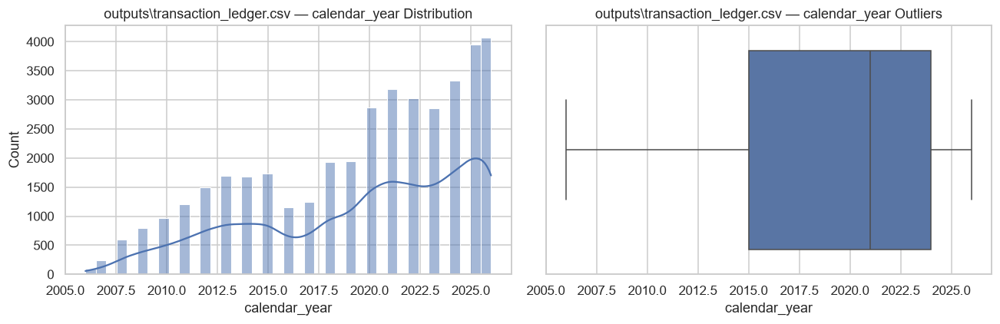

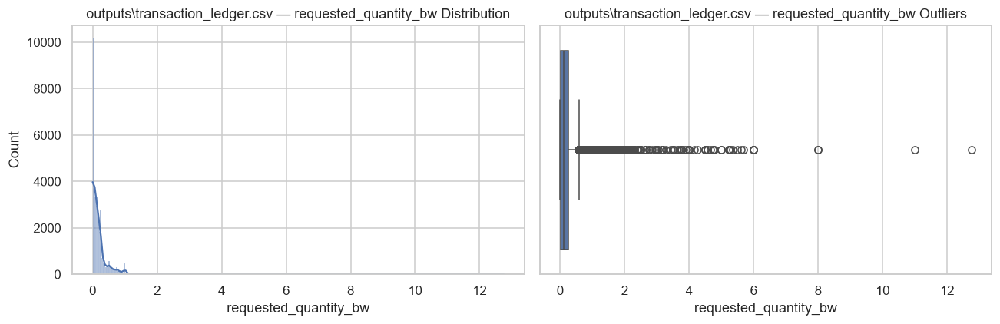

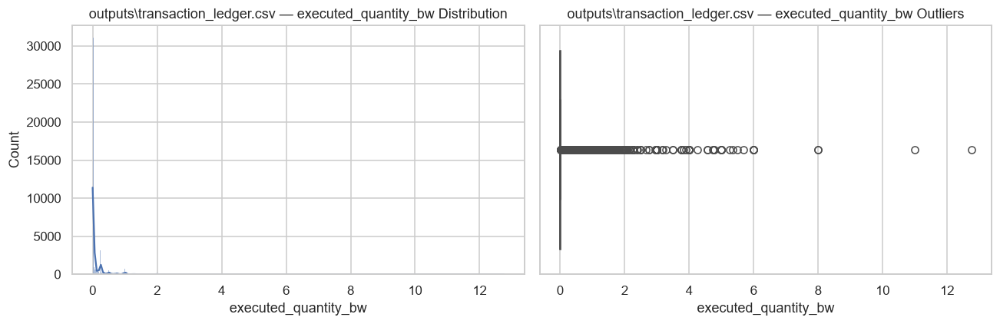

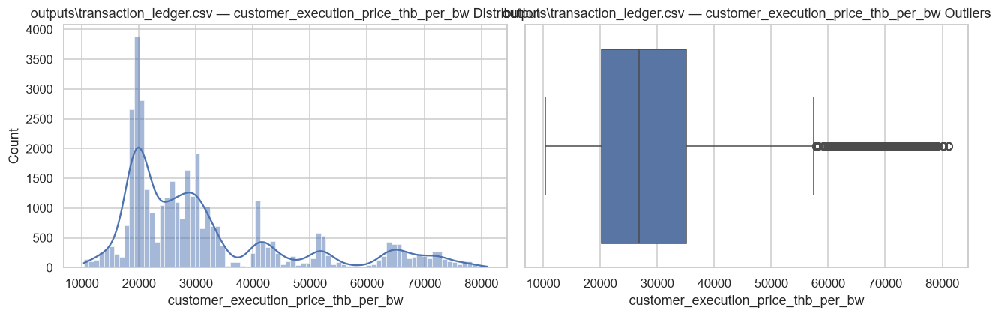

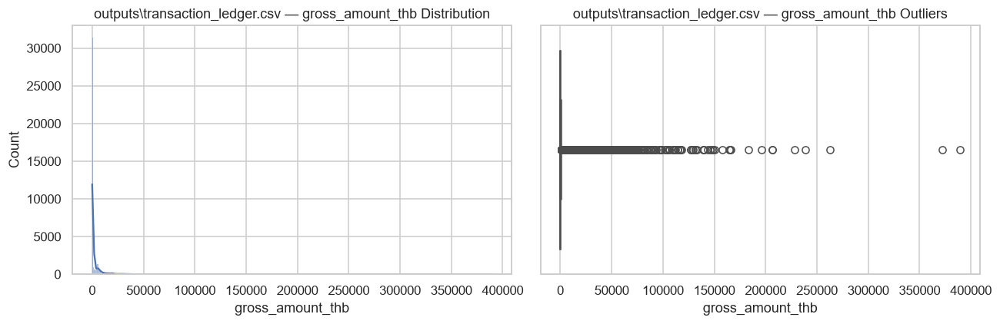


outputs\transaction_ledger.parquet: (40089, 22)


,transaction_id,portfolio_id,event_timestamp,calendar_year,event_type,gold_product_type,side,requested_quantity_bw,executed_quantity_bw,price_quote_timestamp,customer_execution_price_thb_per_bw,gross_amount_thb,transaction_cost_thb,net_cash_change_thb,realized_pnl_thb,execution_status,rejection_reason,behavior_scenario,parameter_set_id,simulation_run_id,is_synthetic,source_quote_id
0,P20060001-T00000,P20060001,2006-07-28,2006,GOLD_PURCHASE,bar,BUY,0.251101,0.0,2006-07-28,11350.0,0.0,0.0,0.0,0.0,REJECTED,BELOW_MIN_TRADE_UNIT,buy_momentum,PS_R001,R001,True,GTA:2006-07-28
1,P20060001-T00000,P20060001,2006-08-14,2006,GOLD_PURCHASE,bar,BUY,0.252212,0.0,2006-08-14,11300.0,0.0,0.0,0.0,0.0,REJECTED,BELOW_MIN_TRADE_UNIT,buy_momentum,PS_R001,R001,True,GTA:2006-08-14
2,P20060001-T00000,P20060001,2006-11-27,2006,GOLD_PURCHASE,bar,BUY,0.257919,0.0,2006-11-27,11050.0,0.0,0.0,0.0,0.0,REJECTED,BELOW_MIN_TRADE_UNIT,buy_momentum,PS_R001,R001,True,GTA:2006-11-27
3,P20060001-T00000,P20060001,2007-02-24,2007,GOLD_PURCHASE,bar,BUY,0.248908,0.0,2007-02-24,11450.0,0.0,0.0,0.0,0.0,REJECTED,BELOW_MIN_TRADE_UNIT,buy_momentum,PS_R001,R001,True,GTA:2007-02-24
4,P20060001-T00000,P20060001,2007-03-07,2007,GOLD_PURCHASE,bar,BUY,0.262673,0.0,2007-03-07,10850.0,0.0,0.0,0.0,0.0,REJECTED,BELOW_MIN_TRADE_UNIT,buy_momentum,PS_R001,R001,True,GTA:2007-03-07


,count,mean,std,min,25%,50%,75%,max
calendar_year,40089.0,2019.436604,5.209905,2.006000e+03,2015.000000,2021.000000,2024.000000,2026.00
requested_quantity_bw,37648.0,0.200980,0.325771,2.525521e-10,0.021942,0.119683,0.247454,12.75
executed_quantity_bw,40089.0,0.088093,0.291618,0.000000e+00,0.000000,0.000000,0.011124,12.75
customer_execution_price_thb_per_bw,37648.0,31807.714885,15688.651732,1.035000e+04,20200.000000,26800.000000,35100.000000,81050.00
gross_amount_thb,40089.0,2361.145243,8555.750332,0.000000e+00,0.000000,0.000000,300.338745,389512.50
transaction_cost_thb,40089.0,0.000000,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.00
net_cash_change_thb,40089.0,-573.110413,8857.061924,-3.895125e+05,0.000000,0.000000,0.620077,228000.00
realized_pnl_thb,40089.0,78.226990,945.284786,-5.650000e+03,0.000000,0.000000,0.000754,70400.00


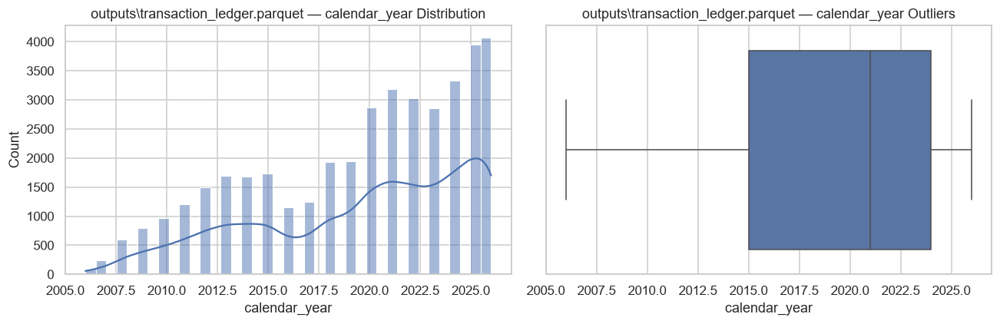

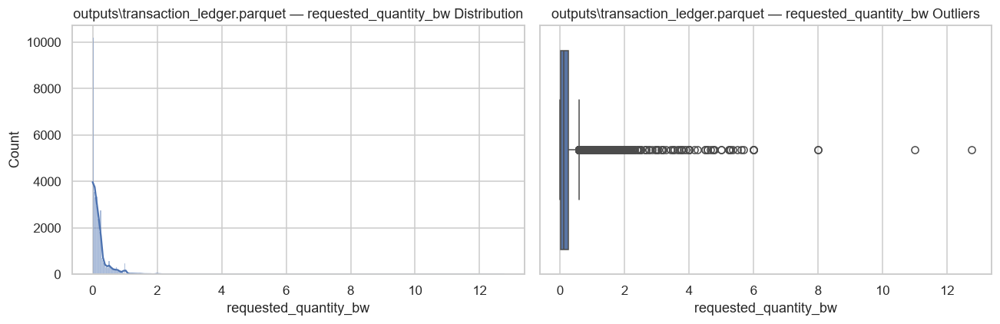

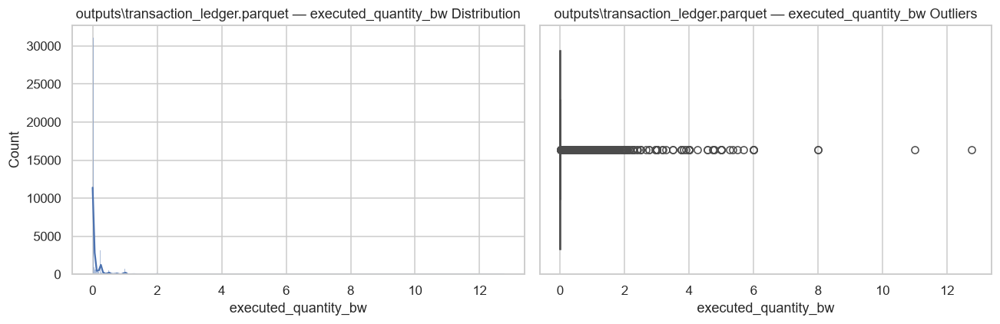

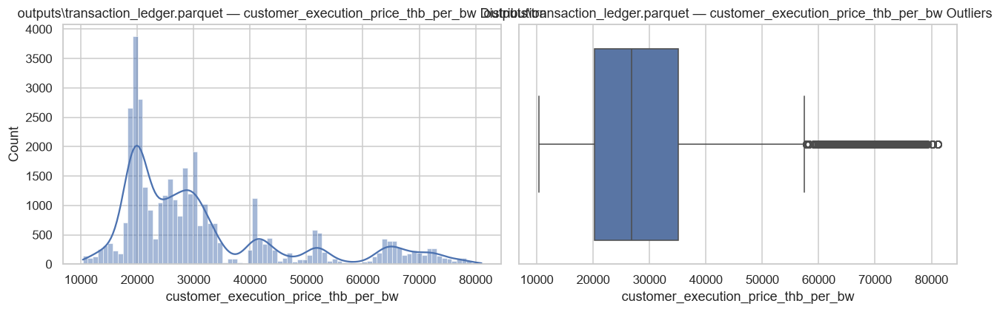

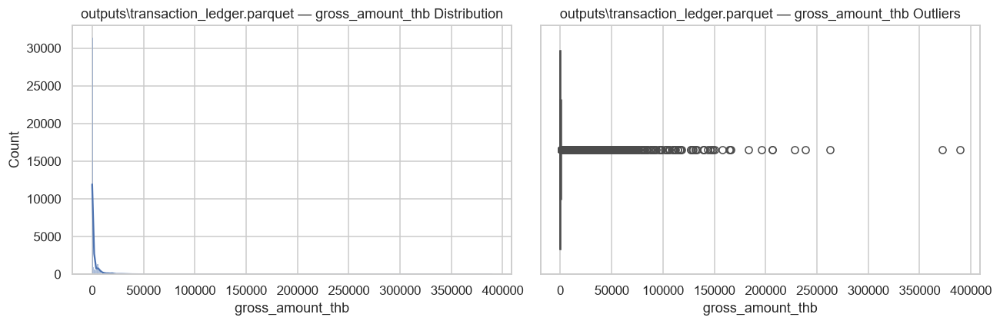


### P&L

outputs\pnl_attribution_yearly.csv: (10845, 14)


,portfolio_id,calendar_year,pnl_total_thb,price_effect_thb,trading_timing_effect_thb,transaction_cost_effect_thb,product_cost_effect_thb,other_modeled_effect_thb,unattributed_residual_thb,benchmark_id,attribution_method,attribution_quality_flag,simulation_run_id,is_synthetic
0,P20060001,2006,0.0,0.0,0.0,-0.0,0.0,0.0,0.0,BH_BAR_SAME_FLOWS,unit_lifecycle_vs_liquidation_quotes_v1,RECONCILED,R001,True
1,P20060001,2007,0.0,0.0,0.0,-0.0,0.0,0.0,0.0,BH_BAR_SAME_FLOWS,unit_lifecycle_vs_liquidation_quotes_v1,RECONCILED,R001,True
2,P20060001,2008,0.0,0.0,0.0,-0.0,0.0,0.0,0.0,BH_BAR_SAME_FLOWS,unit_lifecycle_vs_liquidation_quotes_v1,RECONCILED,R001,True
3,P20060001,2009,0.0,0.0,0.0,-0.0,0.0,0.0,0.0,BH_BAR_SAME_FLOWS,unit_lifecycle_vs_liquidation_quotes_v1,RECONCILED,R001,True
4,P20060001,2010,0.0,0.0,0.0,-0.0,0.0,0.0,0.0,BH_BAR_SAME_FLOWS,unit_lifecycle_vs_liquidation_quotes_v1,RECONCILED,R001,True


,count,mean,std,min,25%,50%,75%,max
calendar_year,10845.0,2.019230e+03,5.089687,2.006000e+03,2016.0,2020.0,2024.0,2026.000000
pnl_total_thb,10845.0,3.593407e+03,16212.375614,-6.198750e+04,0.0,150.0,1800.0,451000.000000
price_effect_thb,10845.0,3.665277e+03,16217.127869,-5.771250e+04,0.0,200.0,1800.0,451000.000000
trading_timing_effect_thb,10845.0,-2.135085e+01,71.915684,-2.000000e+03,0.0,0.0,0.0,0.000000
transaction_cost_effect_thb,10845.0,0.000000e+00,0.000000,-0.000000e+00,0.0,0.0,0.0,-0.000000
product_cost_effect_thb,10845.0,-5.051867e+01,187.328603,-5.100000e+03,0.0,0.0,0.0,0.000000
other_modeled_effect_thb,10845.0,0.000000e+00,0.000000,0.000000e+00,0.0,0.0,0.0,0.000000
unattributed_residual_thb,10845.0,1.440575e-07,0.000002,-2.910383e-11,0.0,0.0,0.0,0.000023


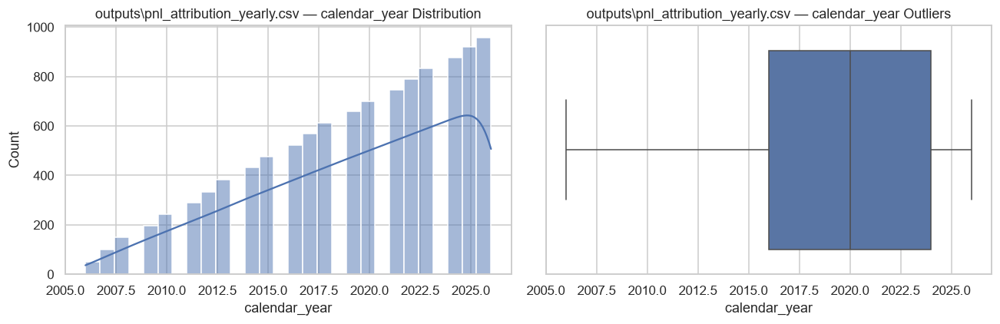

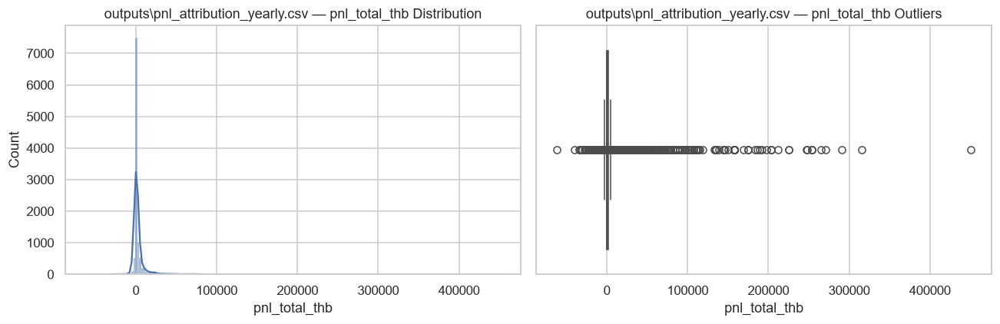

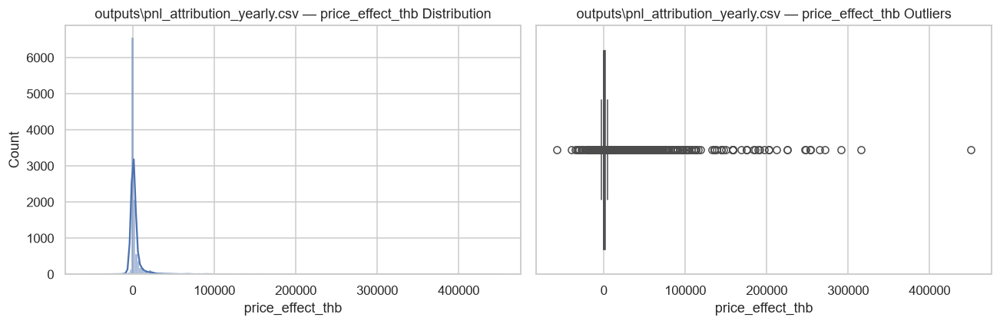

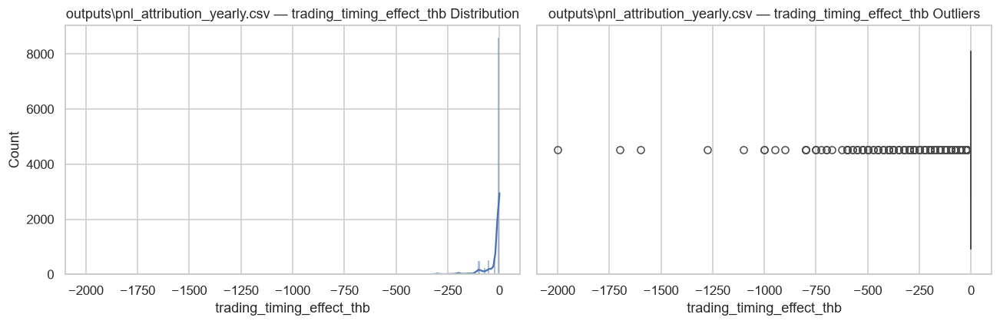

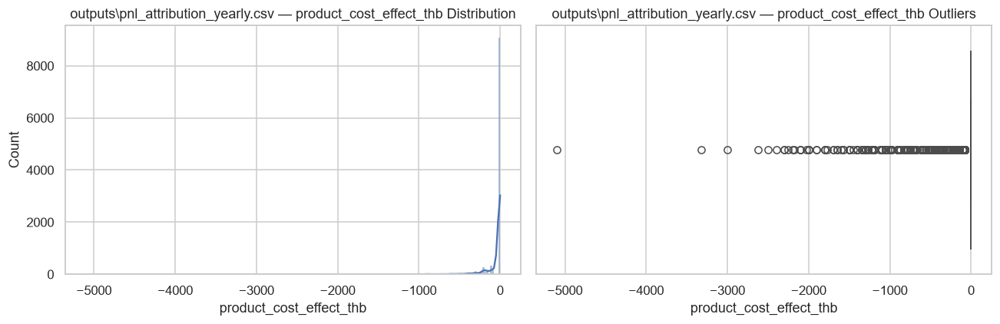


outputs\pnl_attribution_yearly.parquet: (10845, 14)


,portfolio_id,calendar_year,pnl_total_thb,price_effect_thb,trading_timing_effect_thb,transaction_cost_effect_thb,product_cost_effect_thb,other_modeled_effect_thb,unattributed_residual_thb,benchmark_id,attribution_method,attribution_quality_flag,simulation_run_id,is_synthetic
0,P20060001,2006,0.0,0.0,0.0,-0.0,0.0,0.0,0.0,BH_BAR_SAME_FLOWS,unit_lifecycle_vs_liquidation_quotes_v1,RECONCILED,R001,True
1,P20060001,2007,0.0,0.0,0.0,-0.0,0.0,0.0,0.0,BH_BAR_SAME_FLOWS,unit_lifecycle_vs_liquidation_quotes_v1,RECONCILED,R001,True
2,P20060001,2008,0.0,0.0,0.0,-0.0,0.0,0.0,0.0,BH_BAR_SAME_FLOWS,unit_lifecycle_vs_liquidation_quotes_v1,RECONCILED,R001,True
3,P20060001,2009,0.0,0.0,0.0,-0.0,0.0,0.0,0.0,BH_BAR_SAME_FLOWS,unit_lifecycle_vs_liquidation_quotes_v1,RECONCILED,R001,True
4,P20060001,2010,0.0,0.0,0.0,-0.0,0.0,0.0,0.0,BH_BAR_SAME_FLOWS,unit_lifecycle_vs_liquidation_quotes_v1,RECONCILED,R001,True


,count,mean,std,min,25%,50%,75%,max
calendar_year,10845.0,2.019230e+03,5.089687,2.006000e+03,2016.0,2020.0,2024.0,2026.000000
pnl_total_thb,10845.0,3.593407e+03,16212.375614,-6.198750e+04,0.0,150.0,1800.0,451000.000000
price_effect_thb,10845.0,3.665277e+03,16217.127869,-5.771250e+04,0.0,200.0,1800.0,451000.000000
trading_timing_effect_thb,10845.0,-2.135085e+01,71.915684,-2.000000e+03,0.0,0.0,0.0,0.000000
transaction_cost_effect_thb,10845.0,0.000000e+00,0.000000,-0.000000e+00,0.0,0.0,0.0,-0.000000
product_cost_effect_thb,10845.0,-5.051867e+01,187.328603,-5.100000e+03,0.0,0.0,0.0,0.000000
other_modeled_effect_thb,10845.0,0.000000e+00,0.000000,0.000000e+00,0.0,0.0,0.0,0.000000
unattributed_residual_thb,10845.0,1.440575e-07,0.000002,-2.910383e-11,0.0,0.0,0.0,0.000023


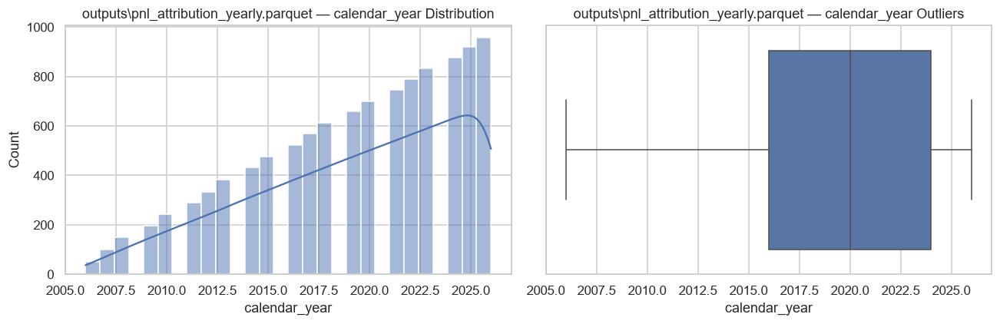

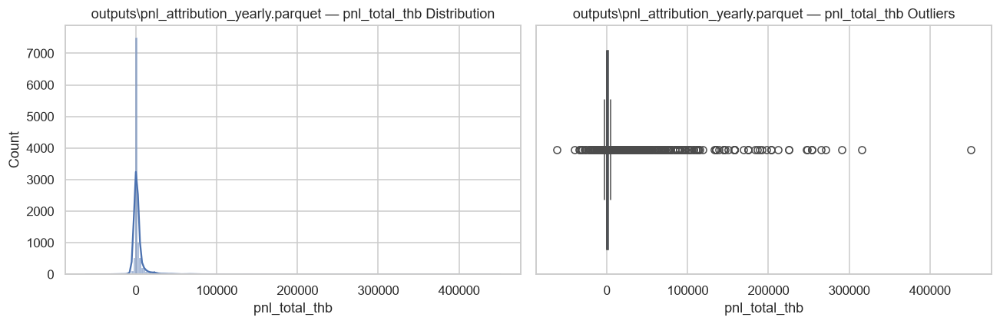

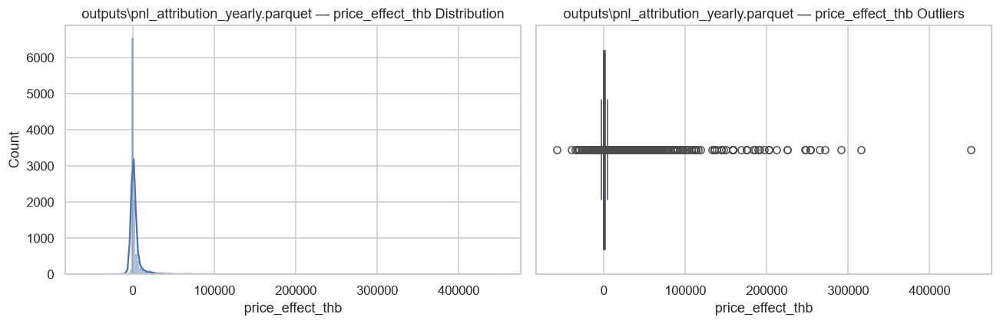

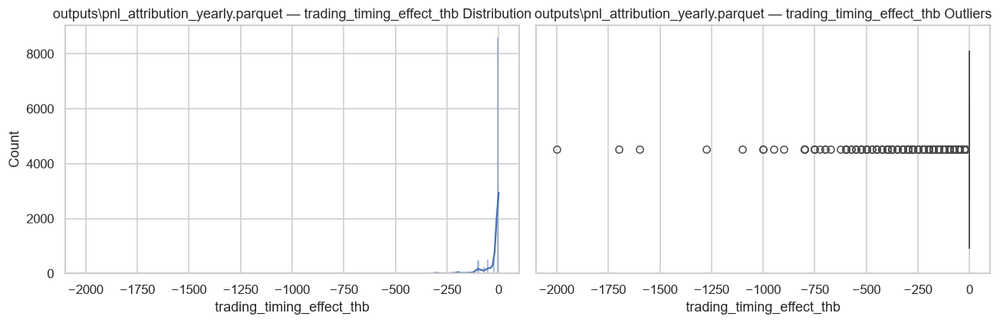

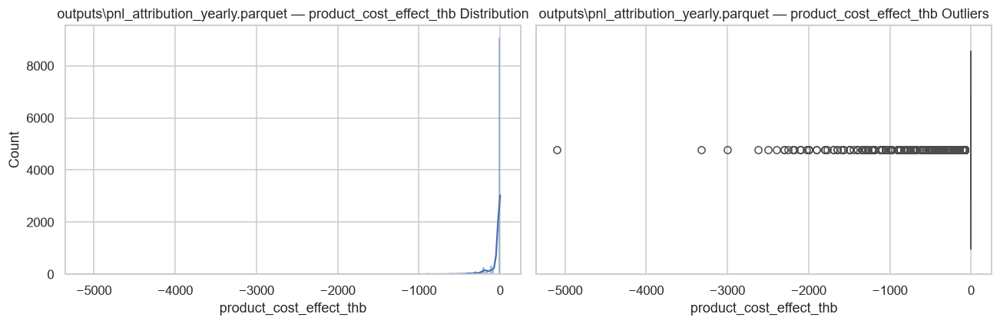


outputs\portfolio_valuation_monthly.csv: (117356, 18)


,portfolio_id,valuation_date,calendar_year,cash_balance_thb,gold_qty_bar_bw,gold_qty_ornament_bw,gold_cost_basis_thb,gold_liquidation_value_thb,portfolio_equity_thb,net_contributed_capital_thb,cumulative_realized_pnl_thb,unrealized_pnl_thb,cumulative_transaction_cost_thb,cumulative_net_pnl_thb,valuation_price_timestamp,valuation_quality_flag,simulation_run_id,is_synthetic
0,P20060001,2006-06-30,2006,6000.0,0.0,0.0,0.0,0.0,6000.0,6000.0,0.0,0.0,0.0,0.0,2006-06-30,OK,R001,True
1,P20060001,2006-07-31,2006,6000.0,0.0,0.0,0.0,0.0,6000.0,6000.0,0.0,0.0,0.0,0.0,2006-07-31,OK,R001,True
2,P20060001,2006-08-31,2006,6000.0,0.0,0.0,0.0,0.0,6000.0,6000.0,0.0,0.0,0.0,0.0,2006-08-31,OK,R001,True
3,P20060001,2006-09-30,2006,6000.0,0.0,0.0,0.0,0.0,6000.0,6000.0,0.0,0.0,0.0,0.0,2006-09-30,OK,R001,True
4,P20060001,2006-10-31,2006,6000.0,0.0,0.0,0.0,0.0,6000.0,6000.0,0.0,0.0,0.0,0.0,2006-10-31,OK,R001,True


,count,mean,std,min,25%,50%,75%,max
calendar_year,117356.0,2019.411619,4.997799,2006.000000,2016.000000,2020.000,2024.000000,2.026000e+03
cash_balance_thb,117356.0,17448.567239,22656.034021,0.000000,6037.470000,10650.650,21812.210800,6.674039e+05
gold_qty_bar_bw,117356.0,0.385846,1.342831,0.000000,0.000000,0.000,0.000000,2.000000e+01
gold_qty_ornament_bw,117356.0,0.564478,1.348093,0.000000,0.000000,0.160,0.500000,1.300000e+01
gold_cost_basis_thb,117356.0,19998.820540,38652.708597,0.000000,72.958314,5650.000,19375.000000,5.141500e+05
gold_liquidation_value_thb,117356.0,30745.979501,71051.151712,0.000000,101.912181,8500.000,27200.801784,1.548000e+06
portfolio_equity_thb,117356.0,48194.546740,75848.799609,0.000000,11823.100000,24749.215,50772.754538,1.600085e+06
net_contributed_capital_thb,117356.0,36639.599551,45116.729406,-70400.000000,10399.640000,21829.150,42253.407500,5.758720e+05
cumulative_realized_pnl_thb,117356.0,807.788228,4774.072169,-25980.515221,0.000000,0.000,10.156250,2.370520e+05
unrealized_pnl_thb,117356.0,10747.158961,39313.921959,-71725.000000,0.000000,525.000,6137.522192,1.137950e+06


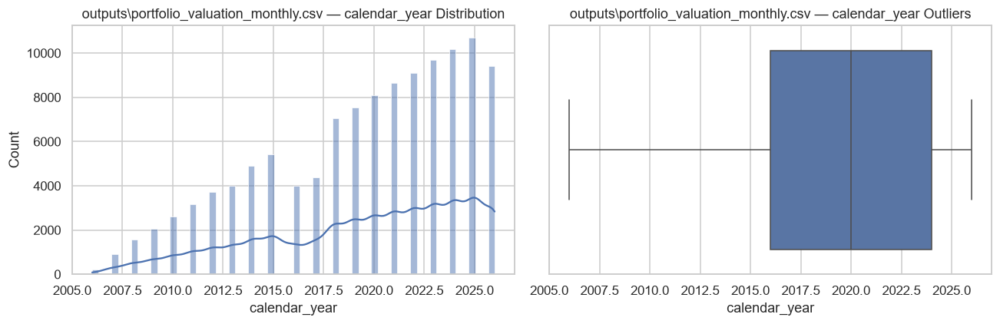

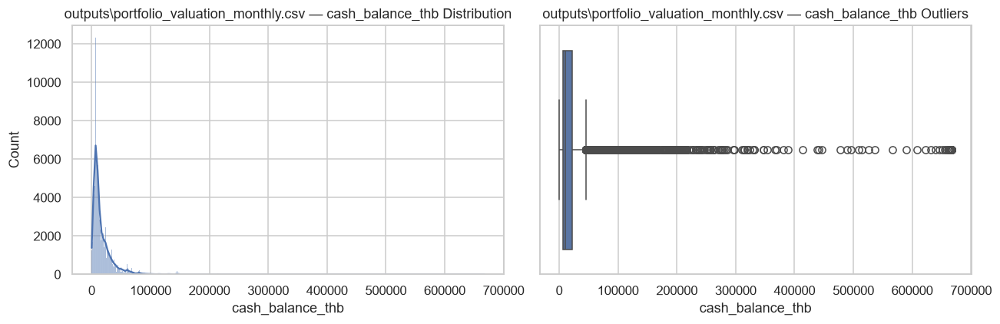

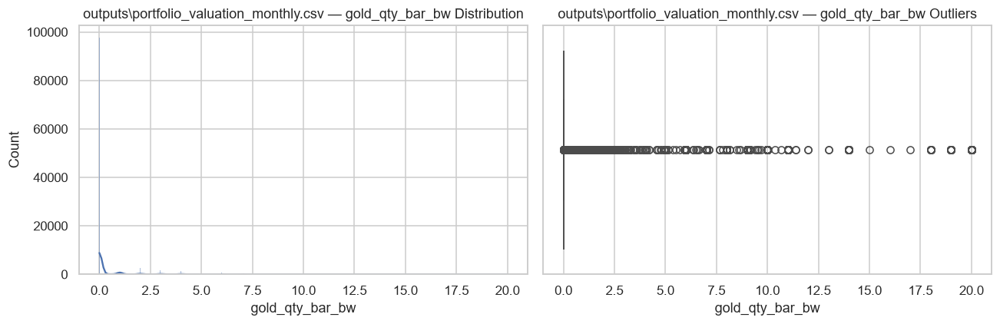

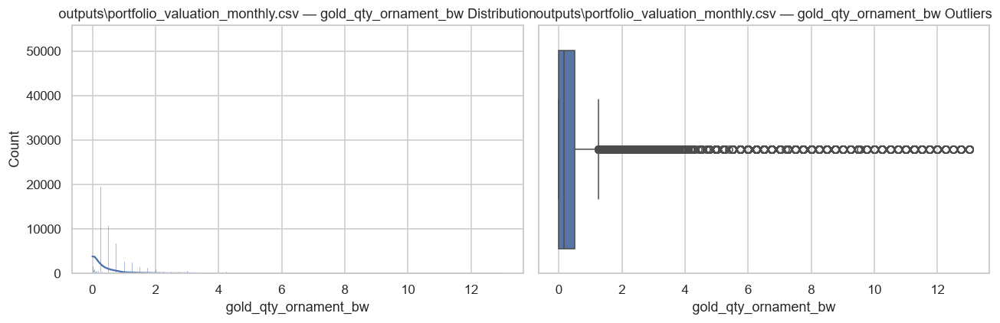

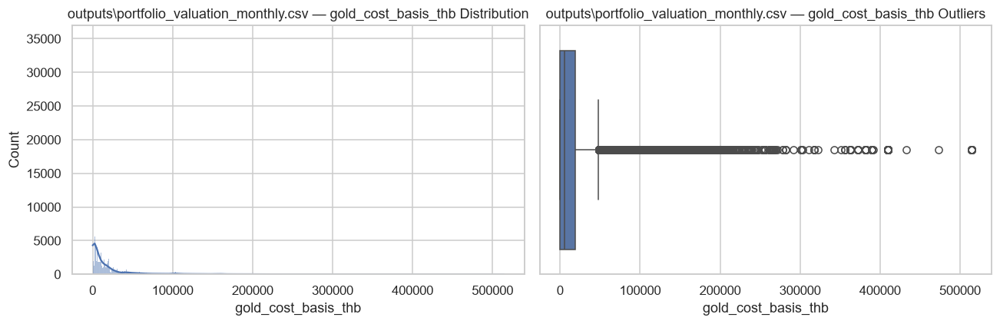

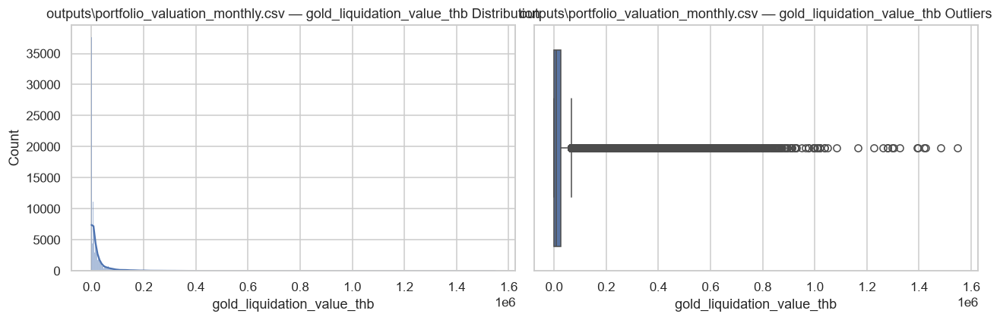


outputs\portfolio_valuation_monthly.parquet: (117356, 18)


,portfolio_id,valuation_date,calendar_year,cash_balance_thb,gold_qty_bar_bw,gold_qty_ornament_bw,gold_cost_basis_thb,gold_liquidation_value_thb,portfolio_equity_thb,net_contributed_capital_thb,cumulative_realized_pnl_thb,unrealized_pnl_thb,cumulative_transaction_cost_thb,cumulative_net_pnl_thb,valuation_price_timestamp,valuation_quality_flag,simulation_run_id,is_synthetic
0,P20060001,2006-06-30,2006,6000.0,0.0,0.0,0.0,0.0,6000.0,6000.0,0.0,0.0,0.0,0.0,2006-06-30,OK,R001,True
1,P20060001,2006-07-31,2006,6000.0,0.0,0.0,0.0,0.0,6000.0,6000.0,0.0,0.0,0.0,0.0,2006-07-31,OK,R001,True
2,P20060001,2006-08-31,2006,6000.0,0.0,0.0,0.0,0.0,6000.0,6000.0,0.0,0.0,0.0,0.0,2006-08-31,OK,R001,True
3,P20060001,2006-09-30,2006,6000.0,0.0,0.0,0.0,0.0,6000.0,6000.0,0.0,0.0,0.0,0.0,2006-09-30,OK,R001,True
4,P20060001,2006-10-31,2006,6000.0,0.0,0.0,0.0,0.0,6000.0,6000.0,0.0,0.0,0.0,0.0,2006-10-31,OK,R001,True


,count,mean,std,min,25%,50%,75%,max
calendar_year,117356.0,2019.411619,4.997799,2006.000000,2016.000000,2020.000,2024.000000,2.026000e+03
cash_balance_thb,117356.0,17448.567239,22656.034021,0.000000,6037.470000,10650.650,21812.210800,6.674039e+05
gold_qty_bar_bw,117356.0,0.385846,1.342831,0.000000,0.000000,0.000,0.000000,2.000000e+01
gold_qty_ornament_bw,117356.0,0.564478,1.348093,0.000000,0.000000,0.160,0.500000,1.300000e+01
gold_cost_basis_thb,117356.0,19998.820540,38652.708597,0.000000,72.958314,5650.000,19375.000000,5.141500e+05
gold_liquidation_value_thb,117356.0,30745.979501,71051.151712,0.000000,101.912181,8500.000,27200.801784,1.548000e+06
portfolio_equity_thb,117356.0,48194.546740,75848.799609,0.000000,11823.100000,24749.215,50772.754538,1.600085e+06
net_contributed_capital_thb,117356.0,36639.599551,45116.729406,-70400.000000,10399.640000,21829.150,42253.407500,5.758720e+05
cumulative_realized_pnl_thb,117356.0,807.788228,4774.072169,-25980.515221,0.000000,0.000,10.156250,2.370520e+05
unrealized_pnl_thb,117356.0,10747.158961,39313.921959,-71725.000000,0.000000,525.000,6137.522192,1.137950e+06


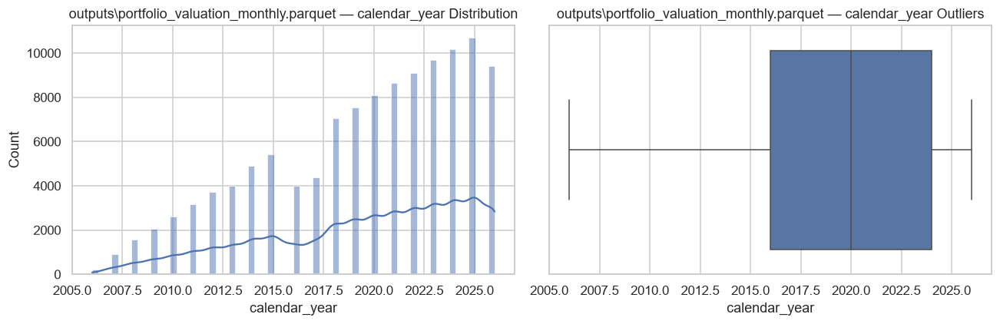

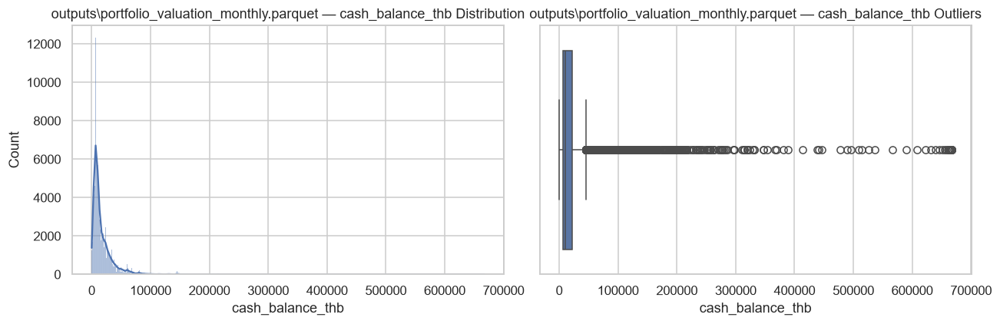

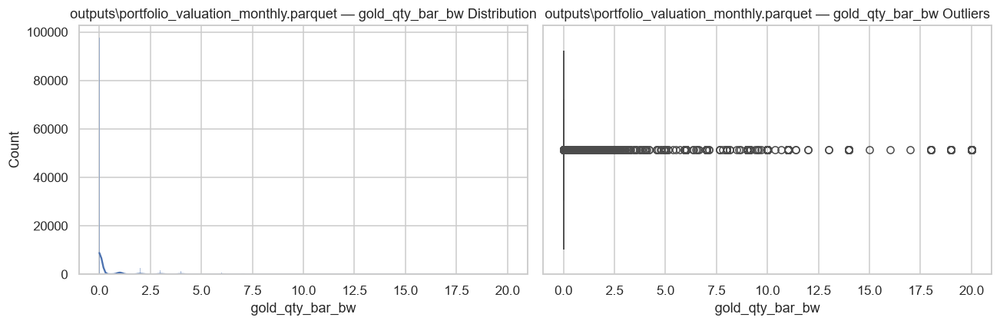

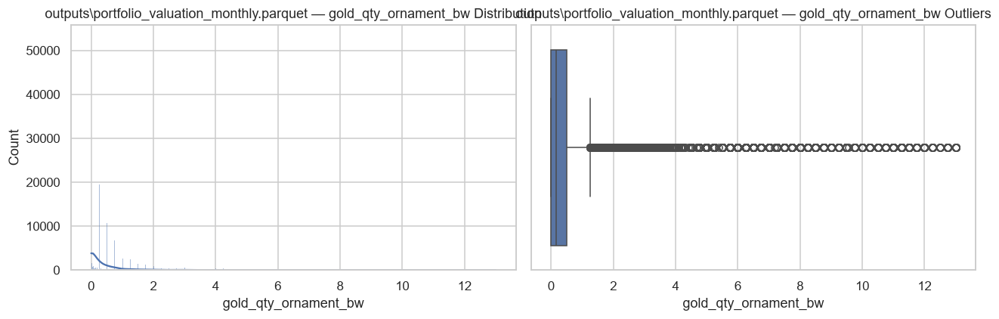

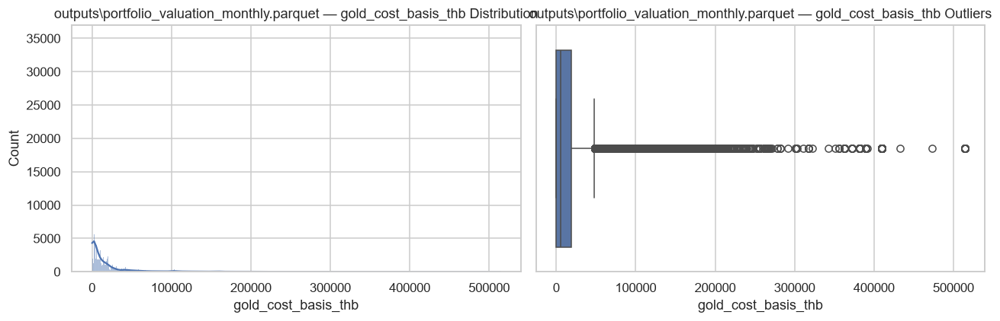

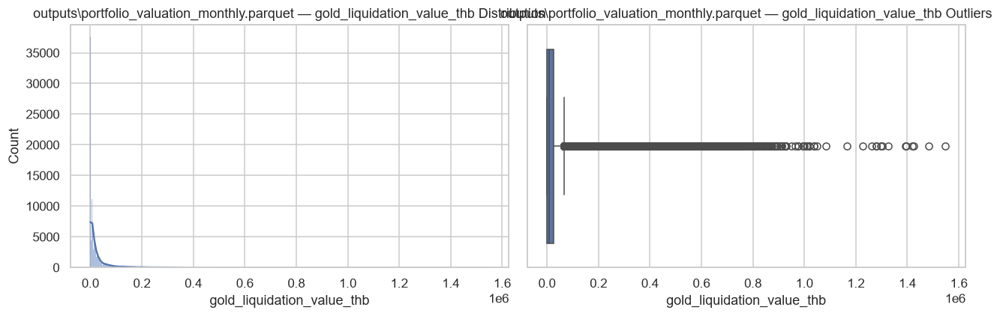


outputs\portfolio_yearly.csv: (10845, 27)


,portfolio_id,cohort_start_year,calendar_year,is_partial_year,year_start_date,year_end_date,beginning_equity_thb,ending_equity_thb,external_contributions_thb,external_withdrawals_thb,purchase_count,sale_count,gross_purchase_value_thb,gross_sale_value_thb,transaction_cost_thb,realized_pnl_thb,unrealized_pnl_thb,net_pnl_thb,annual_return,max_drawdown,data_coverage_ratio,calculation_quality_flag,benchmark_id,simulation_run_id,is_synthetic,benchmark_cum_net_pnl_thb,cum_net_pnl_thb
0,P20060001,2006,2006,True,2006-06-08,2006-12-30,0.0,6000.0,6000.0,0.0,0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,OK,BH_BAR_SAME_FLOWS,R001,True,-342.105263,0.0
1,P20060001,2006,2007,False,2007-01-01,2007-12-29,6000.0,6000.0,0.0,0.0,0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,OK,BH_BAR_SAME_FLOWS,R001,True,947.368421,0.0
2,P20060001,2006,2008,False,2008-01-01,2008-12-30,6000.0,6000.0,0.0,0.0,0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,OK,BH_BAR_SAME_FLOWS,R001,True,1315.789474,0.0
3,P20060001,2006,2009,False,2009-01-01,2009-12-30,6000.0,6000.0,0.0,0.0,0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,OK,BH_BAR_SAME_FLOWS,R001,True,3078.947368,0.0
4,P20060001,2006,2010,False,2010-01-01,2010-12-30,6000.0,6000.0,0.0,0.0,0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,OK,BH_BAR_SAME_FLOWS,R001,True,4552.631579,0.0


,count,mean,std,min,25%,50%,75%,max
cohort_start_year,10845.0,2012.680037,5.097968,2006.000000,2008.000000,2012.000000,2016.000000,2.026000e+03
calendar_year,10845.0,2019.229691,5.089687,2006.000000,2016.000000,2020.000000,2024.000000,2.026000e+03
beginning_equity_thb,10845.0,40989.729253,67067.017678,0.000000,9302.060000,21056.802500,44614.730000,1.347085e+06
ending_equity_thb,10845.0,49062.572535,78916.569548,0.000000,11665.772650,24686.510055,51702.100000,1.362085e+06
external_contributions_thb,10845.0,4821.695076,19366.157151,0.000000,0.000000,0.000000,0.000000,5.448720e+05
external_withdrawals_thb,10845.0,342.258898,5735.723517,0.000000,0.000000,0.000000,0.000000,3.641069e+05
purchase_count,10845.0,0.410143,1.114344,0.000000,0.000000,0.000000,0.000000,1.200000e+01
sale_count,10845.0,1.280682,2.767946,0.000000,0.000000,0.000000,1.000000,1.200000e+01
gross_purchase_value_thb,10845.0,5423.299908,19876.097810,0.000000,0.000000,0.000000,0.000000,5.439500e+05
gross_sale_value_thb,10845.0,3304.773088,17325.513495,0.000000,0.000000,0.000000,0.057152,4.993516e+05


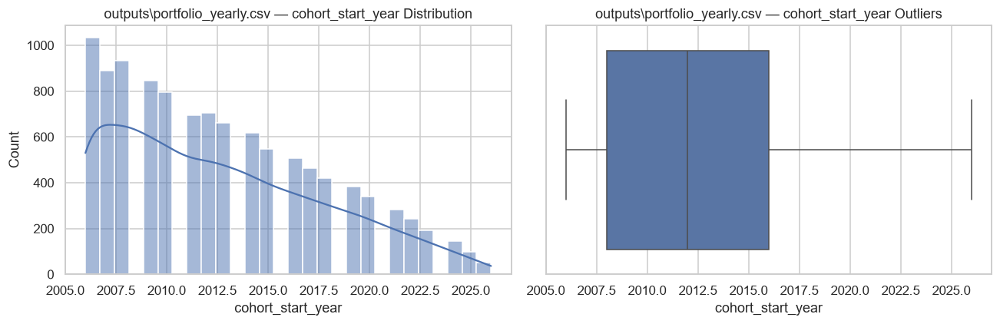

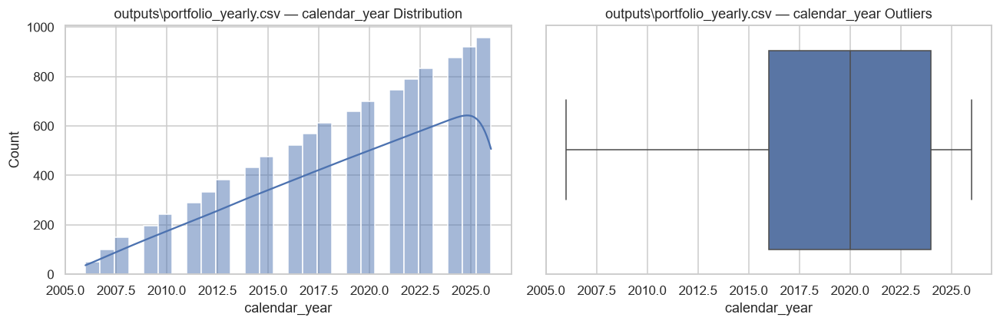

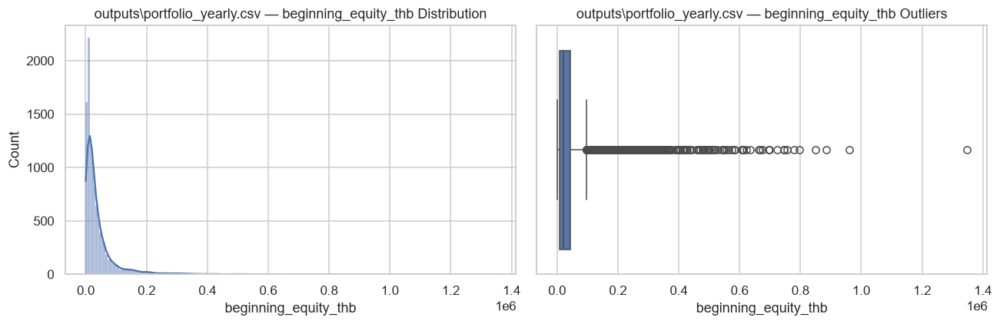

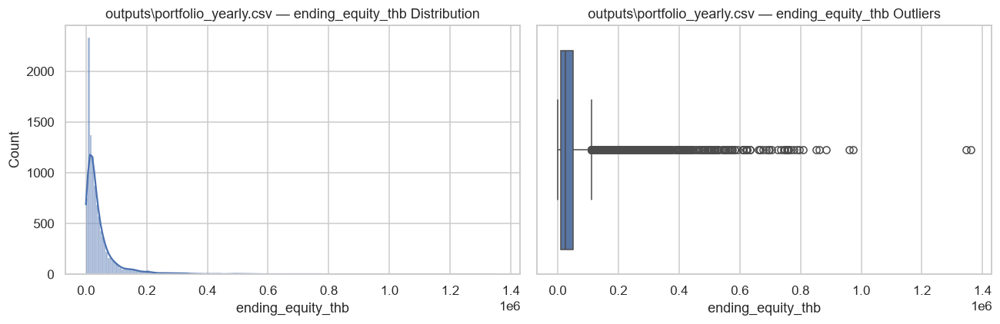

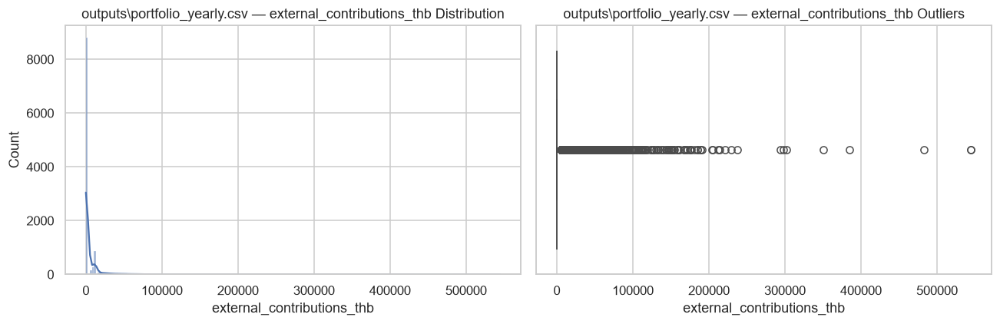

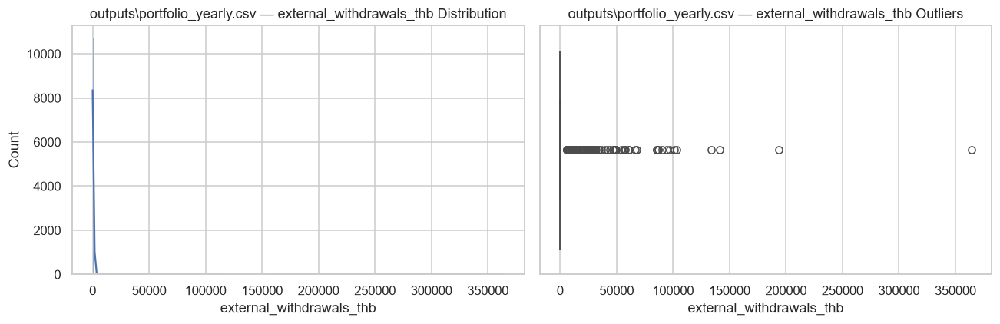


outputs\portfolio_yearly.parquet: (10845, 27)


,portfolio_id,cohort_start_year,calendar_year,is_partial_year,year_start_date,year_end_date,beginning_equity_thb,ending_equity_thb,external_contributions_thb,external_withdrawals_thb,purchase_count,sale_count,gross_purchase_value_thb,gross_sale_value_thb,transaction_cost_thb,realized_pnl_thb,unrealized_pnl_thb,net_pnl_thb,annual_return,max_drawdown,data_coverage_ratio,calculation_quality_flag,benchmark_id,simulation_run_id,is_synthetic,benchmark_cum_net_pnl_thb,cum_net_pnl_thb
0,P20060001,2006,2006,True,2006-06-08,2006-12-30,0.0,6000.0,6000.0,0.0,0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,OK,BH_BAR_SAME_FLOWS,R001,True,-342.105263,0.0
1,P20060001,2006,2007,False,2007-01-01,2007-12-29,6000.0,6000.0,0.0,0.0,0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,OK,BH_BAR_SAME_FLOWS,R001,True,947.368421,0.0
2,P20060001,2006,2008,False,2008-01-01,2008-12-30,6000.0,6000.0,0.0,0.0,0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,OK,BH_BAR_SAME_FLOWS,R001,True,1315.789474,0.0
3,P20060001,2006,2009,False,2009-01-01,2009-12-30,6000.0,6000.0,0.0,0.0,0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,OK,BH_BAR_SAME_FLOWS,R001,True,3078.947368,0.0
4,P20060001,2006,2010,False,2010-01-01,2010-12-30,6000.0,6000.0,0.0,0.0,0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,OK,BH_BAR_SAME_FLOWS,R001,True,4552.631579,0.0


,count,mean,std,min,25%,50%,75%,max
cohort_start_year,10845.0,2012.680037,5.097968,2006.000000,2008.000000,2012.000000,2016.000000,2.026000e+03
calendar_year,10845.0,2019.229691,5.089687,2006.000000,2016.000000,2020.000000,2024.000000,2.026000e+03
beginning_equity_thb,10845.0,40989.729253,67067.017678,0.000000,9302.060000,21056.802500,44614.730000,1.347085e+06
ending_equity_thb,10845.0,49062.572535,78916.569548,0.000000,11665.772650,24686.510055,51702.100000,1.362085e+06
external_contributions_thb,10845.0,4821.695076,19366.157151,0.000000,0.000000,0.000000,0.000000,5.448720e+05
external_withdrawals_thb,10845.0,342.258898,5735.723517,0.000000,0.000000,0.000000,0.000000,3.641069e+05
purchase_count,10845.0,0.410143,1.114344,0.000000,0.000000,0.000000,0.000000,1.200000e+01
sale_count,10845.0,1.280682,2.767946,0.000000,0.000000,0.000000,1.000000,1.200000e+01
gross_purchase_value_thb,10845.0,5423.299908,19876.097810,0.000000,0.000000,0.000000,0.000000,5.439500e+05
gross_sale_value_thb,10845.0,3304.773088,17325.513495,0.000000,0.000000,0.000000,0.057152,4.993516e+05


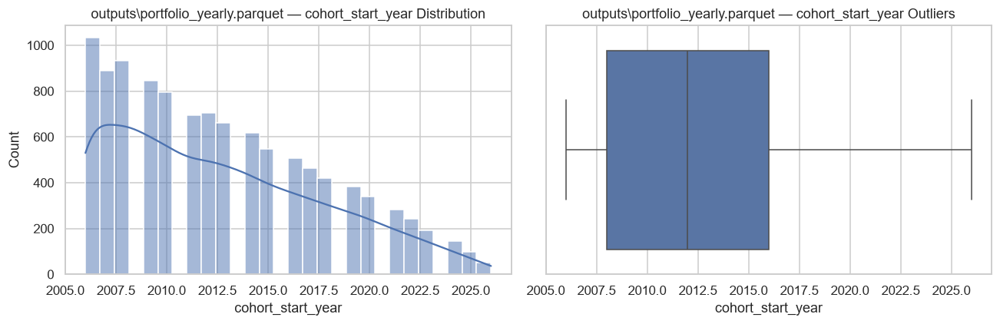

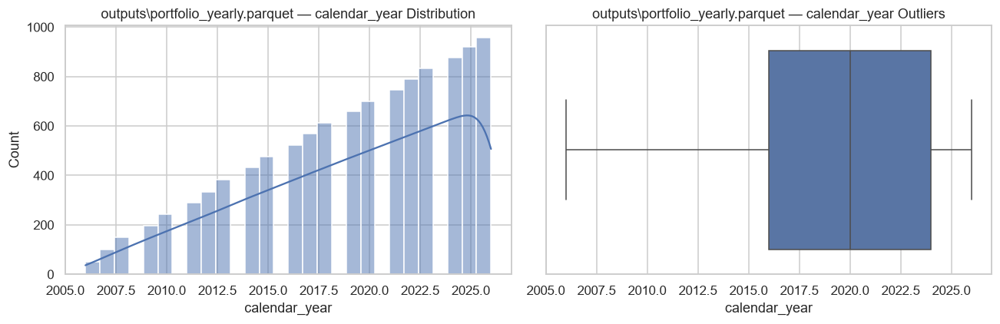

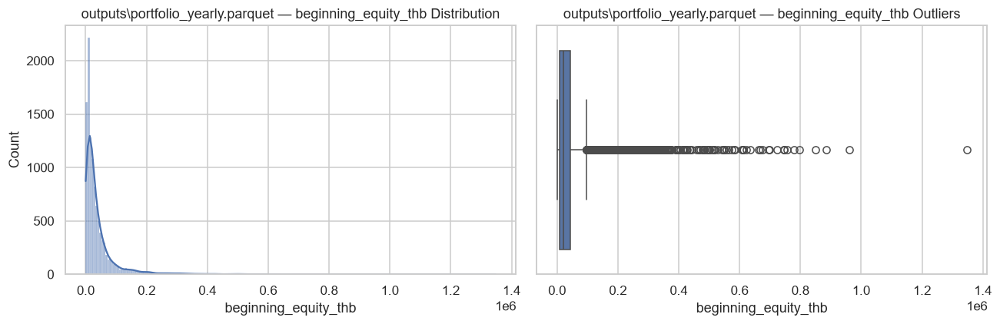

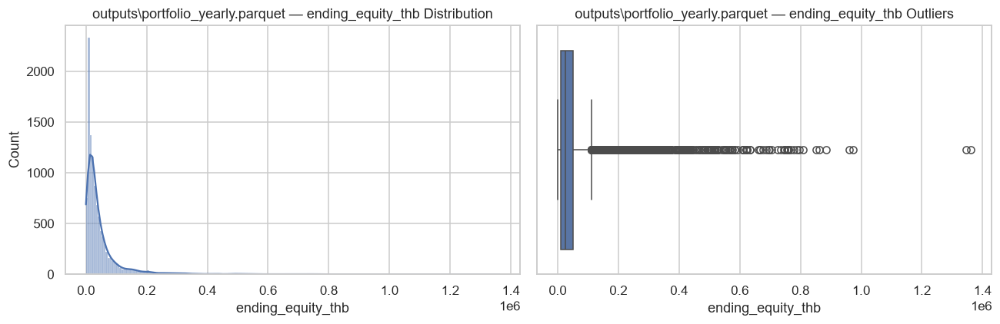

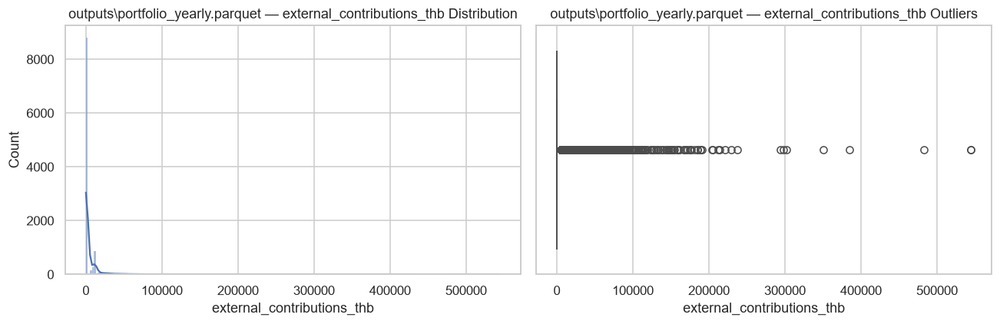

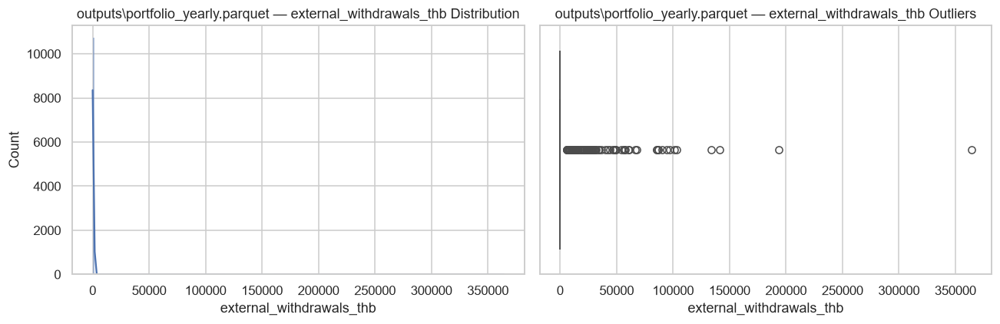


outputs\sensitivity_analysis.csv: (6, 8)


,variant,n_portfolios,mean_annual_return,loss_year_share,loss_lifetime_share,median_lifetime_pnl_thb,mean_costs_frac_gross,tx_per_portfolio
0,base,200,0.047912,0.175990,0.055,75.000000,0.0,13.465
1,capital_low,200,0.036497,0.133250,0.025,10.717987,0.0,9.505
2,capital_high,200,0.055824,0.189818,0.065,225.000000,0.0,16.830
3,behavior_dip_heavy,200,0.047979,0.174247,0.060,83.038330,0.0,14.400
4,ornament_wage_high,200,0.046634,0.178504,0.055,75.000000,0.0,13.400


,count,mean,std,min,25%,50%,75%,max
n_portfolios,6.0,200.000000,0.000000,200.000000,200.000000,200.000000,200.000000,200.000000
mean_annual_return,6.0,0.047330,0.006229,0.036497,0.046953,0.047945,0.048845,0.055824
loss_year_share,6.0,0.170671,0.019348,0.133250,0.172726,0.175119,0.177876,0.189818
loss_lifetime_share,6.0,0.050833,0.014289,0.025000,0.047500,0.055000,0.058750,0.065000
median_lifetime_pnl_thb,6.0,90.626053,71.037667,10.717987,75.000000,75.000000,81.028748,225.000000
mean_costs_frac_gross,6.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
tx_per_portfolio,6.0,13.515000,2.360885,9.505000,13.416250,13.477500,14.172500,16.830000


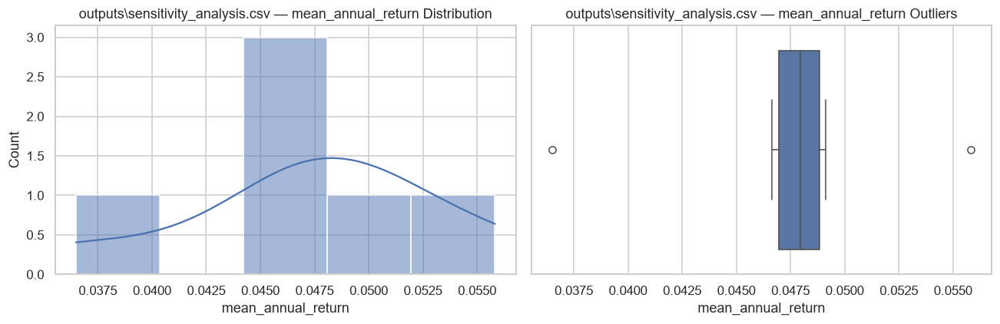

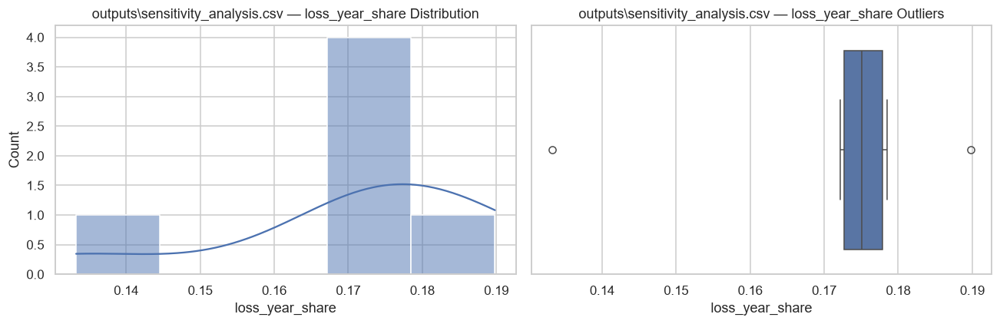

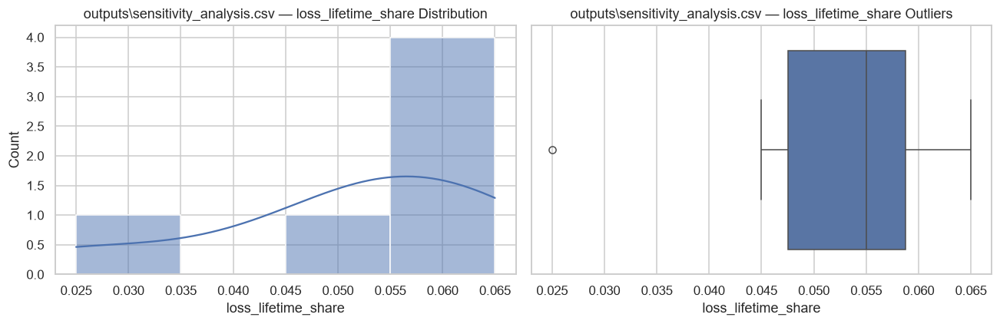

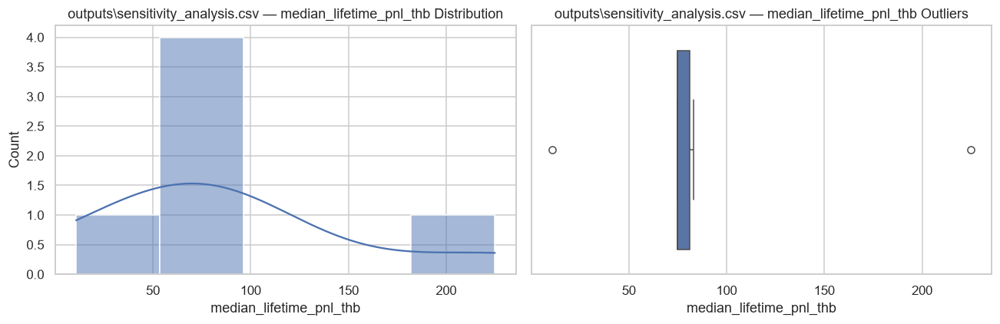


outputs\transaction_ledger.csv: (40089, 22)


,transaction_id,portfolio_id,event_timestamp,calendar_year,event_type,gold_product_type,side,requested_quantity_bw,executed_quantity_bw,price_quote_timestamp,customer_execution_price_thb_per_bw,gross_amount_thb,transaction_cost_thb,net_cash_change_thb,realized_pnl_thb,execution_status,rejection_reason,behavior_scenario,parameter_set_id,simulation_run_id,is_synthetic,source_quote_id
0,P20060001-T00000,P20060001,2006-07-28,2006,GOLD_PURCHASE,bar,BUY,0.251101,0.0,2006-07-28,11350.0,0.0,0.0,0.0,0.0,REJECTED,BELOW_MIN_TRADE_UNIT,buy_momentum,PS_R001,R001,True,GTA:2006-07-28
1,P20060001-T00000,P20060001,2006-08-14,2006,GOLD_PURCHASE,bar,BUY,0.252212,0.0,2006-08-14,11300.0,0.0,0.0,0.0,0.0,REJECTED,BELOW_MIN_TRADE_UNIT,buy_momentum,PS_R001,R001,True,GTA:2006-08-14
2,P20060001-T00000,P20060001,2006-11-27,2006,GOLD_PURCHASE,bar,BUY,0.257919,0.0,2006-11-27,11050.0,0.0,0.0,0.0,0.0,REJECTED,BELOW_MIN_TRADE_UNIT,buy_momentum,PS_R001,R001,True,GTA:2006-11-27
3,P20060001-T00000,P20060001,2007-02-24,2007,GOLD_PURCHASE,bar,BUY,0.248908,0.0,2007-02-24,11450.0,0.0,0.0,0.0,0.0,REJECTED,BELOW_MIN_TRADE_UNIT,buy_momentum,PS_R001,R001,True,GTA:2007-02-24
4,P20060001-T00000,P20060001,2007-03-07,2007,GOLD_PURCHASE,bar,BUY,0.262673,0.0,2007-03-07,10850.0,0.0,0.0,0.0,0.0,REJECTED,BELOW_MIN_TRADE_UNIT,buy_momentum,PS_R001,R001,True,GTA:2007-03-07


,count,mean,std,min,25%,50%,75%,max
calendar_year,40089.0,2019.436604,5.209905,2.006000e+03,2015.000000,2021.000000,2024.000000,2026.00
requested_quantity_bw,37648.0,0.200980,0.325771,2.525521e-10,0.021942,0.119683,0.247454,12.75
executed_quantity_bw,40089.0,0.088093,0.291618,0.000000e+00,0.000000,0.000000,0.011124,12.75
customer_execution_price_thb_per_bw,37648.0,31807.714885,15688.651732,1.035000e+04,20200.000000,26800.000000,35100.000000,81050.00
gross_amount_thb,40089.0,2361.145243,8555.750332,0.000000e+00,0.000000,0.000000,300.338745,389512.50
transaction_cost_thb,40089.0,0.000000,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.00
net_cash_change_thb,40089.0,-573.110413,8857.061924,-3.895125e+05,0.000000,0.000000,0.620077,228000.00
realized_pnl_thb,40089.0,78.226990,945.284786,-5.650000e+03,0.000000,0.000000,0.000754,70400.00


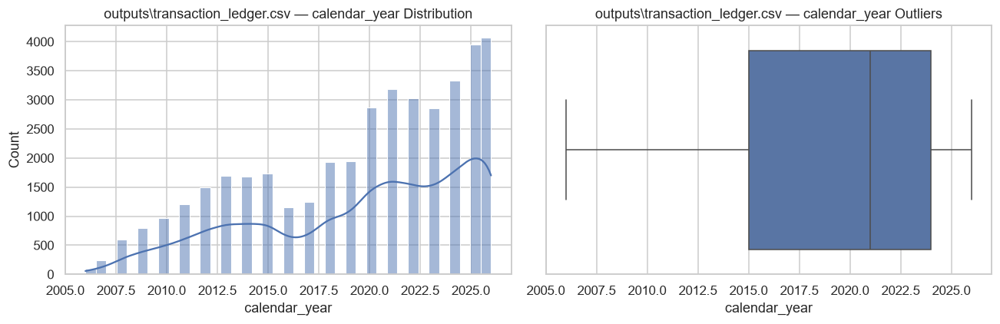

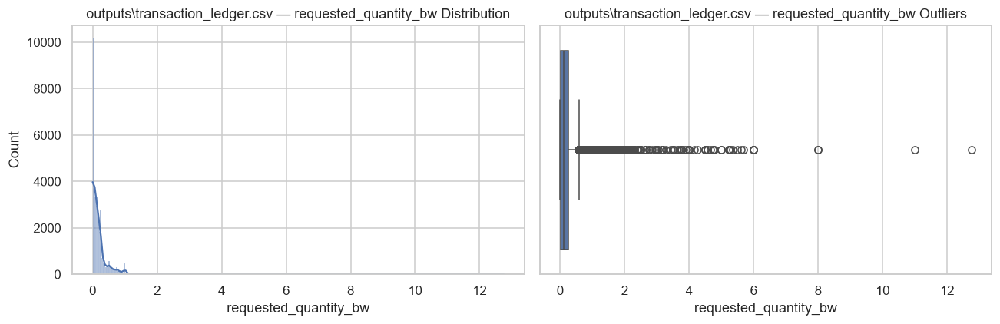

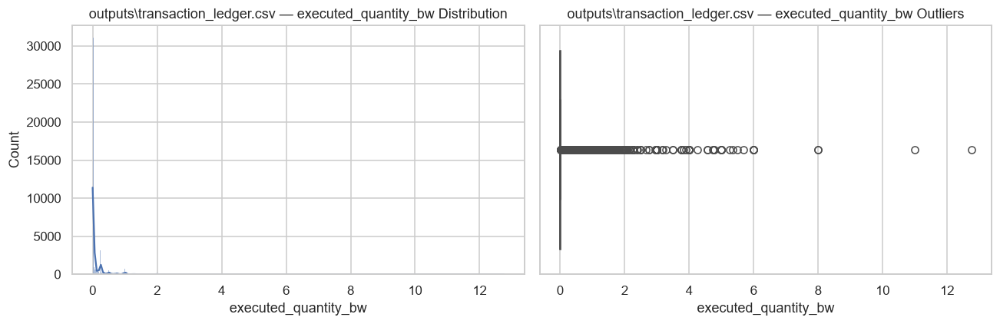

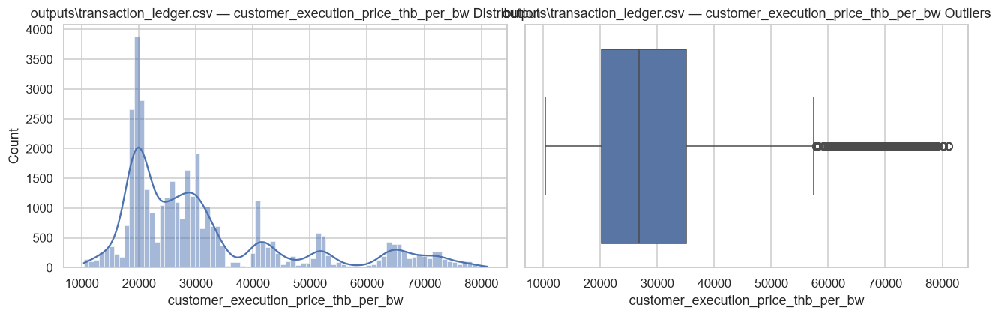

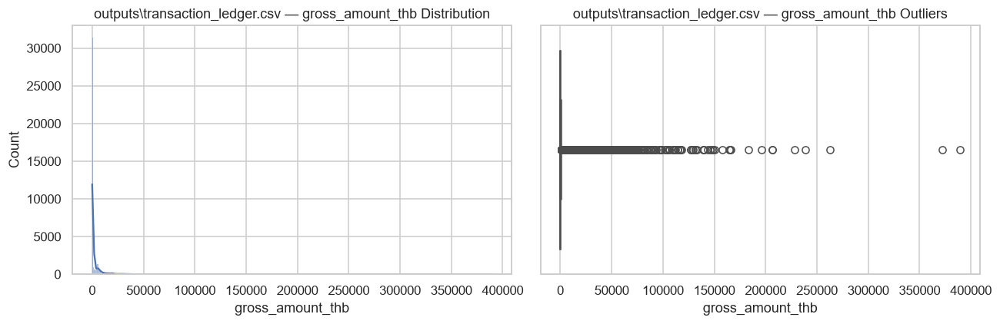


outputs\transaction_ledger.parquet: (40089, 22)


,transaction_id,portfolio_id,event_timestamp,calendar_year,event_type,gold_product_type,side,requested_quantity_bw,executed_quantity_bw,price_quote_timestamp,customer_execution_price_thb_per_bw,gross_amount_thb,transaction_cost_thb,net_cash_change_thb,realized_pnl_thb,execution_status,rejection_reason,behavior_scenario,parameter_set_id,simulation_run_id,is_synthetic,source_quote_id
0,P20060001-T00000,P20060001,2006-07-28,2006,GOLD_PURCHASE,bar,BUY,0.251101,0.0,2006-07-28,11350.0,0.0,0.0,0.0,0.0,REJECTED,BELOW_MIN_TRADE_UNIT,buy_momentum,PS_R001,R001,True,GTA:2006-07-28
1,P20060001-T00000,P20060001,2006-08-14,2006,GOLD_PURCHASE,bar,BUY,0.252212,0.0,2006-08-14,11300.0,0.0,0.0,0.0,0.0,REJECTED,BELOW_MIN_TRADE_UNIT,buy_momentum,PS_R001,R001,True,GTA:2006-08-14
2,P20060001-T00000,P20060001,2006-11-27,2006,GOLD_PURCHASE,bar,BUY,0.257919,0.0,2006-11-27,11050.0,0.0,0.0,0.0,0.0,REJECTED,BELOW_MIN_TRADE_UNIT,buy_momentum,PS_R001,R001,True,GTA:2006-11-27
3,P20060001-T00000,P20060001,2007-02-24,2007,GOLD_PURCHASE,bar,BUY,0.248908,0.0,2007-02-24,11450.0,0.0,0.0,0.0,0.0,REJECTED,BELOW_MIN_TRADE_UNIT,buy_momentum,PS_R001,R001,True,GTA:2007-02-24
4,P20060001-T00000,P20060001,2007-03-07,2007,GOLD_PURCHASE,bar,BUY,0.262673,0.0,2007-03-07,10850.0,0.0,0.0,0.0,0.0,REJECTED,BELOW_MIN_TRADE_UNIT,buy_momentum,PS_R001,R001,True,GTA:2007-03-07


,count,mean,std,min,25%,50%,75%,max
calendar_year,40089.0,2019.436604,5.209905,2.006000e+03,2015.000000,2021.000000,2024.000000,2026.00
requested_quantity_bw,37648.0,0.200980,0.325771,2.525521e-10,0.021942,0.119683,0.247454,12.75
executed_quantity_bw,40089.0,0.088093,0.291618,0.000000e+00,0.000000,0.000000,0.011124,12.75
customer_execution_price_thb_per_bw,37648.0,31807.714885,15688.651732,1.035000e+04,20200.000000,26800.000000,35100.000000,81050.00
gross_amount_thb,40089.0,2361.145243,8555.750332,0.000000e+00,0.000000,0.000000,300.338745,389512.50
transaction_cost_thb,40089.0,0.000000,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.00
net_cash_change_thb,40089.0,-573.110413,8857.061924,-3.895125e+05,0.000000,0.000000,0.620077,228000.00
realized_pnl_thb,40089.0,78.226990,945.284786,-5.650000e+03,0.000000,0.000000,0.000754,70400.00


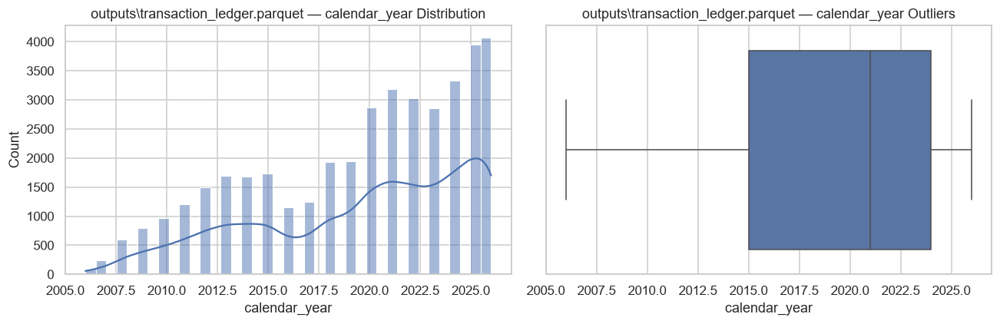

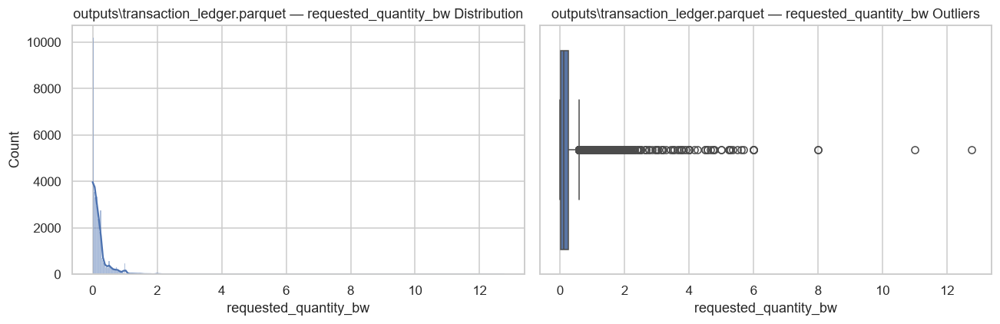

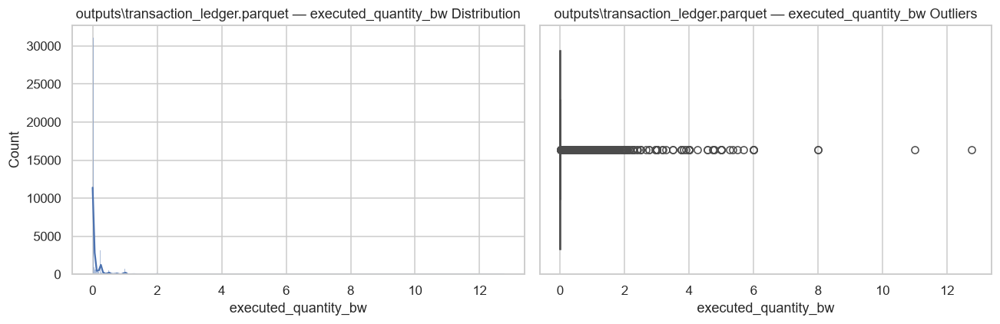

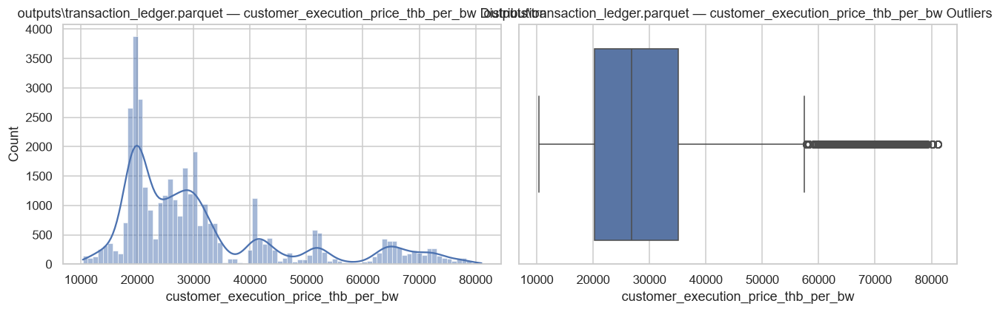

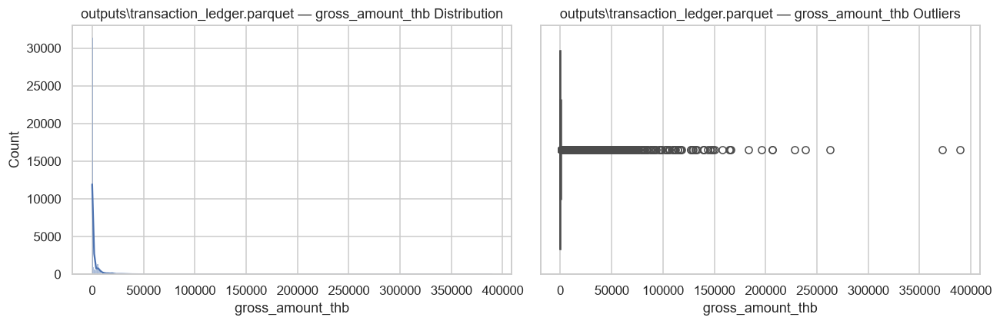

In [16]:
for group_name, candidates in [
    ("Transactions", transaction_candidates),
    ("Portfolio", portfolio_candidates),
    ("P&L", pnl_candidates),
]:
    print(f"\n### {group_name}")

    for name in candidates:
        df = datasets[name]

        print(f"\n{name}: {df.shape}")
        display(df.head(5))

        numeric_cols = df.select_dtypes(include=np.number).columns

        if len(numeric_cols):
            desc = df[numeric_cols].describe().T
            display(desc)

            for col in numeric_cols[:6]:
                values = pd.to_numeric(df[col], errors="coerce").dropna()

                if values.nunique() <= 1:
                    continue

                fig, axes = plt.subplots(1, 2, figsize=(12, 4))

                sns.histplot(values, kde=True, ax=axes[0])
                axes[0].set_title(f"{name} — {col} Distribution")

                sns.boxplot(x=values, ax=axes[1])
                axes[1].set_title(f"{name} — {col} Outliers")

                plt.tight_layout()
                plt.show()

In [17]:
for name in pnl_candidates + portfolio_candidates:
    df = datasets[name]

    print("\nDataset:", name)

    for col in df.columns:
        if any(
            k in str(col).lower()
            for k in [
                "cash", "market_value", "realized", "unrealized",
                "pnl", "equity", "cost", "fee", "attribution"
            ]
        ):
            print(f"  {col}: {df[col].dtype}")


Dataset: outputs\pnl_attribution_yearly.csv
  pnl_total_thb: float64
  transaction_cost_effect_thb: float64
  product_cost_effect_thb: float64
  attribution_method: str
  attribution_quality_flag: str

Dataset: outputs\pnl_attribution_yearly.parquet
  pnl_total_thb: float64
  transaction_cost_effect_thb: float64
  product_cost_effect_thb: float64
  attribution_method: str
  attribution_quality_flag: str

Dataset: outputs\portfolio_valuation_monthly.csv
  cash_balance_thb: float64
  gold_cost_basis_thb: float64
  portfolio_equity_thb: float64
  cumulative_realized_pnl_thb: float64
  unrealized_pnl_thb: float64
  cumulative_transaction_cost_thb: float64
  cumulative_net_pnl_thb: float64

Dataset: outputs\portfolio_valuation_monthly.parquet
  cash_balance_thb: float64
  gold_cost_basis_thb: float64
  portfolio_equity_thb: float64
  cumulative_realized_pnl_thb: float64
  unrealized_pnl_thb: float64
  cumulative_transaction_cost_thb: float64
  cumulative_net_pnl_thb: float64

Dataset: outp